data cleaning

In [ ]:
import pandas as pd
from google.colab import files


uploaded = files.upload()
df = pd.read_excel(next(iter(uploaded)), sheet_name="data", dtype=object)


countries = [
    "Belize", "Costa Rica", "Dominican Republic", "El Salvador",
    "Guatemala", "Haiti", "Honduras", "Mexico", "Nicaragua", "Panama"
]

north_america = df.loc[df["Country"].str.strip().isin(countries)].copy()
north_america["Continent"] = "North America"

output = "Malaria_North_America_Only.xlsx"
north_america.to_excel(output, sheet_name="North America Data", index=False)
files.download(output)

Saving Malaria_Global data.xlsx to Malaria_Global data.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EDA

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import warnings
warnings.filterwarnings('ignore')

uploaded = files.upload()
file_name = next(iter(uploaded))


df = pd.read_excel(
    file_name,
    sheet_name="North America Data"
)

df.columns = df.columns.str.strip()


df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Malaria cases'] = pd.to_numeric(
    df['Malaria cases'], errors='coerce'
)

df = df.dropna(
    subset=['Country', 'Year', 'Malaria cases']
)

df['Year'] = df['Year'].astype(int)
df['Malaria cases'] = df['Malaria cases'].astype(int)

df = df.sort_values(['Country', 'Year'])

print("Dataset successfully loaded!")
print("Shape:", df.shape)
print("Countries:", df['Country'].nunique())
print("Year range:", df['Year'].min(), "-", df['Year'].max())

df.head()


Saving north america.xlsx to north america.xlsx
Dataset successfully loaded!
Shape: (230, 32)
Countries: 10
Year range: 2000 - 2022


,Continent,Country,Year,Malaria cases,Malaria deaths,Malaria incidence,Malaria mortality,Indigenous cases,P. falciparum,P. vivax,...,y13,y14,y15,y16,y17,y18,y19,y20,y21,y22
0,North America,Belize,2000,1486,0,8.94,0.00,0,0,0,...,6.532223,87,82.44,33.033333,70.34421,24.4,27.200676,0.0,0.0,0.0
1,North America,Belize,2001,1162,0,6.78,0.00,0,0,0,...,6.532223,88,82.76,33.233333,46.57054,0.0,26.993296,0.0,0.0,0.0
2,North America,Belize,2002,1134,0,6.42,0.00,0,0,0,...,6.532223,89,83.09,33.433333,46.57054,0.0,26.520278,0.0,0.0,0.0
3,North America,Belize,2003,1324,0,7.27,0.00,0,0,0,...,6.532223,89,83.41,33.700000,46.57054,0.0,25.906236,0.0,0.0,0.0
4,North America,Belize,2004,1066,1,5.69,0.53,0,0,0,...,6.532223,90,83.74,34.033333,46.57054,0.0,25.275788,0.0,0.0,0.0


descriptive

In [ ]:

cases = df['Malaria cases']
print("Mean:", cases.mean())
print("Variance:", cases.var())
print("Standard Deviation:", cases.std())
print("Minimum:", cases.min())
print("Maximum:", cases.max())
print("Median:", cases.median())

print("\nComplete Statistical Summary:")
print(cases.describe())


Mean: 10566.052173913044
Variance: 405125550.98416585
Standard Deviation: 20127.73089506529
Minimum: 0
Maximum: 89554
Median: 1526.0

Complete Statistical Summary:
count      230.000000
mean     10566.052174
std      20127.730895
min          0.000000
25%        443.750000
50%       1526.000000
75%       8380.250000
max      89554.000000
Name: Malaria cases, dtype: float64


## Total malaria cases by year

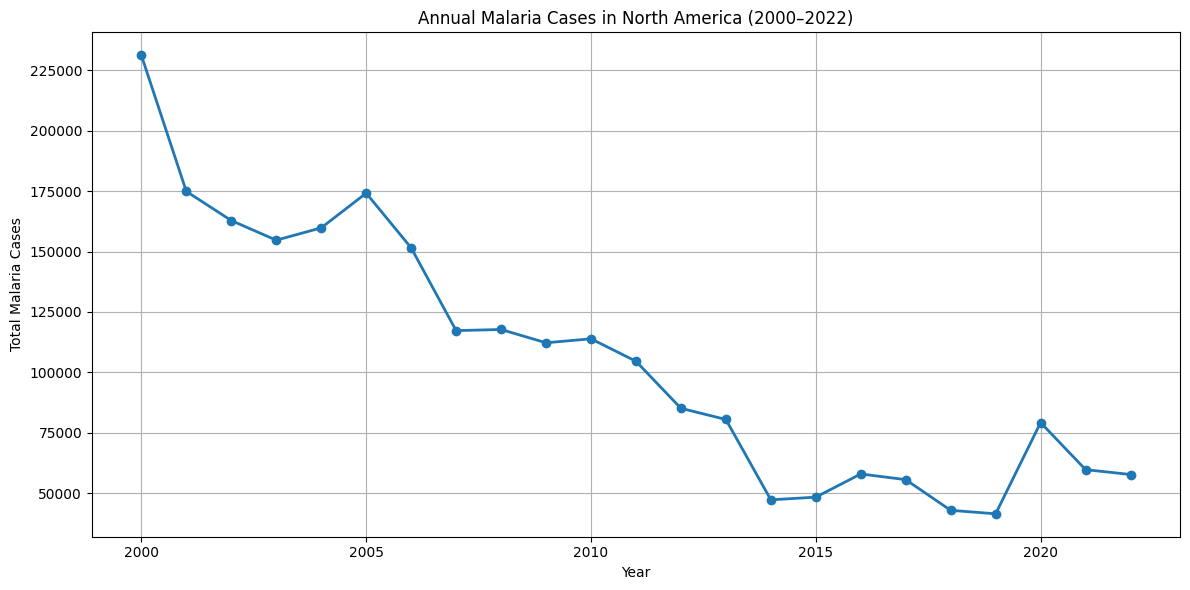

In [ ]:
df.groupby('Year')['Malaria cases'].sum().plot(figsize=(12,6), marker='o', linewidth=2, title='Annual Malaria Cases in North America (2000–2022)', grid=True)
plt.xlabel('Year')
plt.ylabel('Total Malaria Cases')
plt.tight_layout()
plt.show()


# **Country-wise temporal trend**


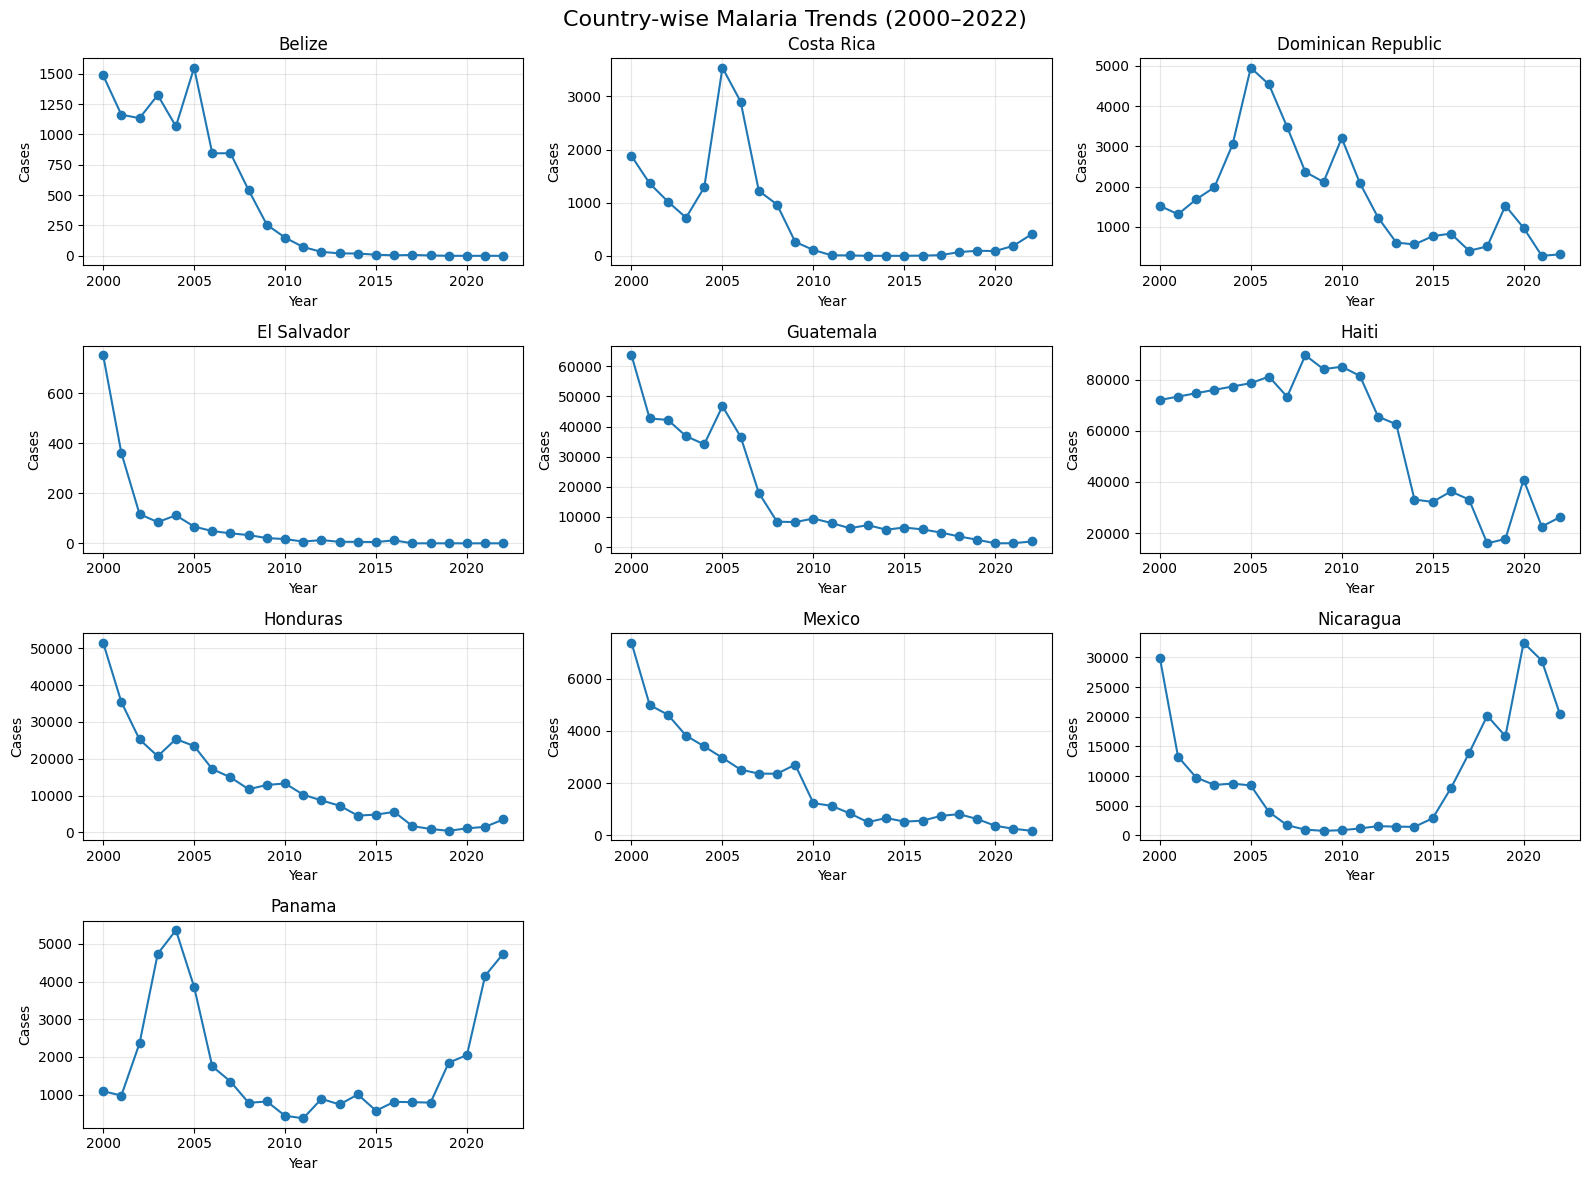

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12))

for ax, (country, data) in zip(axes.flatten(), df.groupby('Country')):
    ax.plot(data['Year'], data['Malaria cases'], marker='o')
    ax.set_title(country)
    ax.set_xlabel('Year')
    ax.set_ylabel('Cases')
    ax.grid(alpha=0.3)

for ax in axes.flatten()[df['Country'].nunique():]:
    ax.remove()

plt.suptitle('Country-wise Malaria Trends (2000–2022)', fontsize=16)
plt.tight_layout()
plt.show()

# **Distribution Analysis**

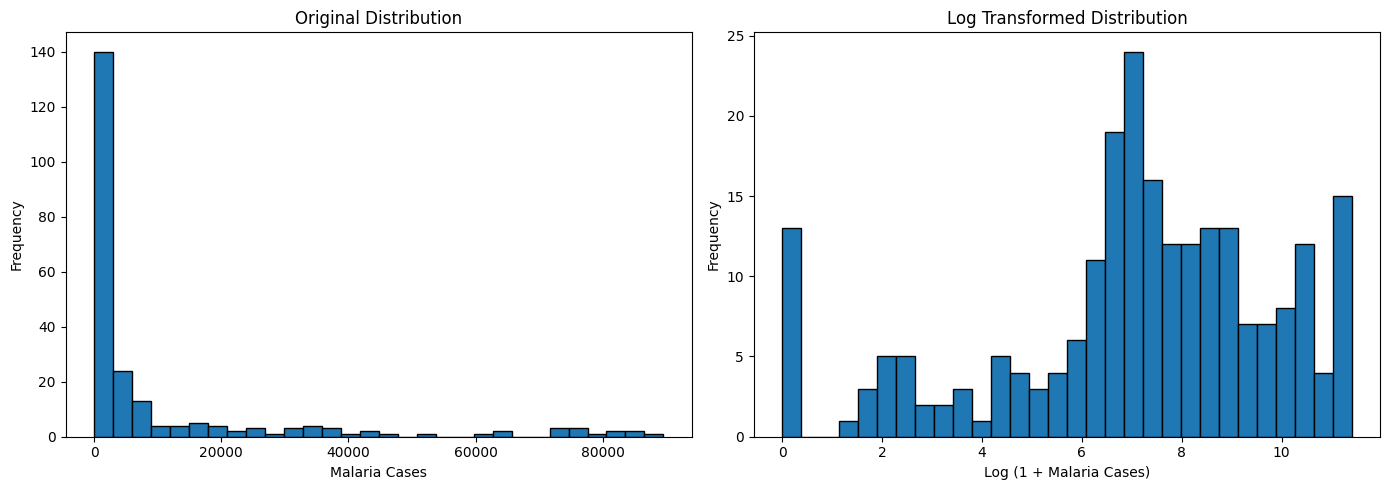

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, label in zip(
    axes,
    [df['Malaria cases'], np.log1p(df['Malaria cases'])],
    ['Original Distribution', 'Log Transformed Distribution'],
    ['Malaria Cases', 'Log (1 + Malaria Cases)']
):
    ax.hist(data, bins=30, edgecolor='black')
    ax.set(title=title, xlabel=label, ylabel='Frequency')

plt.tight_layout()
plt.show()


# **Zero Count Analysis**

In [ ]:
total_observations = len(df)
zero_count = (df['Malaria cases'] == 0).sum()
non_zero_count = (df['Malaria cases'] > 0).sum()
zero_percentage = (zero_count / total_observations) * 100
non_zero_percentage = (non_zero_count / total_observations) * 100
print("ZERO COUNT ANALYSIS")
print("Total Observations:", total_observations)
print("Zero Counts:", zero_count)
print("Non-Zero Counts:", non_zero_count)
print("Zero Percentage:", round(zero_percentage, 2), "%")
print("Non-Zero Percentage:", round(non_zero_percentage, 2), "%")


ZERO COUNT ANALYSIS
Total Observations: 230
Zero Counts: 13
Non-Zero Counts: 217
Zero Percentage: 5.65 %
Non-Zero Percentage: 94.35 %


Country-wise Zero Count

                    Total  Zero  Zero_Percentage
Country                                         
Belize                 23     4        17.391304
Costa Rica             23     3        13.043478
Dominican Republic     23     0         0.000000
El Salvador            23     6        26.086957
Guatemala              23     0         0.000000
Haiti                  23     0         0.000000
Honduras               23     0         0.000000
Mexico                 23     0         0.000000
Nicaragua              23     0         0.000000
Panama                 23     0         0.000000


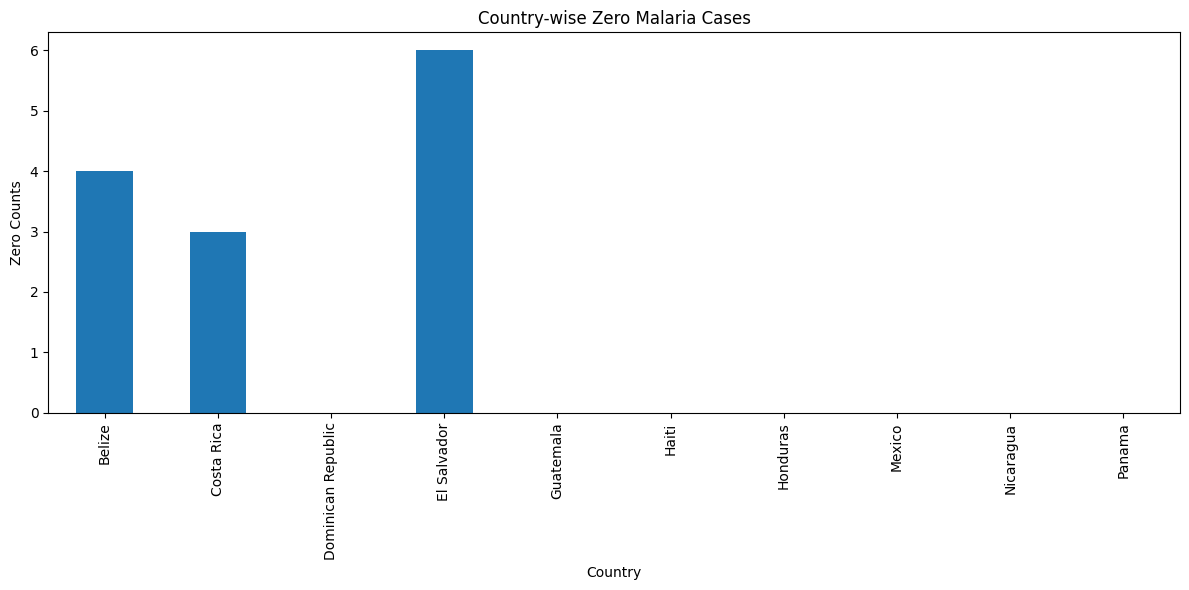

In [ ]:

zero = df.groupby('Country')['Malaria cases'].agg( Total='count',
    Zero=lambda x: (x == 0).sum()
)

zero['Zero_Percentage'] = zero['Zero'] / zero['Total'] * 100
print(zero)

zero['Zero'].plot(kind='bar', figsize=(12,6), title='Country-wise Zero Malaria Cases',
                  ylabel='Zero Counts')

plt.tight_layout()
plt.show()

# **Country-wise Mean and Variance**

In [ ]:
country_statistics = df.groupby('Country')['Malaria cases'].agg(
    Mean='mean',
    Variance='var',
    Standard_Deviation='std',
    Minimum='min',
    Maximum='max'
)
print(country_statistics)


                            Mean      Variance  Standard_Deviation  Minimum  \
Country                                                                       
Belize                457.521739  3.241734e+05          569.362232        0   
Costa Rica            702.521739  9.525073e+05          975.964785        0   
Dominican Republic   1753.869565  1.755014e+06         1324.769356      284   
El Salvador            74.130435  2.799485e+04          167.316604        0   
Guatemala           17469.782609  3.431967e+08        18525.568481     1240   
Haiti               57955.782609  6.350747e+08        25200.688832    16000   
Honduras            13150.173913  1.600122e+08        12649.591933      455   
Mexico               1976.391304  3.515656e+06         1875.008163      163   
Nicaragua           10280.347826  1.033408e+08        10165.669220      772   
Panama               1840.000000  2.478701e+06         1574.389232      372   

                    Maximum  
Country              

# **SIGNIFICANT PREDICTORS ANALYSIS**

In [ ]:
!pip -q install statsmodels openpyxl
import statsmodels.api as sm
import statsmodels.formula.api as smf

from google.colab import files
from statsmodels.stats.multitest import multipletests
import warnings

warnings.filterwarnings('ignore')




In [ ]:
# 3. Define variables
predictors = [
    'y1', 'y2', 'y3', 'y4', 'y5', 'y6',
    'y8', 'y9', 'y10', 'y11', 'y12', 'y13',
    'y14', 'y15', 'y16', 'y17', 'y18',
    'y19', 'y20', 'y21', 'y22'
]


# 5. Country and year control
df['Year_c'] = df['Year'] - df['Year'].mean()

print("\nDATA INFORMATION")
print("----------------")
print("Observations:", len(df))
print("Countries:", df['Country'].nunique())
print("Panama observations:", (df['Country'] == 'Panama').sum())



DATA INFORMATION
----------------
Observations: 230
Countries: 10
Panama observations: 23


In [ ]:
# 6. Variable names
variable_names = {
    'y1': 'Medical doctors per 10,000',
    'y2': 'Hospital bed density',
    'y3': 'Density of physicians',
    'y4': 'Pharmaceutical personnel density',
    'y5': 'Government health expenditure',
    'y6': 'Access to electricity',
    'y8': 'GDP growth',
    'y9': 'Population growth',
    'y10': 'Land area',
    'y11': 'Arable land',
    'y12': 'Agricultural land',
    'y13': 'Forest area',
    'y14': 'Basic drinking water services',
    'y15': 'Basic sanitation services',
    'y16': 'Hypertension prevalence',
    'y17': 'Life expectancy',
    'y18': 'Under-5 mortality',
    'y19': 'Air pollution',
    'y20': 'ITN ownership National',
    'y21': 'ITN ownership Rural',
    'y22': 'ITN ownership Urban'
}



In [ ]:
# Negative Binomial Regression
results = []

for var in predictors:

    model_data = df[
        ['Malaria cases', 'Country', 'Year_c', 'y7', var]
    ].copy()

    sd = model_data[var].std(ddof=0)

    if sd == 0:
        continue

    z_var = var + '_z'

    model_data[z_var] = (
        model_data[var] - model_data[var].mean()
    ) / sd

    formula = (
        f'Q("Malaria cases") ~ '
        f'{z_var} + C(Country) + Year_c'
    )

    try:

        model = smf.negativebinomial(
            formula=formula,
            data=model_data,
            offset=np.log(model_data['y7'])
        )

        fit = model.fit(
            disp=False,
            maxiter=500
        )

        beta = fit.params[z_var]

        se = fit.bse[z_var]

        p_value = fit.pvalues[z_var]

        ci = fit.conf_int().loc[z_var]

        irr = np.exp(beta)

        lower_ci = np.exp(ci.iloc[0])

        upper_ci = np.exp(ci.iloc[1])

        results.append({

            'Code': var,

            'Variable': variable_names[var],

            'Beta': beta,

            'Standard_Error': se,

            'IRR': irr,

            'P_value': p_value,

            'CI_Lower': lower_ci,

            'CI_Upper': upper_ci,

            'Converged': fit.mle_retvals.get(
                'converged', False
            )

        })

    except Exception as e:

        print("Model failed:", var, str(e))

results_df = pd.DataFrame(results)


valid = results_df['P_value'].notna()

results_df['FDR_P_value'] = np.nan

if valid.sum() > 0:

    results_df.loc[valid, 'FDR_P_value'] = (
        multipletests(
            results_df.loc[valid, 'P_value'],
            method='fdr_bh'
        )[1]
    )

# 10. Sort by P-value
results_df = results_df.sort_values('P_value')

# 11. Significance classification
results_df['Significance'] = np.where(
    results_df['FDR_P_value'] < 0.05,
    'Significant after FDR',
    np.where(
        results_df['P_value'] < 0.05,
        'Nominally significant',
        'Not significant'
    )
)

# 12. Display final results
print("\nSIGNIFICANT PREDICTORS RESULTS")
print("==============================")

display(
    results_df.round(4)
)

# 13. Identify significant predictors
significant = results_df[
    results_df['P_value'] < 0.05
]

print("\nNOMINALLY SIGNIFICANT PREDICTORS")

display(significant.round(4))


SIGNIFICANT PREDICTORS RESULTS


,Code,Variable,Beta,Standard_Error,IRR,P_value,CI_Lower,CI_Upper,Converged,FDR_P_value,Significance
7,y9,Population growth,0.6800,0.2508,1.9739,0.0067,1.2073,3.2274,True,0.1277,Nominally significant
12,y14,Basic drinking water services,-0.7640,0.3507,0.4658,0.0294,0.2342,0.9263,True,0.1277,Nominally significant
9,y11,Arable land,0.1796,0.0825,1.1968,0.0294,1.0181,1.4068,True,0.1277,Nominally significant
6,y8,GDP growth,0.1796,0.0825,1.1968,0.0294,1.0181,1.4068,True,0.1277,Nominally significant
4,y5,Government health expenditure,-0.2568,0.1186,0.7735,0.0304,0.6130,0.9760,True,0.1277,Nominally significant
0,y1,"Medical doctors per 10,000",-0.2500,0.1281,0.7788,0.0509,0.6059,1.0010,True,0.1782,Not significant
13,y15,Basic sanitation services,-0.2426,0.1378,0.7846,0.0783,0.5989,1.0278,True,0.2348,Not significant
16,y18,Under-5 mortality,0.1000,0.0868,1.1052,0.2493,0.9323,1.3101,True,0.5874,Not significant
14,y16,Hypertension prevalence,0.1995,0.1740,1.2208,0.2517,0.8679,1.7170,True,0.5874,Not significant
1,y2,Hospital bed density,-0.0664,0.0687,0.9357,0.3338,0.8178,1.0707,True,0.6767,Not significant



NOMINALLY SIGNIFICANT PREDICTORS


,Code,Variable,Beta,Standard_Error,IRR,P_value,CI_Lower,CI_Upper,Converged,FDR_P_value,Significance
7,y9,Population growth,0.6800,0.2508,1.9739,0.0067,1.2073,3.2274,True,0.1277,Nominally significant
12,y14,Basic drinking water services,-0.7640,0.3507,0.4658,0.0294,0.2342,0.9263,True,0.1277,Nominally significant
9,y11,Arable land,0.1796,0.0825,1.1968,0.0294,1.0181,1.4068,True,0.1277,Nominally significant
6,y8,GDP growth,0.1796,0.0825,1.1968,0.0294,1.0181,1.4068,True,0.1277,Nominally significant
4,y5,Government health expenditure,-0.2568,0.1186,0.7735,0.0304,0.6130,0.9760,True,0.1277,Nominally significant


In [ ]:


from statsmodels.stats.outliers_influence import variance_inflation_factor
from google.colab import files


# 2. Define selected independent variables

predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6','y7', 'y8',
    'y9', 'y10', 'y12',
    'y14', 'y16', 'y17',
    'y18', 'y19', 'y20',
]

# 3. Convert into numeric format

X = df[predictors].apply(
    pd.to_numeric,
    errors='coerce'
)

# 4. Handle missing and infinite values

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.dropna()

# Remove constant variables if any
X = X.loc[:, X.nunique() > 1]

# 5. Add constant

X_constant = sm.add_constant(X)

# 6. Calculate VIF

vif_data = pd.DataFrame()

vif_data['Variable'] = X_constant.columns

vif_data['VIF'] = [
    variance_inflation_factor(
        X_constant.values, i
    )
    for i in range(X_constant.shape[1])
]

# 7. Remove constant from results

vif_data = vif_data[
    vif_data['Variable'] != 'const'
].copy()

# 8. Classification

def classify_vif(value):

    if value < 5:
        return 'Acceptable'

    elif value < 10:
        return 'Moderate'

    else:
        return 'High Multicollinearity'

vif_data['Status'] = vif_data['VIF'].apply(
    classify_vif
)

# 9. Sort results

vif_data = vif_data.sort_values(
    'VIF',
    ascending=False
)

print("VIF TEST RESULTS")
print("================")

display(vif_data.round(3))

# 10. Correlation matrix

print("\nCORRELATION MATRIX")

display(X.corr().round(3))


VIF TEST RESULTS


,Variable,VIF,Status
6,y7,6.961,Moderate
5,y6,6.378,Moderate
16,y20,5.931,Moderate
10,y12,4.451,Acceptable
8,y9,3.748,Acceptable
15,y19,2.670,Acceptable
1,y1,2.639,Acceptable
4,y5,2.544,Acceptable
11,y14,2.432,Acceptable
12,y16,2.345,Acceptable



CORRELATION MATRIX


,y1,y2,y3,y5,y6,y7,y8,y9,y10,y12,y14,y16,y17,y18,y19,y20
y1,1.000,0.192,-0.021,0.356,0.444,0.469,0.118,-0.298,0.051,0.017,0.379,0.055,0.182,-0.074,-0.466,0.250
y2,0.192,1.000,-0.020,0.116,0.056,-0.006,0.029,-0.060,-0.010,-0.001,0.051,0.193,0.080,0.210,-0.348,0.130
y3,-0.021,-0.020,1.000,0.053,0.216,0.055,0.061,0.110,0.001,-0.151,0.125,-0.001,0.135,-0.069,0.036,-0.064
y5,0.356,0.116,0.053,1.000,0.489,-0.236,0.122,-0.151,-0.035,-0.163,0.358,-0.153,0.138,-0.211,-0.197,-0.443
y6,0.444,0.056,0.216,0.489,1.000,0.238,0.182,-0.222,0.077,-0.296,0.731,-0.032,0.241,-0.240,-0.125,-0.308
y7,0.469,-0.006,0.055,-0.236,0.238,1.000,-0.159,-0.189,0.036,0.289,0.176,-0.109,0.032,-0.030,-0.062,0.722
y8,0.118,0.029,0.061,0.122,0.182,-0.159,1.000,0.025,0.093,-0.283,0.124,0.285,0.190,-0.023,-0.221,-0.219
y9,-0.298,-0.060,0.110,-0.151,-0.222,-0.189,0.025,1.000,-0.044,-0.648,-0.003,-0.203,-0.280,-0.225,0.294,-0.157
y10,0.051,-0.010,0.001,-0.035,0.077,0.036,0.093,-0.044,1.000,-0.051,0.037,0.030,0.085,0.088,0.008,0.005
y12,0.017,-0.001,-0.151,-0.163,-0.296,0.289,-0.283,-0.648,-0.051,1.000,-0.355,0.166,-0.058,0.260,-0.090,0.457


# OVERDISPERSION TEST & MODEL COMPARISON
POISSON vs NB vs ZIP vs ZINB
NORTH AMERICA INCLUDING PANAMA
CORRECTED VERSION

In [ ]:


from scipy.stats import chi2
from scipy.special import expit

from statsmodels.discrete.count_model import (
    ZeroInflatedPoisson,
    ZeroInflatedNegativeBinomialP
)

from google.colab import files

warnings.filterwarnings('ignore')



# 2. SELECT VARIABLES

# y7 is ONLY population exposure (offset)


predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6',
    'y8', 'y9','y12',
     'y16', 'y17', 'y18',
    'y19', 'y20'
]

required = [
    'Country',
    'Year',
    'Malaria cases',
    'y7'
] + predictors

# Check duplicate column selection
assert len(required) == len(set(required)), \
    "Duplicate columns found!"


numeric_cols = [
    'Year', 'Malaria cases', 'y7'
] + predictors

for col in numeric_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

data = df[required].copy()

data = data.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

data = data[
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data = data.reset_index(drop=True)

data['Year'] = data['Year'].astype(int)

data['Year_c'] = (
    data['Year'] - data['Year'].mean()
)

print("\nDATA INFORMATION")
print("================")

print("Observations:", len(data))

print("Countries:", data['Country'].nunique())

print("Countries:", sorted(data['Country'].unique()))


print(
    "Zero Counts:",
    (data['Malaria cases'] == 0).sum()
)




DATA INFORMATION
Observations: 230
Countries: 10
Countries: ['Belize', 'Costa Rica', 'Dominican Republic', 'El Salvador', 'Guatemala', 'Haiti', 'Honduras', 'Mexico', 'Nicaragua', 'Panama']
Zero Counts: 13


STANDARDIZE INDEPENDENT VARIABLES

In [ ]:

for col in predictors:

    sd = data[col].std(ddof=0)

    if sd == 0:
        raise ValueError(
            f"{col} has zero variance"
        )

    data[col + '_z'] = (
        data[col] - data[col].mean()
    ) / sd

z_predictors = [
    col + '_z' for col in predictors
]



In [ ]:

# 5. CREATE MODEL MATRIX


country_dummies = pd.get_dummies(
    data['Country'],
    prefix='Country',
    drop_first=True,
    dtype=float
)

X_count = pd.concat(
    [
        data[z_predictors],
        country_dummies,
        data[['Year_c']]
    ],
    axis=1
)

X_count = sm.add_constant(
    X_count,
    has_constant='add'
).astype(float)

y = data['Malaria cases'].astype(float)

# Population exposure offset
offset = np.log(
    data['y7'].astype(float)
)

# Inflation component: intercept only
inflation_X = np.ones(
    (len(y), 1)
)

# 6. POISSON REGRESSION


print("\nFITTING POISSON MODEL...")

poisson_model = sm.GLM(
    y,
    X_count,
    family=sm.families.Poisson(),
    offset=offset
)

poisson_result = poisson_model.fit()


# 7. OVERDISPERSION TEST


pearson_chi2 = poisson_result.pearson_chi2

df_resid = poisson_result.df_resid

dispersion_phi = pearson_chi2 / df_resid

overdispersion_p = chi2.sf(
    pearson_chi2,
    df_resid
)

print("\nOVERDISPERSION TEST")
print("===================")

print("Pearson Chi-square:", pearson_chi2)

print("Residual DF:", df_resid)

print("Dispersion Parameter:", dispersion_phi)

print("Approximate P-value:", overdispersion_p)

if dispersion_phi > 1:
    print("Result: Overdispersion indicated")
else:
    print("Result: No overdispersion indicated")

# 8. NEGATIVE BINOMIAL REGRESSION


print("\nFITTING NEGATIVE BINOMIAL MODEL...")

nb_model = sm.NegativeBinomial(
    y,
    X_count,
    loglike_method='nb2',
    offset=offset
)

nb_result = nb_model.fit(
    method='bfgs',
    maxiter=2000,
    disp=False
)

# 9. ZERO-INFLATED POISSON


print("\nFITTING ZIP MODEL...")

zip_model = ZeroInflatedPoisson(
    endog=y,
    exog=X_count,
    exog_infl=inflation_X,
    offset=offset,
    inflation='logit'
)

zip_result = zip_model.fit(
    method='bfgs',
    maxiter=2000,
    disp=False
)

# 10. ZERO-INFLATED NEGATIVE BINOMIAL


print("\nFITTING ZINB MODEL...")

zinb_model = ZeroInflatedNegativeBinomialP(
    endog=y,
    exog=X_count,
    exog_infl=inflation_X,
    offset=offset,
    inflation='logit',
    p=2
)

zinb_result = zinb_model.fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)


# MODEL COMPARISON


models = {
    'Poisson': poisson_result,
    'Negative Binomial': nb_result,
    'ZIP': zip_result,
    'ZINB': zinb_result
}

comparison = []

n = len(y)

for name, result in models.items():

    llf = float(result.llf)

    k = len(result.params)

    aic = -2 * llf + 2 * k

    bic = -2 * llf + k * np.log(n)

    if name == 'Poisson':

        converged = True

    else:

        converged = result.mle_retvals.get(
            'converged', False
        )

    comparison.append({

        'Model': name,

        'Log_Likelihood': llf,

        'AIC': aic,

        'BIC': bic,

        'Parameters': k,

        'Converged': converged

    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    'AIC'
).reset_index(drop=True)

print("\nMODEL COMPARISON")
print("================")

display(comparison_df.round(4))


#  EXTRACT COUNT COMPONENT MEAN


def predicted_mu(result):

    params = result.params

    # Extract count-model coefficients only
    beta = params.loc[
        X_count.columns
    ].to_numpy()

    linear_predictor = (
        X_count.to_numpy() @ beta +
        offset.to_numpy()
    )

    mu = np.exp(
        np.clip(
            linear_predictor,
            -700,
            700
        )
    )

    return mu

# 13. PREDICTED COUNT MEANS


mu_poisson = np.asarray(
    poisson_result.predict(
        X_count,
        offset=offset
    )
)

mu_nb = predicted_mu(nb_result)

mu_zip = predicted_mu(zip_result)

mu_zinb = predicted_mu(zinb_result)

# 14. EXPECTED ZERO COUNT CALCULATION


# Poisson
p0_poisson = np.exp(-mu_poisson)

# Negative Binomial
alpha_nb = float(
    nb_result.params['alpha']
)

p0_nb = (
    1 + alpha_nb * mu_nb
) ** (-1 / alpha_nb)

# ZIP
pi_zip = float(
    expit(zip_result.params['inflate_const'])
)

p0_zip = (
    pi_zip +
    (1 - pi_zip) * np.exp(-mu_zip)
)

# ZINB
pi_zinb = float(
    expit(zinb_result.params['inflate_const'])
)

alpha_zinb = float(
    zinb_result.params['alpha']
)

p0_zinb = (
    pi_zinb +
    (1 - pi_zinb) *
    (1 + alpha_zinb * mu_zinb)
    ** (-1 / alpha_zinb)
)

# 15. ZERO COUNT COMPARISON


observed_zeros = int(
    (y == 0).sum()
)

zero_results = pd.DataFrame({

    'Model': [
        'Poisson',
        'Negative Binomial',
        'ZIP',
        'ZINB'
    ],

    'Observed_Zero_Count': [
        observed_zeros
    ] * 4,

    'Expected_Zero_Count': [
        p0_poisson.sum(),
        p0_nb.sum(),
        p0_zip.sum(),
        p0_zinb.sum()
    ]

})

print("\nZERO COUNT COMPARISON")
print("=====================")

display(zero_results.round(4))

# 16. BEST MODEL SELECTION


valid_models = comparison_df[
    comparison_df['Converged'] == True
]

if len(valid_models) == 0:

    print("WARNING: No model converged successfully.")

else:

    best_model = valid_models.iloc[0]['Model']

    print("\nBEST CONVERGED MODEL")
    print("====================")

    print(best_model)


# 17. EXPORT RESULTS

with pd.ExcelWriter(
    'Malaria_Model_Comparison_Results.xlsx'
) as writer:

    comparison_df.to_excel(
        writer,
        sheet_name='Model Comparison',
        index=False
    )

    zero_results.to_excel(
        writer,
        sheet_name='Zero Comparison',
        index=False
    )

    pd.DataFrame({

        'Measure': [
            'Pearson Chi-square',
            'Residual DF',
            'Dispersion Phi',
            'Approximate Overdispersion P-value'
        ],

        'Value': [
            pearson_chi2,
            df_resid,
            dispersion_phi,
            overdispersion_p
        ]

    }).to_excel(
        writer,
        sheet_name='Overdispersion Test',
        index=False
    )


print("\nANALYSIS COMPLETED SUCCESSFULLY!")



FITTING POISSON MODEL...

OVERDISPERSION TEST
Pearson Chi-square: 450833.35840503883
Residual DF: 206
Dispersion Parameter: 2188.5114485681497
Approximate P-value: 0.0
Result: Overdispersion indicated

FITTING NEGATIVE BINOMIAL MODEL...

FITTING ZIP MODEL...

FITTING ZINB MODEL...

MODEL COMPARISON


,Model,Log_Likelihood,AIC,BIC,Parameters,Converged
0,ZINB,-1950.2873,3952.5746,4041.9647,26,True
1,Negative Binomial,-1960.6424,3971.2849,4057.2369,25,True
2,ZIP,-206786.8515,413623.7031,413709.6550,25,False
3,Poisson,-208444.1762,416936.3524,417018.8664,24,True



ZERO COUNT COMPARISON


,Model,Observed_Zero_Count,Expected_Zero_Count
0,Poisson,13,0.0198
1,Negative Binomial,13,1.2362
2,ZIP,13,12.8878
3,ZINB,13,10.7751



BEST CONVERGED MODEL
ZINB

ANALYSIS COMPLETED SUCCESSFULLY!


Observations: 230
Countries: 10
Panama included: True

ZINB MODEL CONVERGENCE:
True

RESIDUAL SUMMARY
----------------
Mean: -0.0002917862515313104
Standard Deviation: 1.006966969671803
Maximum: 4.980193954147652
Minimum: -1.1529038932382767
Residuals above |2|: 11
Residuals above |3|: 4


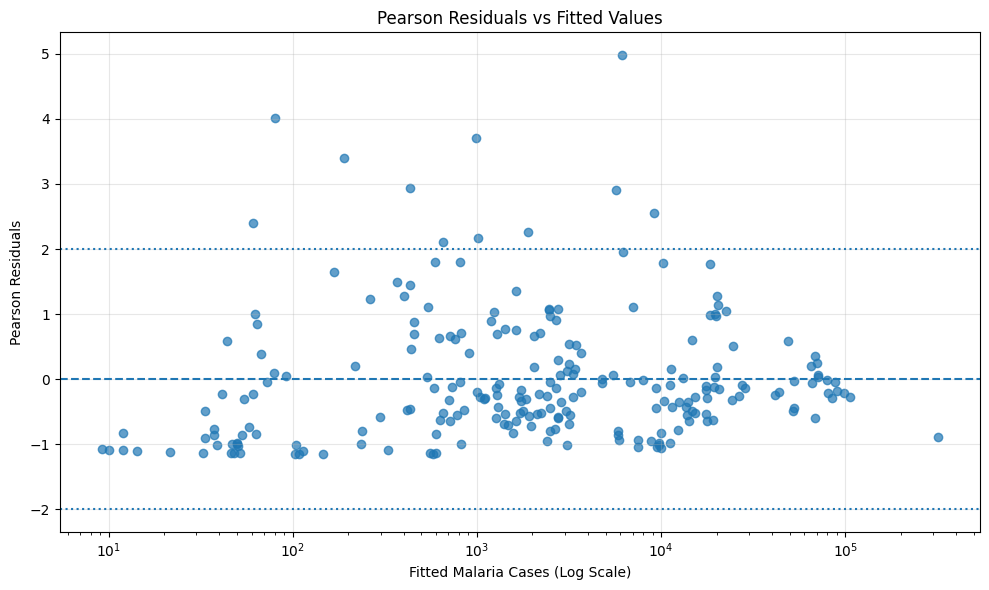

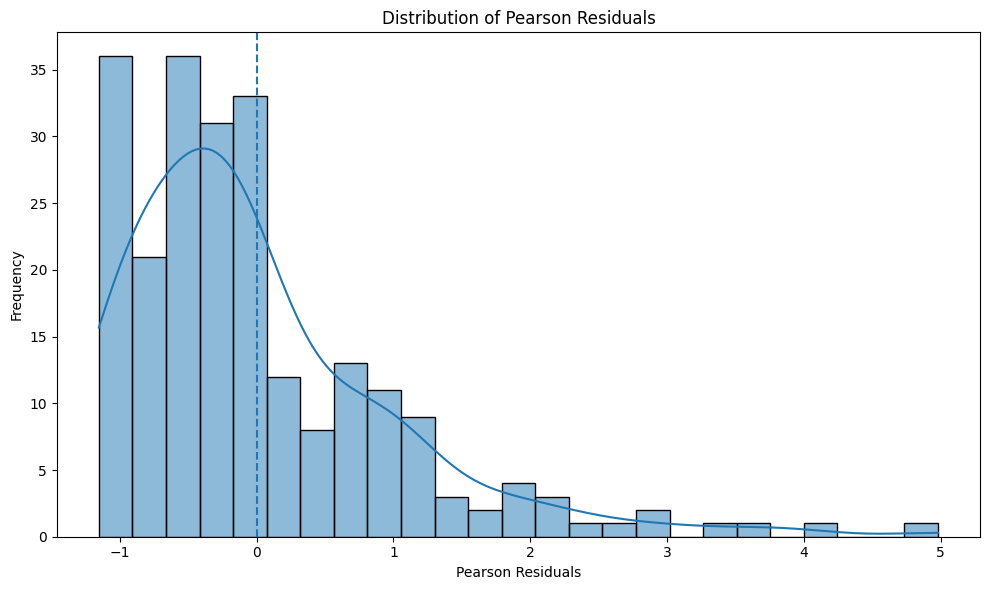

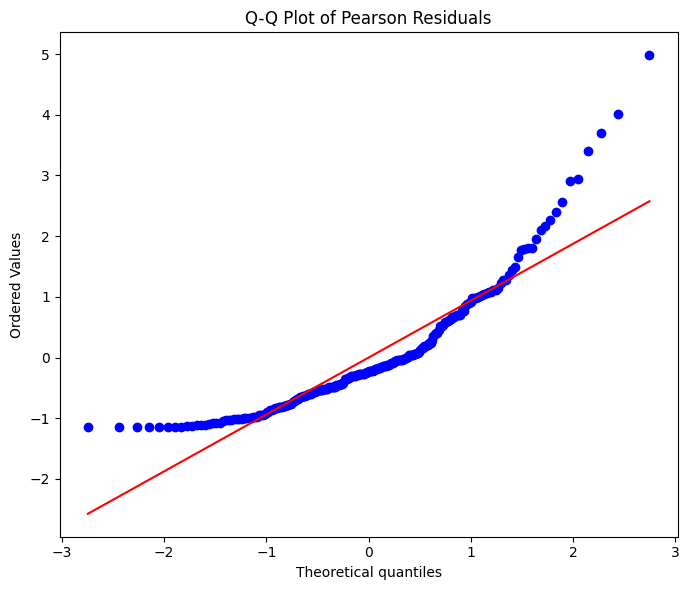

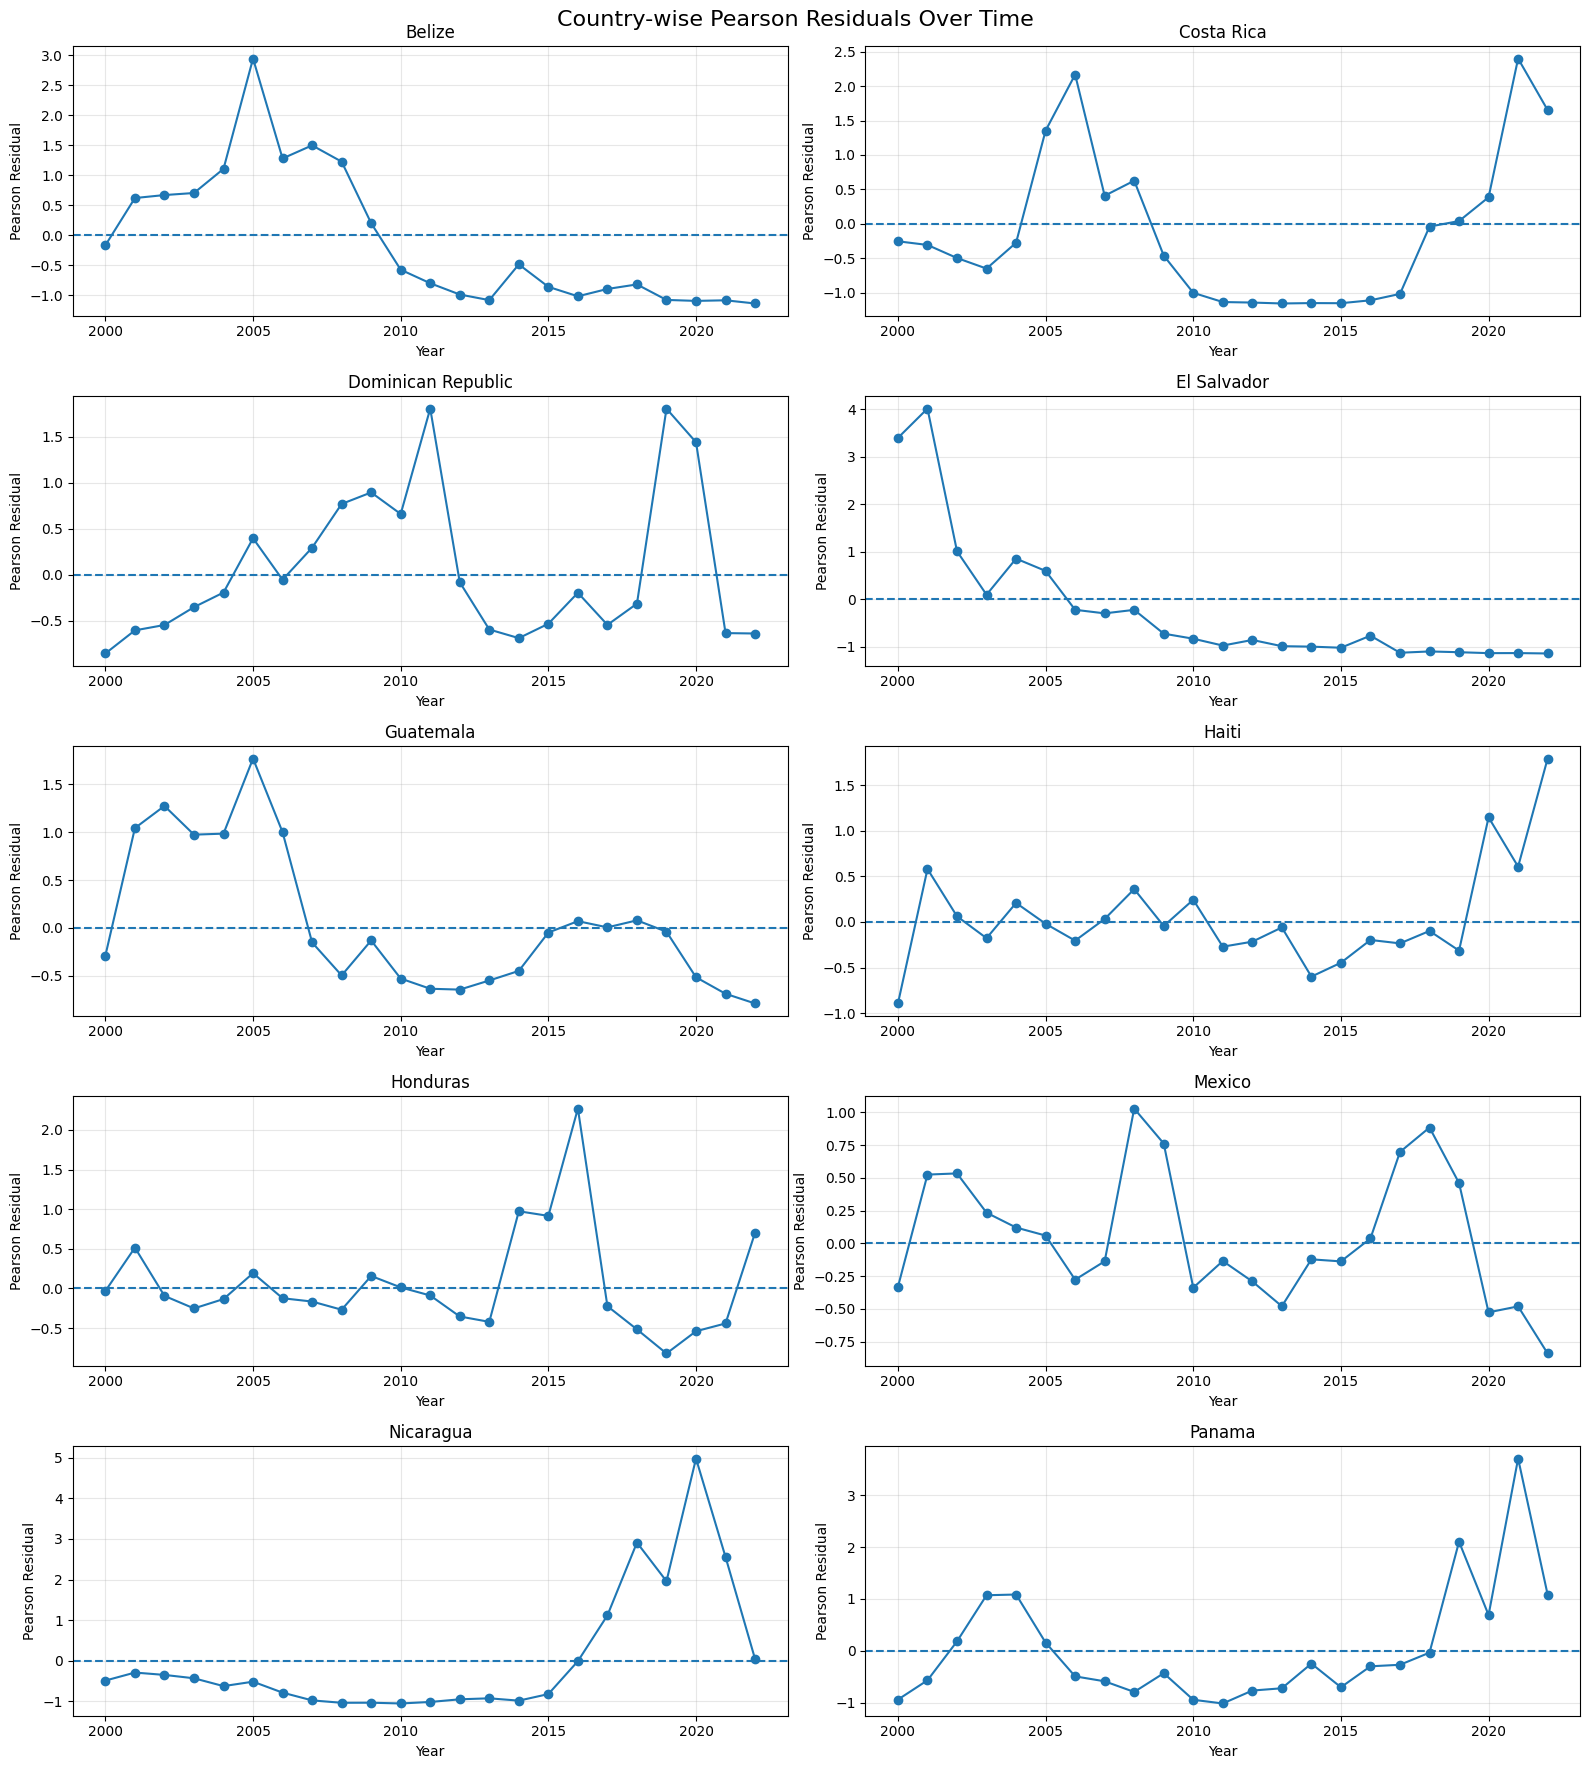

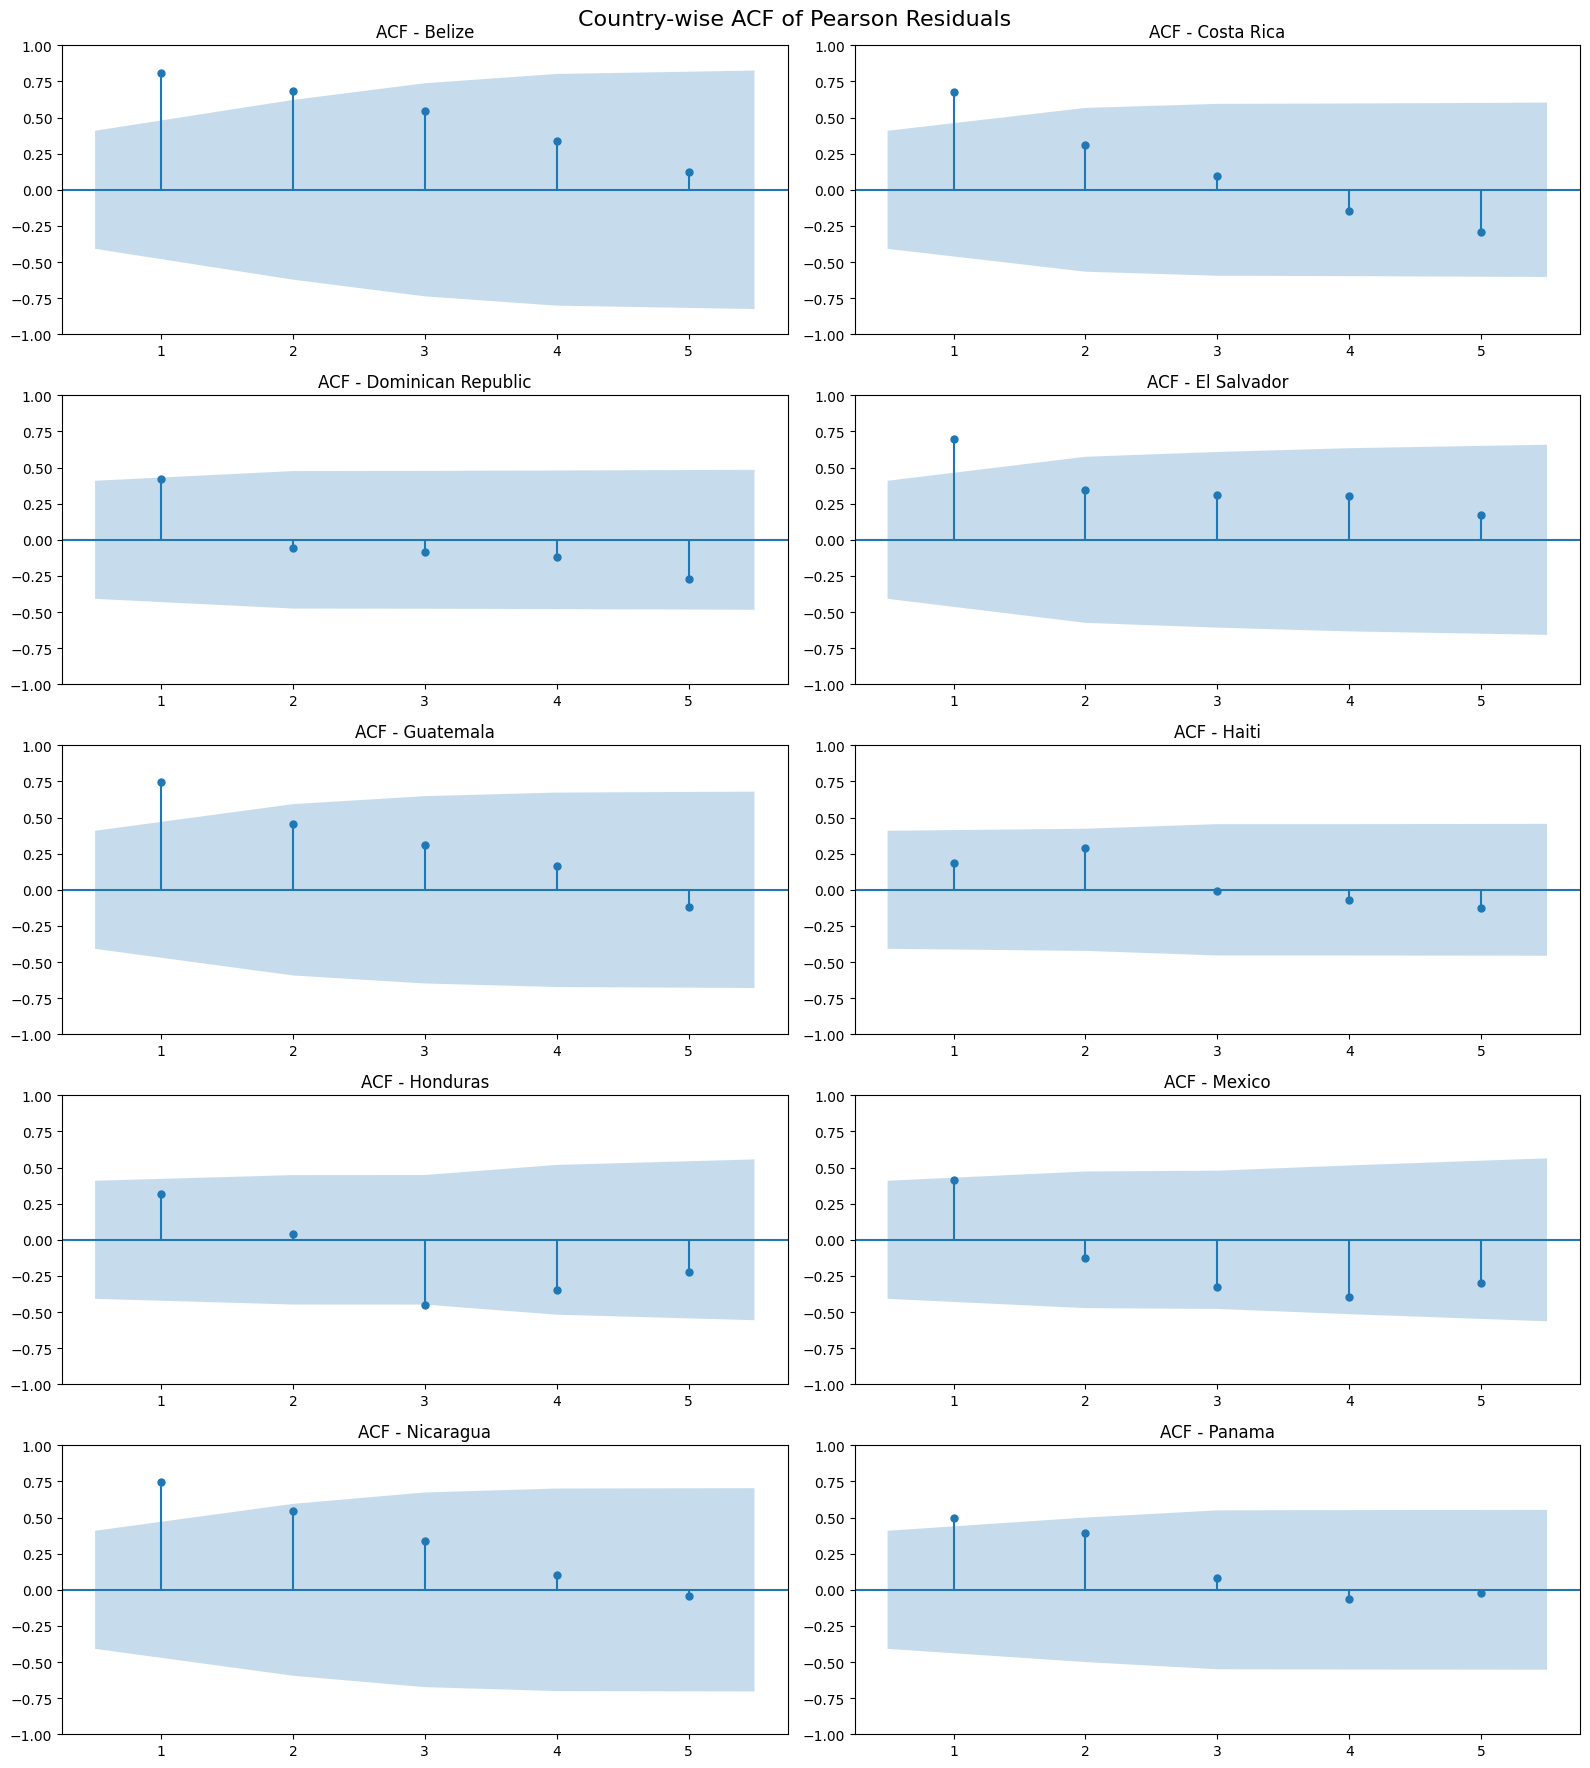

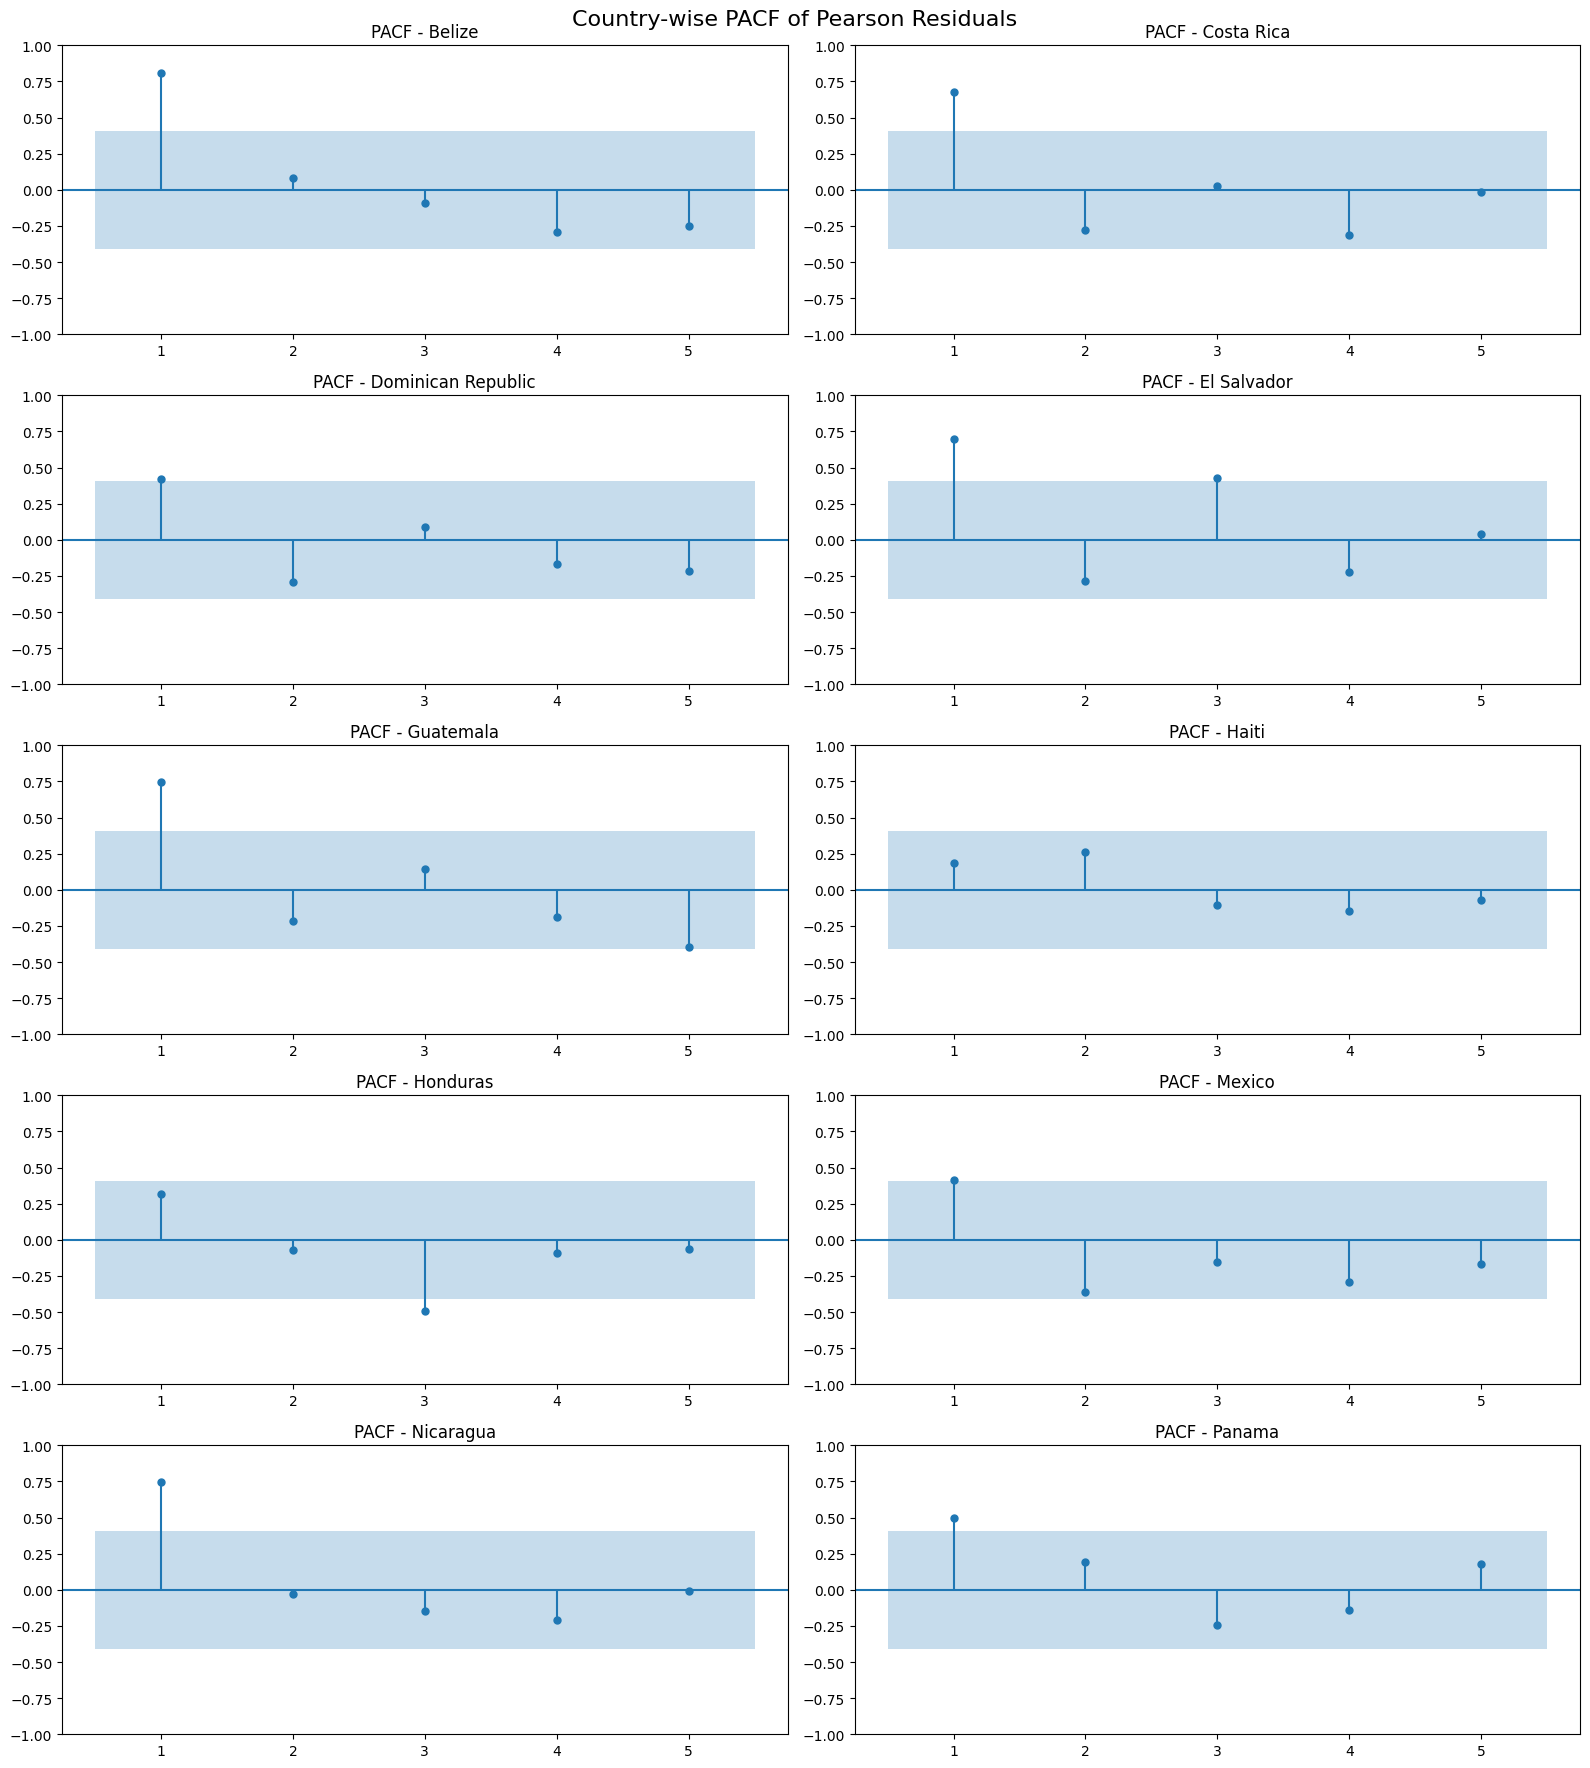


LJUNG-BOX TEST RESULTS


,Country,ACF_Lag1,LB_Statistic_Lag3,P_Value_Lag3,LB_Statistic_Lag5,P_Value_Lag5,FDR_P_Value_Lag3,FDR_P_Value_Lag5
0,Belize,0.8115,38.6086,0.0000,42.5519,0.0000,0.0000,0.0000
1,Costa Rica,0.6797,15.0150,0.0018,18.3776,0.0025,0.0036,0.0050
2,Dominican Republic,0.4218,4.9685,0.1741,7.7885,0.1683,0.1935,0.1870
3,El Salvador,0.6992,18.7934,0.0003,22.4957,0.0004,0.0008,0.0011
4,Guatemala,0.7432,22.8829,0.0000,24.1753,0.0002,0.0001,0.0007
5,Haiti,0.1878,3.2036,0.3613,3.8794,0.5669,0.3613,0.5669
6,Honduras,0.3174,8.4922,0.0369,13.8357,0.0167,0.0527,0.0238
7,Mexico,0.4113,7.9667,0.0467,15.6035,0.0081,0.0584,0.0135
8,Nicaragua,0.7479,26.0524,0.0000,26.4308,0.0001,0.0000,0.0004
9,Panama,0.4990,10.9814,0.0118,11.1182,0.0491,0.0197,0.0614



MODEL DIAGNOSTICS COMPLETED!


In [ ]:

# =====================================================
# MODEL DIAGNOSTICS FOR FINAL ZINB MODEL
# NORTH AMERICA INCLUDING PANAMA
# =====================================================

!pip -q install statsmodels openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import probplot
from statsmodels.discrete.count_model import (
    ZeroInflatedNegativeBinomialP
)

from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

from google.colab import files
import warnings

warnings.filterwarnings('ignore')

# =====================================================
# 1. LOAD DATA
# =====================================================





# =====================================================
# 2. SELECT FINAL MODEL VARIABLES
# =====================================================

predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6',
    'y8', 'y9', 'y12',
     'y16', 'y17', 'y18',
    'y19', 'y20'
]

required = [
    'Country', 'Year',
    'Malaria cases', 'y7'
] + predictors

df['Country'] = df['Country'].astype(str).str.strip()

for col in ['Year', 'Malaria cases', 'y7'] + predictors:
    df[col] = pd.to_numeric(df[col], errors='coerce')

data = df[required].replace(
    [np.inf, -np.inf], np.nan
).dropna().copy()

data = data[
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data = data.sort_values(
    ['Country', 'Year']
).reset_index(drop=True)

data['Year_c'] = data['Year'] - data['Year'].mean()

print("Observations:", len(data))
print("Countries:", data['Country'].nunique())
print("Panama included:", 'Panama' in data['Country'].values)

# =====================================================
# 3. STANDARDIZE PREDICTORS
# =====================================================

for col in predictors:

    sd = data[col].std(ddof=0)

    if sd == 0:
        raise ValueError(f"{col} has zero variance.")

    data[col + '_z'] = (
        data[col] - data[col].mean()
    ) / sd

z_predictors = [col + '_z' for col in predictors]

# =====================================================
# 4. CREATE MODEL MATRIX
# =====================================================

country_dummies = pd.get_dummies(
    data['Country'],
    prefix='Country',
    drop_first=True,
    dtype=float
)

X_count = pd.concat(
    [
        data[z_predictors].reset_index(drop=True),
        country_dummies.reset_index(drop=True),
        data[['Year_c']].reset_index(drop=True)
    ],
    axis=1
)

X_count = sm.add_constant(
    X_count,
    has_constant='add'
).astype(float)

y = data['Malaria cases'].astype(float)

offset = np.log(data['y7'].astype(float))

inflation_X = np.ones((len(data), 1))

# =====================================================
# 5. FIT FINAL ZINB MODEL
# =====================================================

zinb_model = ZeroInflatedNegativeBinomialP(
    endog=y,
    exog=X_count,
    exog_infl=inflation_X,
    offset=offset,
    inflation='logit',
    p=2
)

zinb_result = zinb_model.fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)

print("\nZINB MODEL CONVERGENCE:")
print(zinb_result.mle_retvals['converged'])

# =====================================================
# 6. PREDICTED VALUES AND PEARSON RESIDUALS
# =====================================================

fitted = np.asarray(
    zinb_result.predict(which='mean')
)

predicted_variance = np.asarray(
    zinb_result.predict(which='var')
)

observed = y.to_numpy()

pearson_residuals = (
    observed - fitted
) / np.sqrt(predicted_variance)

data['Fitted_Malaria_Cases'] = fitted

data['Pearson_Residual'] = pearson_residuals

print("\nRESIDUAL SUMMARY")
print("----------------")

print("Mean:", np.mean(pearson_residuals))

print("Standard Deviation:",
      np.std(pearson_residuals, ddof=1))

print("Maximum:",
      np.max(pearson_residuals))

print("Minimum:",
      np.min(pearson_residuals))

print("Residuals above |2|:",
      np.sum(np.abs(pearson_residuals) > 2))

print("Residuals above |3|:",
      np.sum(np.abs(pearson_residuals) > 3))

# =====================================================
# 7. RESIDUAL VS FITTED PLOT
# =====================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    fitted,
    pearson_residuals,
    alpha=0.7
)

plt.axhline(0, linestyle='--')
plt.axhline(2, linestyle=':')
plt.axhline(-2, linestyle=':')

plt.xscale('log')

plt.title('Pearson Residuals vs Fitted Values')

plt.xlabel('Fitted Malaria Cases (Log Scale)')
plt.ylabel('Pearson Residuals')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================
# 8. RESIDUAL DISTRIBUTION
# =====================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    pearson_residuals,
    bins=25,
    kde=True
)

plt.axvline(0, linestyle='--')

plt.title('Distribution of Pearson Residuals')

plt.xlabel('Pearson Residuals')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# =====================================================
# 9. Q-Q PLOT
# =====================================================

plt.figure(figsize=(7, 6))

probplot(
    pearson_residuals,
    dist='norm',
    plot=plt
)

plt.title('Q-Q Plot of Pearson Residuals')

plt.tight_layout()
plt.show()

# =====================================================
# 10. RESIDUALS OVER TIME BY COUNTRY
# =====================================================

countries = sorted(data['Country'].unique())

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for i, country in enumerate(countries):

    temp = data[data['Country'] == country]

    axes[i].plot(
        temp['Year'],
        temp['Pearson_Residual'],
        marker='o'
    )

    axes[i].axhline(0, linestyle='--')

    axes[i].set_title(country)

    axes[i].set_xlabel('Year')

    axes[i].set_ylabel('Pearson Residual')

    axes[i].grid(alpha=0.3)

plt.suptitle(
    'Country-wise Pearson Residuals Over Time',
    fontsize=16
)

plt.tight_layout()
plt.show()

# =====================================================
# 11. ACF PLOT - COUNTRY WISE
# =====================================================

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for i, country in enumerate(countries):

    temp = data[
        data['Country'] == country
    ].sort_values('Year')

    plot_acf(
        temp['Pearson_Residual'],
        lags=5,
        zero=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f'ACF - {country}'
    )

plt.suptitle(
    'Country-wise ACF of Pearson Residuals',
    fontsize=16
)

plt.tight_layout()
plt.show()

# =====================================================
# 12. PACF PLOT - COUNTRY WISE
# =====================================================

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for i, country in enumerate(countries):

    temp = data[
        data['Country'] == country
    ].sort_values('Year')

    plot_pacf(
        temp['Pearson_Residual'],
        lags=5,
        method='ywm',
        zero=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f'PACF - {country}'
    )

plt.suptitle(
    'Country-wise PACF of Pearson Residuals',
    fontsize=16
)

plt.tight_layout()
plt.show()

# =====================================================
# 13. LJUNG-BOX AUTOCORRELATION TEST
# =====================================================

lb_results = []

for country in countries:

    temp = data[
        data['Country'] == country
    ].sort_values('Year')

    residuals = temp['Pearson_Residual'].values

    lb = acorr_ljungbox(
        residuals,
        lags=[3, 5],
        return_df=True
    )

    lb_results.append({

        'Country': country,

        'ACF_Lag1': sm.tsa.stattools.acf(
            residuals,
            nlags=1,
            fft=False
        )[1],

        'LB_Statistic_Lag3':
            lb.loc[3, 'lb_stat'],

        'P_Value_Lag3':
            lb.loc[3, 'lb_pvalue'],

        'LB_Statistic_Lag5':
            lb.loc[5, 'lb_stat'],

        'P_Value_Lag5':
            lb.loc[5, 'lb_pvalue']

    })

lb_df = pd.DataFrame(lb_results)

# Multiple testing correction
lb_df['FDR_P_Value_Lag3'] = multipletests(
    lb_df['P_Value_Lag3'],
    method='fdr_bh'
)[1]

lb_df['FDR_P_Value_Lag5'] = multipletests(
    lb_df['P_Value_Lag5'],
    method='fdr_bh'
)[1]

print("\nLJUNG-BOX TEST RESULTS")

display(lb_df.round(4))

# =====================================================
# 14. FINAL DIAGNOSTIC REPORT
# =====================================================

with pd.ExcelWriter(
    'ZINB_Model_Diagnostics.xlsx'
) as writer:

    data.to_excel(
        writer,
        sheet_name='Residual Data',
        index=False
    )

    lb_df.to_excel(
        writer,
        sheet_name='Autocorrelation Test',
        index=False
    )


print("\nMODEL DIAGNOSTICS COMPLETED!")


TRAINING PERIOD: 2000 - 2017
TESTING PERIOD: 2018 - 2022
Training observations: 180
Testing observations: 50
Panama included: True

Fitting Poisson Model...
Fitting Negative Binomial Model...
Fitting ZIP Model...
Fitting ZINB Model...

FINAL MODEL PERFORMANCE COMPARISON


,Model,Train_MSE,Train_RMSE,Train_MAE,Test_MSE,Test_RMSE,Test_MAE
0,Negative Binomial,2.637237e+10,162395.7345,16978.0501,8.258164e+07,9087.4439,4370.2334
1,Poisson,1.810491e+07,4254.9868,2157.0685,8.322058e+07,9122.5314,4652.6094
2,ZIP,1.826419e+07,4273.6624,2106.7251,8.328118e+07,9125.8524,4625.9884
3,ZINB,1.181452e+10,108694.5967,12521.6701,8.645941e+07,9298.3553,4541.0263



BEST MODEL BY TEST METRICS
Lowest MSE: Negative Binomial
Lowest RMSE: Negative Binomial
Lowest MAE: Negative Binomial


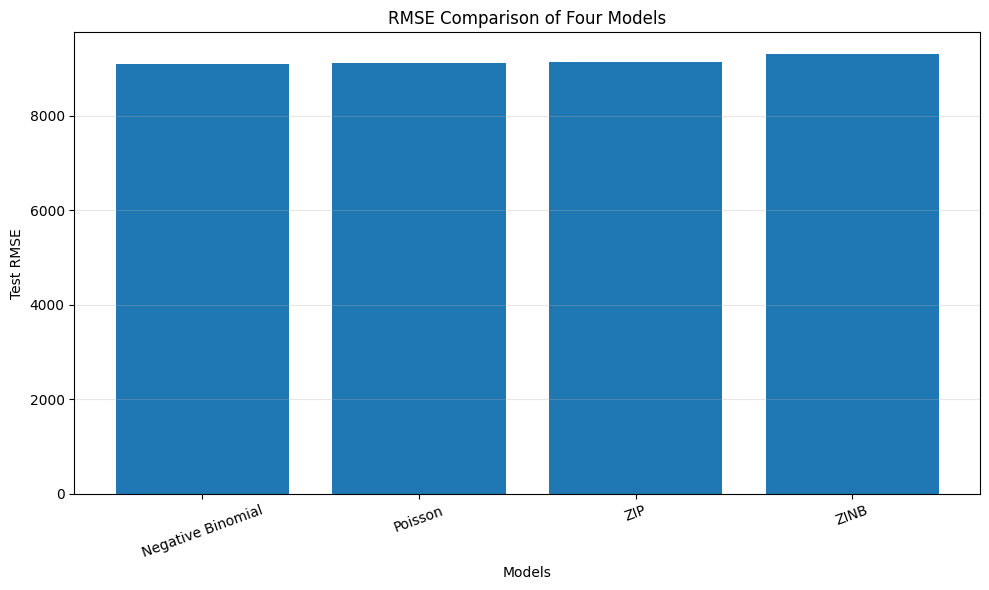

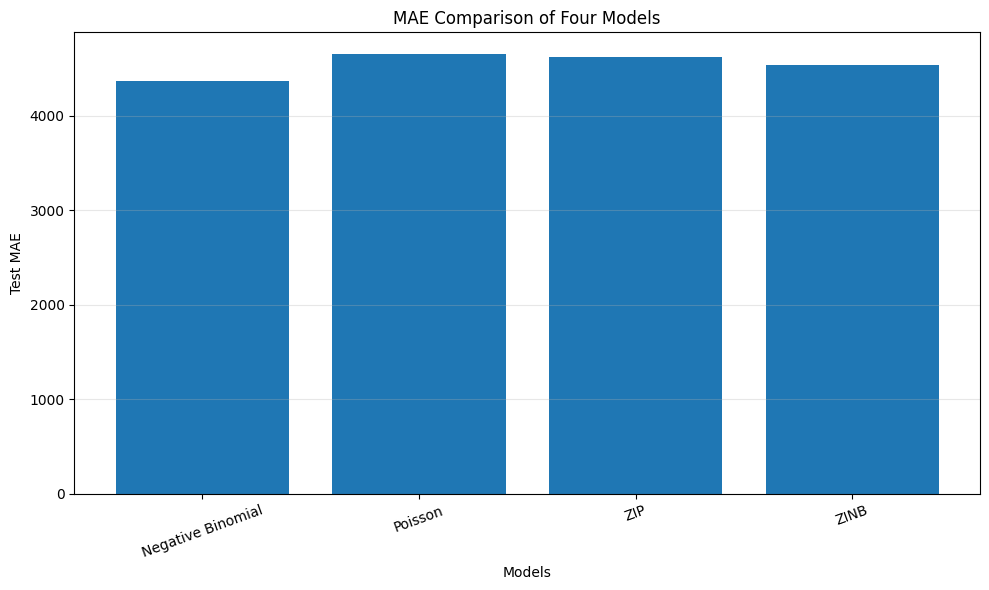


ALL FOUR MODELS EVALUATED SUCCESSFULLY!


In [ ]:

# =====================================================
# MSE, RMSE & MAE COMPARISON
# POISSON, NB, ZIP AND ZINB
# NORTH AMERICA INCLUDING PANAMA
# =====================================================

!pip -q install statsmodels scikit-learn openpyxl

import pandas as pd
import numpy as np
import statsmodels.api as sm

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from statsmodels.discrete.count_model import (
    ZeroInflatedPoisson,
    ZeroInflatedNegativeBinomialP
)

from google.colab import files
import warnings

warnings.filterwarnings('ignore')

# =====================================================
# 2. SELECT VARIABLES
# =====================================================

predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6',
    'y8', 'y9','y12',
     'y16', 'y17', 'y18',
    'y19', 'y20'
]

required = [
    'Country', 'Year',
    'Malaria cases', 'y7'
] + predictors

for col in ['Year', 'Malaria cases', 'y7'] + predictors:
    df[col] = pd.to_numeric(df[col], errors='coerce')

data = df[required].replace(
    [np.inf, -np.inf],
    np.nan
).dropna().copy()

data = data[
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data['Year'] = data['Year'].astype(int)

data = data.sort_values(
    ['Year', 'Country']
).reset_index(drop=True)

# =====================================================
# 3. TIME-BASED TRAIN TEST SPLIT
# =====================================================

years = sorted(data['Year'].unique())

split_index = int(len(years) * 0.80)

train_years = years[:split_index]
test_years = years[split_index:]

train = data[
    data['Year'].isin(train_years)
].copy().reset_index(drop=True)

test = data[
    data['Year'].isin(test_years)
].copy().reset_index(drop=True)

print("TRAINING PERIOD:", min(train_years), "-", max(train_years))
print("TESTING PERIOD:", min(test_years), "-", max(test_years))

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Panama included:", 'Panama' in data['Country'].unique())

# =====================================================
# 4. STANDARDIZE USING TRAINING DATA ONLY
# =====================================================

train_means = {}
train_stds = {}

for col in predictors:

    train_means[col] = train[col].mean()
    train_stds[col] = train[col].std(ddof=0)

    if train_stds[col] == 0:
        raise ValueError(f"{col} has zero variance.")

country_levels = sorted(data['Country'].unique())

year_mean = train['Year'].mean()

train['Year_c'] = train['Year'] - year_mean
test['Year_c'] = test['Year'] - year_mean

# =====================================================
# 5. CREATE DESIGN MATRIX
# =====================================================

def create_matrix(frame):

    z = pd.DataFrame(index=frame.index)

    for col in predictors:

        z[col + '_z'] = (
            frame[col] - train_means[col]
        ) / train_stds[col]

    country_cat = pd.Series(
        pd.Categorical(
            frame['Country'],
            categories=country_levels
        ),
        index=frame.index
    )

    dummies = pd.get_dummies(
        country_cat,
        prefix='Country',
        drop_first=True,
        dtype=float
    )

    expected_columns = [
        'Country_' + c for c in country_levels[1:]
    ]

    dummies = dummies.reindex(
        columns=expected_columns,
        fill_value=0
    )

    X = pd.concat(
        [z, dummies, frame[['Year_c']]],
        axis=1
    )

    return sm.add_constant(
        X,
        has_constant='add'
    ).astype(float)


X_train = create_matrix(train)
X_test = create_matrix(test)

y_train = train['Malaria cases'].to_numpy(dtype=float)
y_test = test['Malaria cases'].to_numpy(dtype=float)

# Population offset
offset_train = np.log(train['y7'].to_numpy(dtype=float))
offset_test = np.log(test['y7'].to_numpy(dtype=float))

# Inflation model: intercept only
infl_train = np.ones((len(train), 1))
infl_test = np.ones((len(test), 1))

# =====================================================
# 6. POISSON MODEL
# =====================================================

print("\nFitting Poisson Model...")

poisson_model = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Poisson(),
    offset=offset_train
)

poisson_result = poisson_model.fit()

# =====================================================
# 7. NEGATIVE BINOMIAL MODEL
# =====================================================

print("Fitting Negative Binomial Model...")

nb_model = sm.NegativeBinomial(
    y_train,
    X_train,
    loglike_method='nb2',
    offset=offset_train
)

nb_result = nb_model.fit(
    method='bfgs',
    maxiter=2000,
    disp=False
)

# =====================================================
# 8. ZERO-INFLATED POISSON MODEL
# =====================================================

print("Fitting ZIP Model...")

zip_model = ZeroInflatedPoisson(
    endog=y_train,
    exog=X_train,
    exog_infl=infl_train,
    offset=offset_train,
    inflation='logit'
)

zip_result = zip_model.fit(
    method='bfgs',
    maxiter=2000,
    disp=False
)

# =====================================================
# 9. ZERO-INFLATED NEGATIVE BINOMIAL MODEL
# =====================================================

print("Fitting ZINB Model...")

zinb_model = ZeroInflatedNegativeBinomialP(
    endog=y_train,
    exog=X_train,
    exog_infl=infl_train,
    offset=offset_train,
    inflation='logit',
    p=2
)

zinb_result = zinb_model.fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)

# =====================================================
# 10. PREDICTIONS FOR TRAINING AND TESTING
# =====================================================

predictions = {}

# Poisson
predictions['Poisson'] = (
    poisson_result.predict(
        X_train, offset=offset_train
    ),
    poisson_result.predict(
        X_test, offset=offset_test
    )
)

# Negative Binomial
predictions['Negative Binomial'] = (
    nb_result.predict(
        exog=X_train,
        offset=offset_train,
        which='mean'
    ),
    nb_result.predict(
        exog=X_test,
        offset=offset_test,
        which='mean'
    )
)

# ZIP
predictions['ZIP'] = (
    zip_result.predict(
        exog=X_train,
        exog_infl=infl_train,
        offset=offset_train,
        which='mean'
    ),
    zip_result.predict(
        exog=X_test,
        exog_infl=infl_test,
        offset=offset_test,
        which='mean'
    )
)

# ZINB
predictions['ZINB'] = (
    zinb_result.predict(
        exog=X_train,
        exog_infl=infl_train,
        offset=offset_train,
        which='mean'
    ),
    zinb_result.predict(
        exog=X_test,
        exog_infl=infl_test,
        offset=offset_test,
        which='mean'
    )
)

# =====================================================
# 11. CALCULATE MSE, RMSE AND MAE
# =====================================================

results = []

prediction_data = pd.DataFrame({
    'Country': test['Country'].values,
    'Year': test['Year'].values,
    'Actual_Cases': y_test
})

for model_name, (train_pred, test_pred) in predictions.items():

    train_pred = np.clip(
        np.asarray(train_pred).ravel(), 0, None
    )

    test_pred = np.clip(
        np.asarray(test_pred).ravel(), 0, None
    )

    # Training metrics
    train_mse = mean_squared_error(
        y_train, train_pred
    )

    train_rmse = np.sqrt(train_mse)

    train_mae = mean_absolute_error(
        y_train, train_pred
    )

    # Testing metrics
    test_mse = mean_squared_error(
        y_test, test_pred
    )

    test_rmse = np.sqrt(test_mse)

    test_mae = mean_absolute_error(
        y_test, test_pred
    )

    results.append({

        'Model': model_name,

        'Train_MSE': train_mse,

        'Train_RMSE': train_rmse,

        'Train_MAE': train_mae,

        'Test_MSE': test_mse,

        'Test_RMSE': test_rmse,

        'Test_MAE': test_mae

    })

    prediction_data[
        model_name.replace(' ', '_') + '_Predicted'
    ] = test_pred

# =====================================================
# 12. FINAL COMPARISON TABLE
# =====================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    'Test_RMSE'
).reset_index(drop=True)

print("\nFINAL MODEL PERFORMANCE COMPARISON")
print("===================================")

display(results_df.round(4))

# =====================================================
# 13. BEST MODEL SELECTION
# =====================================================

best_mse = results_df.loc[
    results_df['Test_MSE'].idxmin()
]

best_rmse = results_df.loc[
    results_df['Test_RMSE'].idxmin()
]

best_mae = results_df.loc[
    results_df['Test_MAE'].idxmin()
]

print("\nBEST MODEL BY TEST METRICS")

print("Lowest MSE:", best_mse['Model'])
print("Lowest RMSE:", best_rmse['Model'])
print("Lowest MAE:", best_mae['Model'])

# =====================================================
# 14. VISUALIZATION
# =====================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    results_df['Model'],
    results_df['Test_RMSE']
)

plt.title('RMSE Comparison of Four Models')
plt.xlabel('Models')
plt.ylabel('Test RMSE')

plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

plt.bar(
    results_df['Model'],
    results_df['Test_MAE']
)

plt.title('MAE Comparison of Four Models')
plt.xlabel('Models')
plt.ylabel('Test MAE')

plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# =====================================================
# 15. EXPORT RESULTS
# =====================================================

with pd.ExcelWriter(
    'Malaria_Forecasting_Accuracy_Results.xlsx'
) as writer:

    results_df.to_excel(
        writer,
        sheet_name='MSE_RMSE_MAE',
        index=False
    )

    prediction_data.to_excel(
        writer,
        sheet_name='Actual_vs_Predicted',
        index=False
    )



print("\nALL FOUR MODELS EVALUATED SUCCESSFULLY!")


Countries: 9
Observations: 207

TRAINING PERIOD: 2000 - 2017
TESTING PERIOD: 2018 - 2022
Training observations: 162
Testing observations: 45

Fitting Poisson Model...
Fitting Negative Binomial Model...
Fitting ZIP Model...
Fitting ZINB Model...

All models fitted.

FINAL MODEL PERFORMANCE COMPARISON


,Model,Train_MSE,Train_RMSE,Train_MAE,Test_MSE,Test_RMSE,Test_MAE,Converged
0,Poisson,2.025950e+07,4501.0552,2323.1378,8.715957e+07,9335.9291,4699.6725,True
1,ZIP,2.047637e+07,4525.0825,2280.0948,8.766257e+07,9362.8293,4681.8110,True
2,Negative Binomial,3.146042e+10,177370.8669,19501.4699,9.126607e+07,9553.3275,4544.0825,True
3,ZINB,1.273720e+10,112859.2197,13812.4102,9.616257e+07,9806.2515,4751.4603,True



BEST CONVERGED MODEL: Poisson

ACTUAL VS PREDICTED CASES


,Country,Year,Observed Cases,Predicted Cases,Prediction Error
0,Belize,2018,3,96.18,-93.18
1,Costa Rica,2018,70,88.21,-18.21
2,Dominican Republic,2018,516,792.23,-276.23
3,El Salvador,2018,0,13.88,-13.88
4,Guatemala,2018,3538,3502.65,35.35
5,Haiti,2018,16000,12011.06,3988.94
6,Honduras,2018,949,2137.21,-1188.21
7,Mexico,2018,803,240.23,562.77
8,Nicaragua,2018,20158,1372.15,18785.85
9,Belize,2019,0,113.42,-113.42



ANNUAL FORECASTING RESULTS


,Year,Observed Cases,Predicted Cases
0,2018,42037,20253.79
1,2019,39541,19649.59
2,2020,77133,28231.90
3,2021,55524,31906.43
4,2022,52916,26541.69


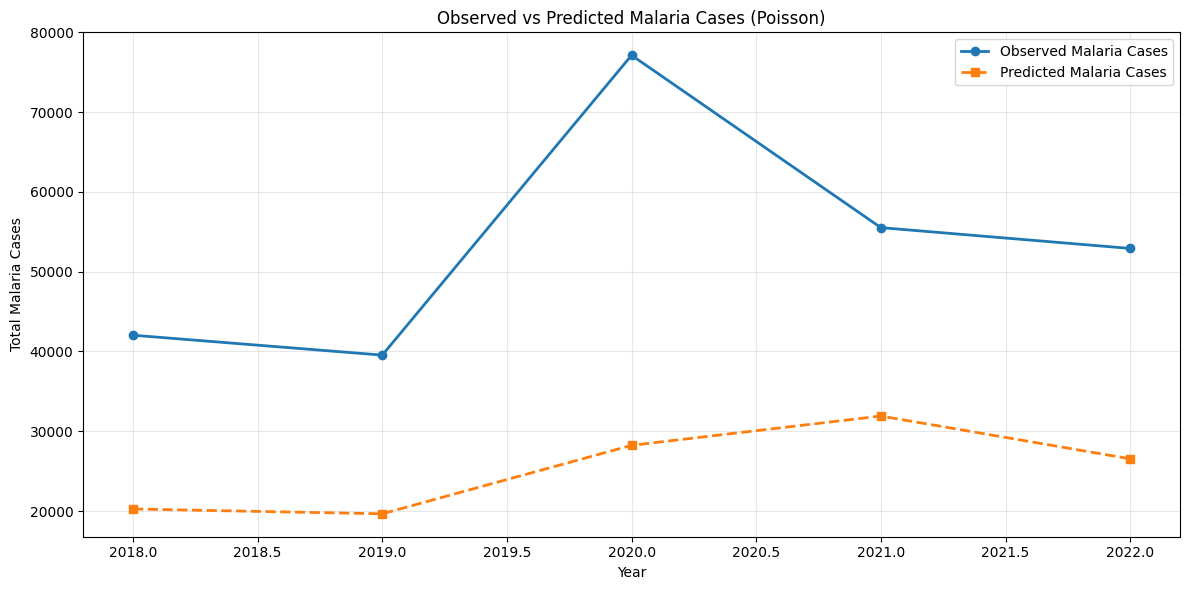

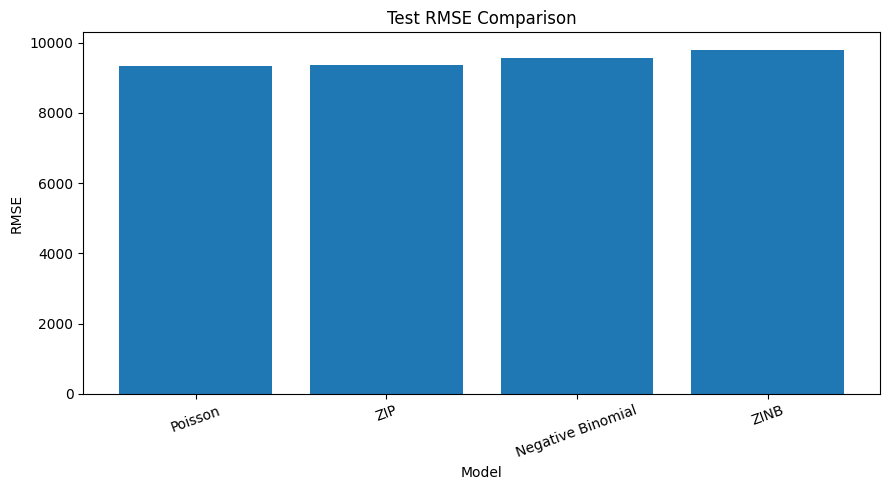


FORECASTING AND VALIDATION COMPLETED!


In [ ]:

# ============================================================
# STEP 5: FORECASTING AND VALIDATION
# NORTH AMERICA MALARIA FORECASTING
# ============================================================

!pip -q install statsmodels scikit-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings

from google.colab import files

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from statsmodels.discrete.count_model import (
    ZeroInflatedPoisson,
    ZeroInflatedNegativeBinomialP
)

warnings.filterwarnings('ignore')

# ============================================================
# 1. UPLOAD DATASET
# ============================================================


# ============================================================
# 2. SELECT VERIFIED / USABLE VARIABLES
# ============================================================

predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6',
    'y8', 'y9','y12',
     'y16', 'y17', 'y18',
    'y19', 'y20'
]

required = [
    'Country',
    'Year',
    'Malaria cases',
    'y7'
] + predictors

data = df[required].copy()

for col in ['Year', 'Malaria cases', 'y7'] + predictors:
    data[col] = pd.to_numeric(
        data[col],
        errors='coerce'
    )

data = data.replace(
    [np.inf, -np.inf],
    np.nan
).dropna().copy()

# Exclude Panama
data = data[
    data['Country'] != 'Panama'
].copy()

# Remove invalid observations
data = data[
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data['Year'] = data['Year'].astype(int)

data = data.sort_values(
    ['Year', 'Country']
).reset_index(drop=True)

print("Countries:", data['Country'].nunique())
print("Observations:", len(data))

# ============================================================
# 3. TIME-BASED TRAIN-TEST SPLIT (80:20)
# ============================================================

years = sorted(data['Year'].unique())

split_index = int(len(years) * 0.80)

train_years = years[:split_index]
test_years = years[split_index:]

train = data[
    data['Year'].isin(train_years)
].copy().reset_index(drop=True)

test = data[
    data['Year'].isin(test_years)
].copy().reset_index(drop=True)

print("\nTRAINING PERIOD:",
      min(train_years), "-", max(train_years))

print("TESTING PERIOD:",
      min(test_years), "-", max(test_years))

print("Training observations:", len(train))
print("Testing observations:", len(test))

# ============================================================
# 4. STANDARDIZATION USING TRAINING DATA
# ============================================================

train_means = train[predictors].mean()

train_stds = train[predictors].std(ddof=0)

if (train_stds == 0).any():
    raise ValueError("A predictor has zero variance.")

year_mean = train['Year'].mean()

train['Year_c'] = train['Year'] - year_mean
test['Year_c'] = test['Year'] - year_mean

country_levels = sorted(data['Country'].unique())


# ============================================================
# 5. CREATE DESIGN MATRIX
# ============================================================

def create_matrix(frame):

    z = (
        frame[predictors] - train_means
    ) / train_stds

    z.columns = [
        col + '_z' for col in predictors
    ]

    country_cat = pd.Series(
        pd.Categorical(
            frame['Country'],
            categories=country_levels
        ),
        index=frame.index
    )

    dummies = pd.get_dummies(
        country_cat,
        prefix='Country',
        drop_first=True,
        dtype=float
    )

    expected_columns = [
        'Country_' + c
        for c in country_levels[1:]
    ]

    dummies = dummies.reindex(
        columns=expected_columns,
        fill_value=0
    )

    X = pd.concat(
        [z, dummies, frame[['Year_c']]],
        axis=1
    )

    return sm.add_constant(
        X,
        has_constant='add'
    ).astype(float)


X_train = create_matrix(train)
X_test = create_matrix(test)

y_train = train['Malaria cases'].to_numpy(dtype=float)
y_test = test['Malaria cases'].to_numpy(dtype=float)

# Population offset
offset_train = np.log(
    train['y7'].to_numpy(dtype=float)
)

offset_test = np.log(
    test['y7'].to_numpy(dtype=float)
)

# Zero-inflation model
infl_train = np.ones((len(train), 1))
infl_test = np.ones((len(test), 1))

# ============================================================
# 6. FIT FOUR MODELS
# ============================================================

fitted_models = {}

# 1. POISSON
print("\nFitting Poisson Model...")

fitted_models['Poisson'] = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Poisson(),
    offset=offset_train
).fit()


# 2. NEGATIVE BINOMIAL
print("Fitting Negative Binomial Model...")

fitted_models['Negative Binomial'] = (
    sm.NegativeBinomial(
        y_train,
        X_train,
        loglike_method='nb2',
        offset=offset_train
    ).fit(
        method='bfgs',
        maxiter=2000,
        disp=False
    )
)


# 3. ZERO-INFLATED POISSON
print("Fitting ZIP Model...")

fitted_models['ZIP'] = ZeroInflatedPoisson(
    endog=y_train,
    exog=X_train,
    exog_infl=infl_train,
    offset=offset_train,
    inflation='logit'
).fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)


# 4. ZERO-INFLATED NEGATIVE BINOMIAL
print("Fitting ZINB Model...")

fitted_models['ZINB'] = (
    ZeroInflatedNegativeBinomialP(
        endog=y_train,
        exog=X_train,
        exog_infl=infl_train,
        offset=offset_train,
        inflation='logit',
        p=2
    ).fit(
        method='bfgs',
        maxiter=3000,
        disp=False
    )
)

print("\nAll models fitted.")

# ============================================================
# 7. GENERATE PREDICTIONS
# ============================================================

def get_prediction(name, result, X, offset, infl):

    if name in ['ZIP', 'ZINB']:

        pred = result.predict(
            exog=X,
            exog_infl=infl,
            offset=offset,
            which='mean'
        )

    else:

        pred = result.predict(
            X,
            offset=offset
        )

    return np.maximum(
        np.asarray(pred),
        0
    )


# ============================================================
# 8. CALCULATE MSE, RMSE AND MAE
# ============================================================

results = []

all_predictions = {}

for name, result in fitted_models.items():

    train_pred = get_prediction(
        name,
        result,
        X_train,
        offset_train,
        infl_train
    )

    test_pred = get_prediction(
        name,
        result,
        X_test,
        offset_test,
        infl_test
    )

    all_predictions[name] = (
        train_pred,
        test_pred
    )

    train_mse = mean_squared_error(
        y_train,
        train_pred
    )

    test_mse = mean_squared_error(
        y_test,
        test_pred
    )

    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)

    train_mae = mean_absolute_error(
        y_train,
        train_pred
    )

    test_mae = mean_absolute_error(
        y_test,
        test_pred
    )

    converged = getattr(
        result,
        'mle_retvals',
        {}
    ).get('converged', True)

    results.append({

        'Model': name,

        'Train_MSE': train_mse,
        'Train_RMSE': train_rmse,
        'Train_MAE': train_mae,

        'Test_MSE': test_mse,
        'Test_RMSE': test_rmse,
        'Test_MAE': test_mae,

        'Converged': converged

    })


# ============================================================
# 9. FINAL MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    'Test_RMSE'
).reset_index(drop=True)

print("\nFINAL MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

# Select best converged model
valid_models = results_df[
    results_df['Converged'] == True
]

if valid_models.empty:
    raise ValueError(
        "No model converged. Check model specification."
    )

best_model = valid_models.iloc[0]['Model']

print("\nBEST CONVERGED MODEL:", best_model)


# ============================================================
# 10. TEST DATA PREDICTION TABLE
# ============================================================

best_test_pred = all_predictions[
    best_model
][1]

prediction_data = test[
    ['Country', 'Year', 'Malaria cases']
].copy()

prediction_data = prediction_data.rename(
    columns={'Malaria cases': 'Observed Cases'}
)

prediction_data['Predicted Cases'] = best_test_pred

prediction_data['Prediction Error'] = (
    prediction_data['Observed Cases'] -
    prediction_data['Predicted Cases']
)

print("\nACTUAL VS PREDICTED CASES")

display(
    prediction_data.round(2)
)


# ============================================================
# 11. ANNUAL OBSERVED VS PREDICTED
# ============================================================

annual = prediction_data.groupby(
    'Year'
).agg({

    'Observed Cases': 'sum',

    'Predicted Cases': 'sum'

}).reset_index()

print("\nANNUAL FORECASTING RESULTS")

display(annual.round(2))


# ============================================================
# 12. OBSERVED VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    annual['Year'],
    annual['Observed Cases'],
    marker='o',
    linewidth=2,
    label='Observed Malaria Cases'
)

plt.plot(
    annual['Year'],
    annual['Predicted Cases'],
    marker='s',
    linestyle='--',
    linewidth=2,
    label='Predicted Malaria Cases'
)

plt.title(
    f'Observed vs Predicted Malaria Cases ({best_model})'
)

plt.xlabel('Year')
plt.ylabel('Total Malaria Cases')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 13. RMSE COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    results_df['Model'],
    results_df['Test_RMSE']
)

plt.title('Test RMSE Comparison')

plt.xlabel('Model')
plt.ylabel('RMSE')

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


# ============================================================
# 14. EXPORT RESULTS
# ============================================================

output_file = 'Malaria_Forecasting_Validation.xlsx'

with pd.ExcelWriter(output_file) as writer:

    results_df.to_excel(
        writer,
        sheet_name='Model Comparison',
        index=False
    )

    prediction_data.to_excel(
        writer,
        sheet_name='Test Predictions',
        index=False
    )

    annual.to_excel(
        writer,
        sheet_name='Annual Forecast',
        index=False
    )


print("\nFORECASTING AND VALIDATION COMPLETED!")


COUNTRIES: 10
PANAMA INCLUDED: True
TOTAL OBSERVATIONS: 230

TRAINING DATA: 2000-2017
Observations: 180

TESTING DATA: 2018-2022
Observations: 50

FITTING POISSON
FITTING NEGATIVE BINOMIAL
FITTING ZIP
FITTING ZINB

FINAL MODEL COMPARISON


,Model,Log_Likelihood,AIC,BIC,Train_MSE,Train_RMSE,Train_MAE,Test_MSE,Test_RMSE,Test_MAE,Max_Test_Prediction,Converged
0,Poisson,-104327.012,208692.024,208752.690,1.957674e+07,4424.561,2248.889,6.933157e+07,8326.558,4313.764,27681.669,True
1,NB,-1542.136,3124.271,3188.130,5.007847e+08,22378.219,6619.300,7.216588e+07,8495.050,4119.177,21123.883,True
2,ZIP,-103561.018,207162.036,207225.896,1.983399e+07,4453.537,2240.254,6.890700e+07,8301.024,4259.656,27171.576,True
3,ZINB,-1534.745,3111.490,3178.542,3.970433e+08,19925.945,6021.138,7.182488e+07,8474.956,4096.430,21402.859,True



BEST MODEL BASED ON TEST RMSE: ZIP

TEST RESULTS: 2018-2022


,Country,Year,Observed_Cases,Predicted_Cases,Absolute_Error
0,Belize,2018,3,85.18,82.18
1,Belize,2019,0,71.25,71.25
2,Belize,2020,0,233.11,233.11
3,Belize,2021,0,239.68,239.68
4,Belize,2022,0,297.51,297.51
5,Costa Rica,2018,70,75.31,5.31
6,Costa Rica,2019,95,67.29,27.71
7,Costa Rica,2020,90,108.18,18.18
8,Costa Rica,2021,189,113.28,75.72
9,Costa Rica,2022,406,149.01,256.99



FUTURE PREDICTOR PROJECTIONS


,Country,Year,y7,y3,y5,y6,y8,y9,y16,y17,y19
0,Belize,2023,426204.486,32.902,12.896,98.717,6.128,1.549,41.230,65.527,27.175
1,Belize,2024,436343.002,33.396,13.093,99.519,6.225,1.452,41.622,66.331,27.288
2,Belize,2025,446722.692,33.890,13.291,100.321,6.321,1.356,42.013,67.135,27.402
3,Belize,2026,457349.293,34.384,13.488,101.122,6.418,1.260,42.404,67.939,27.515
4,Belize,2027,468228.679,34.878,13.685,101.924,6.515,1.163,42.796,68.743,27.629
5,Costa Rica,2023,5254497.211,27.466,24.402,100.216,4.289,0.617,40.739,67.419,13.952
6,Costa Rica,2024,5316480.807,28.126,24.170,100.300,4.287,0.543,40.907,68.264,13.615
7,Costa Rica,2025,5379195.581,28.785,23.938,100.383,4.286,0.469,41.076,69.108,13.279
8,Costa Rica,2026,5442650.156,29.445,23.706,100.467,4.284,0.395,41.245,69.953,12.942
9,Costa Rica,2027,5506853.261,30.104,23.474,100.551,4.282,0.321,41.413,70.797,12.606


... (2 outputs left out)


TOTAL NORTH AMERICA FORECAST


,Year,Forecasted_Cases
0,2023,27404.86
1,2024,25129.41
2,2025,23050.06
3,2026,21149.18
4,2027,19410.79



ANNUAL TEST VALIDATION


,Year,Observed_Cases,Predicted_Cases
0,2018,42826,35071.27
1,2019,41391,28615.82
2,2020,79184,40656.16
3,2021,59680,38779.29
4,2022,57662,34563.83


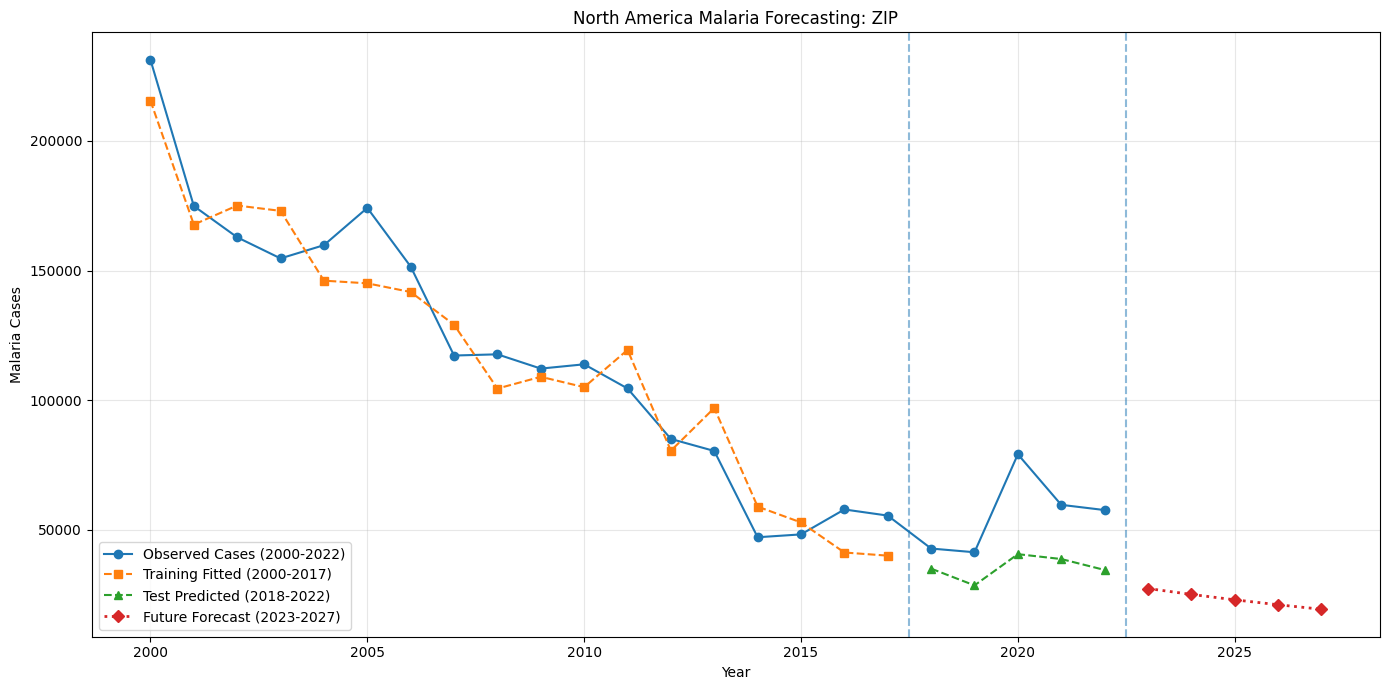

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


FORECASTING COMPLETED
Training: 2000-2017
Testing: 2018-2022
Forecast: 2023-2027
Selected Model: ZIP


In [ ]:

# ============================================================
# NORTH AMERICA MALARIA FORECASTING (2000-2027)
#
# TRAIN: 2000-2017
# TEST:  2018-2022
# FORECAST: 2023-2027
#
# COUNTRIES: INCLUDING PANAMA
# MODELS: POISSON, NB, ZIP, ZINB
# ============================================================

!pip -q install statsmodels scikit-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings

from google.colab import files
from sklearn.metrics import mean_squared_error, mean_absolute_error

from statsmodels.discrete.count_model import (
    ZeroInflatedPoisson,
    ZeroInflatedNegativeBinomialP
)

warnings.filterwarnings('ignore')


# ============================================================
# 2. VARIABLES
# ============================================================

predictors = [
    'y3', 'y5', 'y6', 'y8',
    'y9', 'y16', 'y17', 'y19'
]

required = [
    'Country', 'Year',
    'Malaria cases', 'y7'
] + predictors

data = df[required].copy()

for col in ['Year', 'Malaria cases', 'y7'] + predictors:
    data[col] = pd.to_numeric(data[col], errors='coerce')

data = data.replace(
    [np.inf, -np.inf], np.nan
).dropna().copy()

data = data[
    data['Year'].between(2000, 2022) &
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data['Year'] = data['Year'].astype(int)

data = data.sort_values(
    ['Country', 'Year']
).reset_index(drop=True)

print("COUNTRIES:", data['Country'].nunique())
print("PANAMA INCLUDED:", 'Panama' in data['Country'].values)
print("TOTAL OBSERVATIONS:", len(data))

# ============================================================
# 3. FIXED TRAIN-TEST SPLIT
# ============================================================

train = data[
    data['Year'].between(2000, 2017)
].copy().reset_index(drop=True)

test = data[
    data['Year'].between(2018, 2022)
].copy().reset_index(drop=True)

print("\nTRAINING DATA: 2000-2017")
print("Observations:", len(train))

print("\nTESTING DATA: 2018-2022")
print("Observations:", len(test))

# Ensure all countries are represented in training data

country_levels = sorted(train['Country'].unique())

if set(test['Country'].unique()) - set(country_levels):
    raise ValueError("A test country is missing from training data.")

if 'Panama' not in country_levels:
    raise ValueError("Panama is missing from training data.")

# ============================================================
# 4. STANDARDIZATION
# ============================================================

train_means = train[predictors].mean()
train_stds = train[predictors].std(ddof=0)

if (train_stds == 0).any():
    raise ValueError("Zero variance predictor detected.")

year_mean = train['Year'].mean()

# ============================================================
# 5. DESIGN MATRIX
# ============================================================

def create_matrix(frame):

    z = (
        frame[predictors] - train_means
    ) / train_stds

    z.columns = [p + '_z' for p in predictors]

    country_cat = pd.Categorical(
        frame['Country'],
        categories=country_levels
    )

    dummies = pd.get_dummies(
        pd.Series(country_cat, index=frame.index),
        prefix='Country',
        drop_first=True,
        dtype=float
    )

    expected = [
        'Country_' + c for c in country_levels[1:]
    ]

    dummies = dummies.reindex(
        columns=expected,
        fill_value=0
    )

    X = pd.concat(
        [
            z,
            dummies,
            (frame[['Year']] - year_mean).rename(
                columns={'Year': 'Year_c'}
            )
        ],
        axis=1
    )

    return sm.add_constant(
        X,
        has_constant='add'
    ).astype(float)


X_train = create_matrix(train)
X_test = create_matrix(test)

y_train = train['Malaria cases'].to_numpy(float)
y_test = test['Malaria cases'].to_numpy(float)

offset_train = np.log(train['y7'].to_numpy(float))
offset_test = np.log(test['y7'].to_numpy(float))

infl_train = np.ones((len(train), 1))
infl_test = np.ones((len(test), 1))

# ============================================================
# 6. MODEL FITTING
# ============================================================

models = {}

print("\nFITTING POISSON")

models['Poisson'] = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Poisson(),
    offset=offset_train
).fit()

print("FITTING NEGATIVE BINOMIAL")

models['NB'] = sm.NegativeBinomial(
    y_train,
    X_train,
    loglike_method='nb2',
    offset=offset_train
).fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)

print("FITTING ZIP")

models['ZIP'] = ZeroInflatedPoisson(
    endog=y_train,
    exog=X_train,
    exog_infl=infl_train,
    offset=offset_train,
    inflation='logit'
).fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)

print("FITTING ZINB")

models['ZINB'] = ZeroInflatedNegativeBinomialP(
    endog=y_train,
    exog=X_train,
    exog_infl=infl_train,
    offset=offset_train,
    inflation='logit',
    p=2
).fit(
    method='bfgs',
    maxiter=3000,
    disp=False
)

# ============================================================
# 7. PREDICTION FUNCTION
# ============================================================

def get_prediction(name, result, X, offset, inflation_X):

    if name in ['ZIP', 'ZINB']:

        pred = result.predict(
            exog=X,
            exog_infl=inflation_X,
            offset=offset,
            which='mean'
        )

    else:

        pred = result.predict(
            X,
            offset=offset
        )

    pred = np.asarray(pred).ravel()

    if not np.all(np.isfinite(pred)):
        raise ValueError(f"Invalid predictions: {name}")

    return np.maximum(pred, 0)


# ============================================================
# 8. TRAIN AND TEST PREDICTIONS
# ============================================================

predictions = {}
results = []

for name, result in models.items():

    train_pred = get_prediction(
        name, result,
        X_train, offset_train, infl_train
    )

    test_pred = get_prediction(
        name, result,
        X_test, offset_test, infl_test
    )

    predictions[name] = {
        'train': train_pred,
        'test': test_pred
    }

    if name == 'Poisson':
        converged = result.converged
    else:
        converged = result.mle_retvals.get(
            'converged', False
        )

    ll = float(result.llf)
    k = len(result.params)
    n = len(y_train)

    results.append({

        'Model': name,

        'Log_Likelihood': ll,

        'AIC': -2 * ll + 2 * k,

        'BIC': -2 * ll + k * np.log(n),

        'Train_MSE': mean_squared_error(
            y_train, train_pred
        ),

        'Train_RMSE': np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),

        'Train_MAE': mean_absolute_error(
            y_train, train_pred
        ),

        'Test_MSE': mean_squared_error(
            y_test, test_pred
        ),

        'Test_RMSE': np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),

        'Test_MAE': mean_absolute_error(
            y_test, test_pred
        ),

        'Max_Test_Prediction': test_pred.max(),

        'Converged': converged

    })

comparison = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")

display(comparison.round(3))

# ============================================================
# 9. SELECT BEST CONVERGED MODEL
# ============================================================

valid = comparison[
    comparison['Converged'] == True
]

if valid.empty:
    raise ValueError("No model converged successfully.")

best_model = valid.sort_values(
    'Test_RMSE'
).iloc[0]['Model']

print("\nBEST MODEL BASED ON TEST RMSE:", best_model)

# ============================================================
# 10. TEST PREDICTION TABLE
# ============================================================

test_result = test[
    ['Country', 'Year', 'Malaria cases']
].copy()

test_result.rename(
    columns={'Malaria cases': 'Observed_Cases'},
    inplace=True
)

test_result['Predicted_Cases'] = (
    predictions[best_model]['test']
)

test_result['Absolute_Error'] = (
    test_result['Observed_Cases'] -
    test_result['Predicted_Cases']
).abs()

print("\nTEST RESULTS: 2018-2022")

display(test_result.round(2))

# ============================================================
# 11. FUTURE COVARIATE PROJECTION: 2023-2027
# ============================================================

# Project future predictors using country-specific
# historical trends from available data (2000-2022).
# Population is projected using log-linear trend.

future_rows = []

for country in country_levels:

    history = data[
        data['Country'] == country
    ].sort_values('Year')

    hist_years = history['Year'].to_numpy(float)

    log_pop = np.log(
        history['y7'].to_numpy(float)
    )

    pop_slope, pop_intercept = np.polyfit(
        hist_years, log_pop, 1
    )

    for year in range(2023, 2028):

        row = {
            'Country': country,
            'Year': year
        }

        row['y7'] = np.exp(
            pop_intercept + pop_slope * year
        )

        for col in predictors:

            values = history[col].to_numpy(float)

            if len(np.unique(values)) > 1:

                slope, intercept = np.polyfit(
                    hist_years, values, 1
                )

                row[col] = intercept + slope * year

            else:

                row[col] = values[-1]

        future_rows.append(row)


future_data = pd.DataFrame(future_rows)

print("\nFUTURE PREDICTOR PROJECTIONS")

display(future_data.head(10).round(3))

# Check future predictor values
print("\nNEGATIVE FUTURE COVARIATE CHECK")

for col in predictors:

    print(
        col,
        "Negative values:",
        int((future_data[col] < 0).sum())
    )

# ============================================================
# 12. FORECAST 2023-2027
# ============================================================

X_future = create_matrix(future_data)

offset_future = np.log(
    future_data['y7'].to_numpy(float)
)

infl_future = np.ones(
    (len(future_data), 1)
)

future_prediction = get_prediction(
    best_model,
    models[best_model],
    X_future,
    offset_future,
    infl_future
)

future_forecast = future_data[
    ['Country', 'Year']
].copy()

future_forecast['Forecasted_Cases'] = (
    future_prediction
)

print("\nCOUNTRY-WISE FORECAST 2023-2027")

display(future_forecast.round(2))

# ============================================================
# 13. ANNUAL FORECAST
# ============================================================

annual_forecast = future_forecast.groupby(
    'Year'
)['Forecasted_Cases'].sum().reset_index()

print("\nTOTAL NORTH AMERICA FORECAST")

display(annual_forecast.round(2))

# ============================================================
# 14. ANNUAL TEST VALIDATION
# ============================================================

annual_test = test_result.groupby(
    'Year'
).agg({

    'Observed_Cases': 'sum',
    'Predicted_Cases': 'sum'

}).reset_index()

print("\nANNUAL TEST VALIDATION")

display(annual_test.round(2))

# ============================================================
# 15. FINAL GRAPH 2000-2027
# ============================================================

annual_actual = data.groupby(
    'Year'
)['Malaria cases'].sum()

annual_train_prediction = pd.DataFrame({

    'Year': train['Year'],
    'Prediction': predictions[best_model]['train']

}).groupby('Year')['Prediction'].sum()

plt.figure(figsize=(14, 7))

plt.plot(
    annual_actual.index,
    annual_actual.values,
    marker='o',
    label='Observed Cases (2000-2022)'
)

plt.plot(
    annual_train_prediction.index,
    annual_train_prediction.values,
    linestyle='--',
    marker='s',
    label='Training Fitted (2000-2017)'
)

plt.plot(
    annual_test['Year'],
    annual_test['Predicted_Cases'],
    linestyle='--',
    marker='^',
    label='Test Predicted (2018-2022)'
)

plt.plot(
    annual_forecast['Year'],
    annual_forecast['Forecasted_Cases'],
    linestyle=':',
    marker='D',
    linewidth=2,
    label='Future Forecast (2023-2027)'
)

plt.axvline(2017.5, linestyle='--', alpha=0.5)
plt.axvline(2022.5, linestyle='--', alpha=0.5)

plt.title(
    f'North America Malaria Forecasting: {best_model}'
)

plt.xlabel('Year')
plt.ylabel('Malaria Cases')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'Malaria_Forecast_2000_2027.png',
    dpi=300
)

plt.show()

# ============================================================
# 16. EXPORT RESULTS
# ============================================================

output_file = 'Malaria_Forecasting_2000_2027.xlsx'

with pd.ExcelWriter(output_file) as writer:

    comparison.to_excel(
        writer,
        sheet_name='Model Comparison',
        index=False
    )

    test_result.to_excel(
        writer,
        sheet_name='Test Predictions',
        index=False
    )

    annual_test.to_excel(
        writer,
        sheet_name='Annual Test Results',
        index=False
    )

    future_data.to_excel(
        writer,
        sheet_name='Future Predictors',
        index=False
    )

    future_forecast.to_excel(
        writer,
        sheet_name='Country Forecast',
        index=False
    )

    annual_forecast.to_excel(
        writer,
        sheet_name='Annual Forecast',
        index=False
    )



print("\n===================================")
print("FORECASTING COMPLETED")
print("Training: 2000-2017")
print("Testing: 2018-2022")
print("Forecast: 2023-2027")
print("Selected Model:", best_model)
print("===================================")


Missing values before cleaning:
Country          0
Year             0
Malaria cases    0
y7               0
y1               0
y2               0
y3               0
y5               0
y6               0
y8               0
y9               0
y12              0
y16              0
y17              0
y18              0
y19              0
y20              0
dtype: int64

DATA INFORMATION
Observations: 230
Removed observations: 0
Countries: 10
Panama included: True

TRAINING PERIOD: 2000-2017
Training observations: 180

TESTING PERIOD: 2018-2022
Testing observations: 50

FITTING NEGATIVE BINOMIAL MODEL...

MODEL CONVERGENCE: True
ALPHA: 0.5059916561086526

NEGATIVE BINOMIAL PERFORMANCE


,Dataset,MSE,RMSE,MAE
0,Training,2.637237e+10,162395.7346,16978.0501
1,Testing,8.258164e+07,9087.4439,4370.2334



TOP 15 TRAINING PREDICTION ERRORS


,Country,Year,Malaria cases,NB_Predicted,Absolute_Error
90,Haiti,2000,72058,2243853.13,2171795.13
92,Haiti,2002,74701,159754.57,85053.57
91,Haiti,2001,73384,150836.35,77452.35
72,Guatemala,2000,63676,124436.45,60760.45
93,Haiti,2003,76022,135448.90,59426.90
101,Haiti,2011,81483,48478.89,33004.11
94,Haiti,2004,77327,109849.81,32522.81
102,Haiti,2012,65545,33404.45,32140.55
98,Haiti,2008,89554,59831.64,29722.36
95,Haiti,2005,78638,107551.28,28913.28



TEST RESULTS 2018-2022


,Country,Year,Observed_Cases,Predicted_Cases,Absolute_Error
0,Belize,2018,3,1.90,1.10
1,Belize,2019,0,0.71,0.71
2,Belize,2020,0,0.40,0.40
3,Belize,2021,0,0.29,0.29
4,Belize,2022,0,1.59,1.59
5,Costa Rica,2018,70,9.36,60.64
6,Costa Rica,2019,95,4.45,90.55
7,Costa Rica,2020,90,0.72,89.28
8,Costa Rica,2021,189,0.38,188.62
9,Costa Rica,2022,406,0.41,405.59


... (2 outputs left out)


COUNTRY-WISE MALARIA FORECAST 2023-2027


,Country,Year,Forecasted_Cases,Lower_95_PI,Upper_95_PI
0,Belize,2023,18.73,0.0,67.0
1,Belize,2024,14.29,0.0,52.0
2,Belize,2025,11.39,0.0,41.0
3,Belize,2026,9.40,0.0,34.0
4,Belize,2027,7.98,0.0,29.0
5,Costa Rica,2023,110.13,3.0,389.0
6,Costa Rica,2024,93.76,3.0,331.0
7,Costa Rica,2025,81.56,2.0,288.0
8,Costa Rica,2026,72.16,2.0,255.0
9,Costa Rica,2027,64.73,2.0,229.0



ANNUAL MALARIA FORECAST


,Year,Forecasted_Cases
0,2023,30755.04
1,2024,26504.85
2,2025,23332.62
3,2026,20873.89
4,2027,18906.48


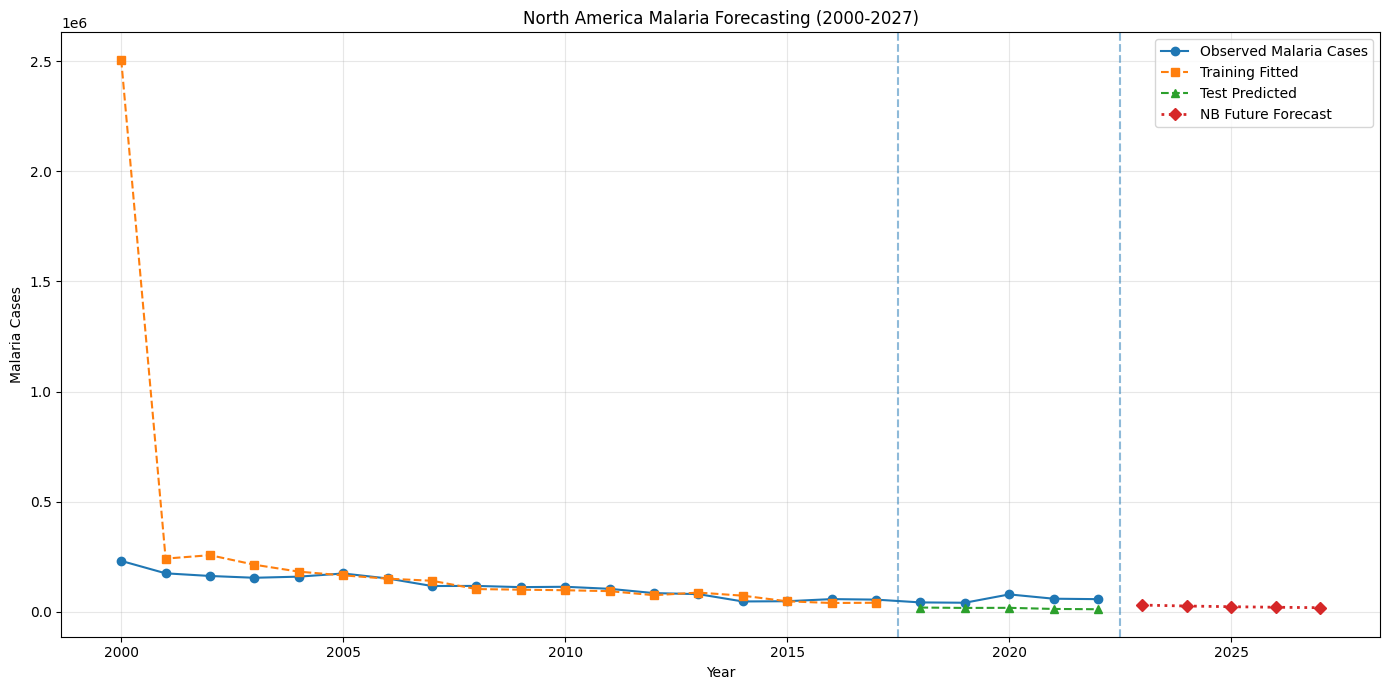

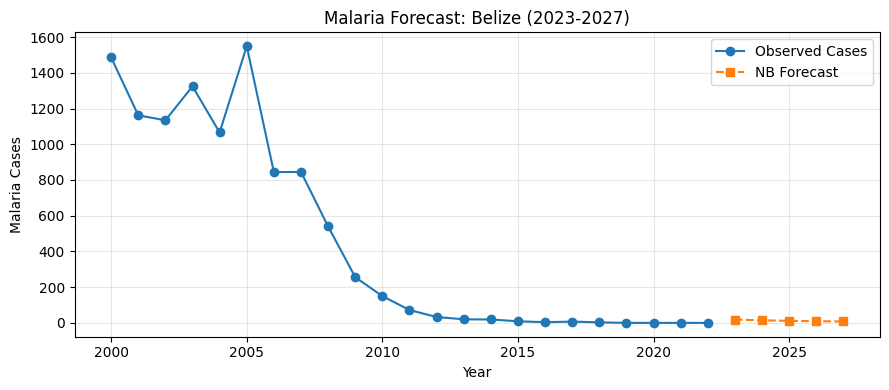

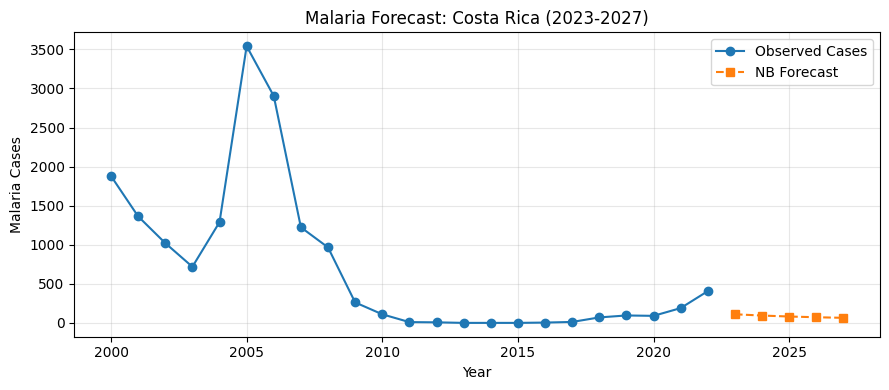

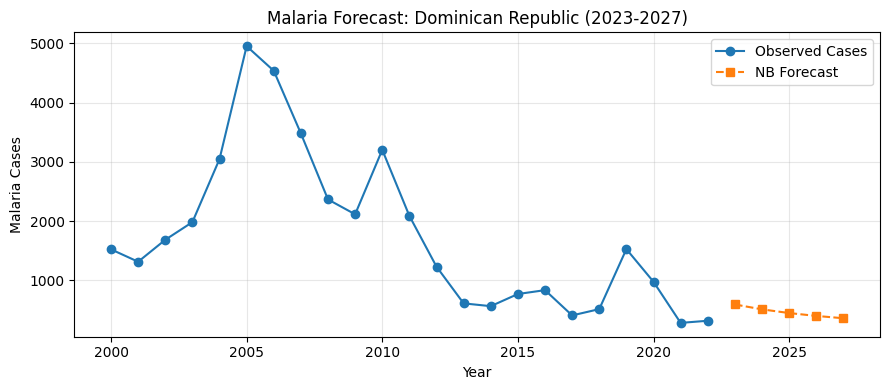

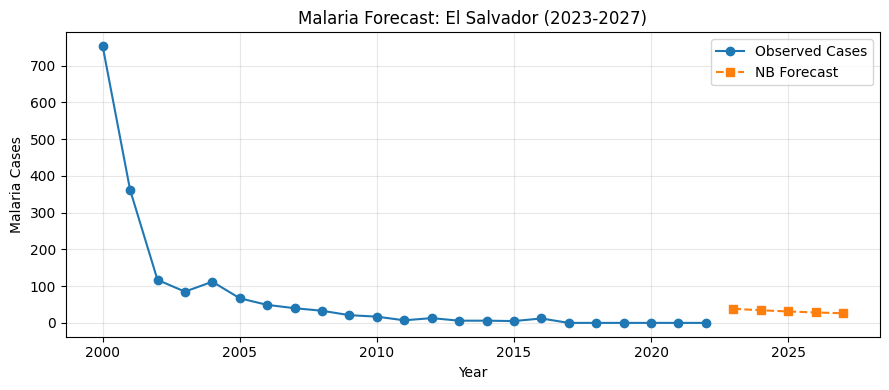

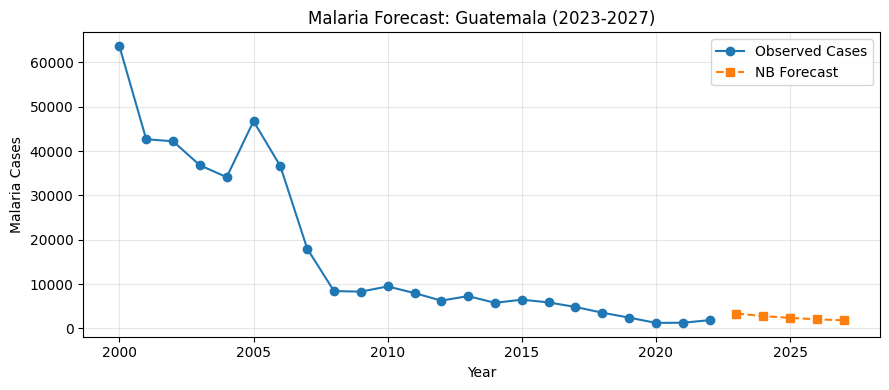

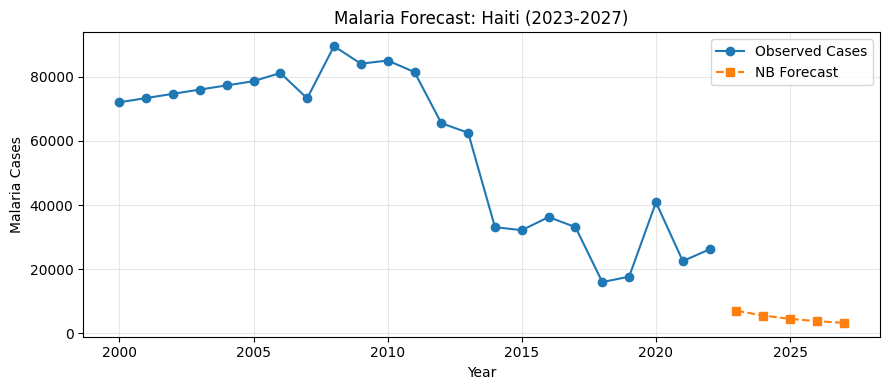

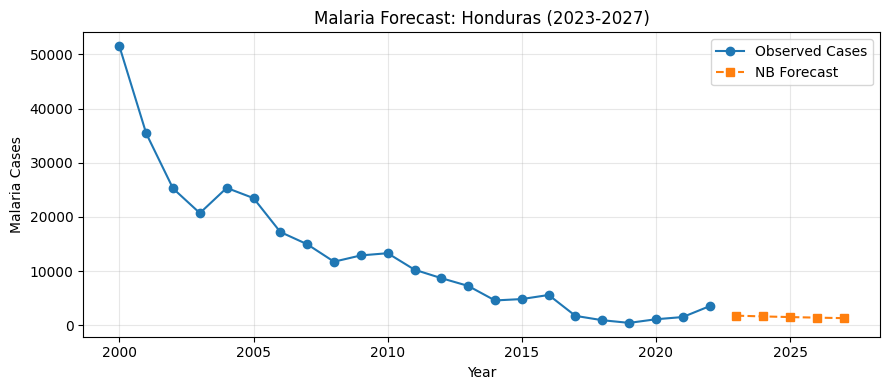

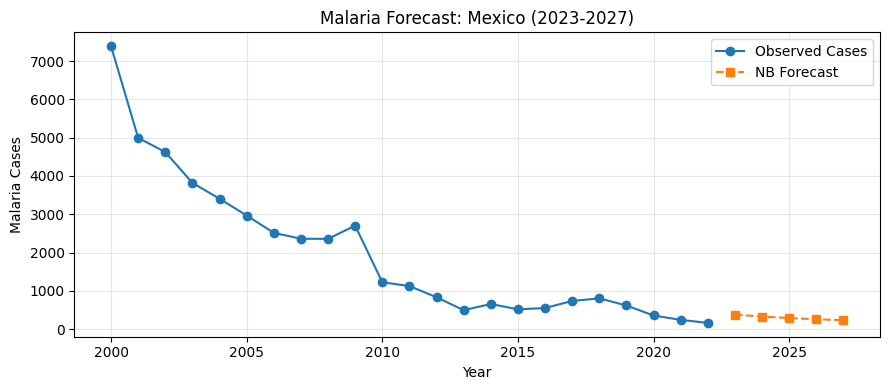

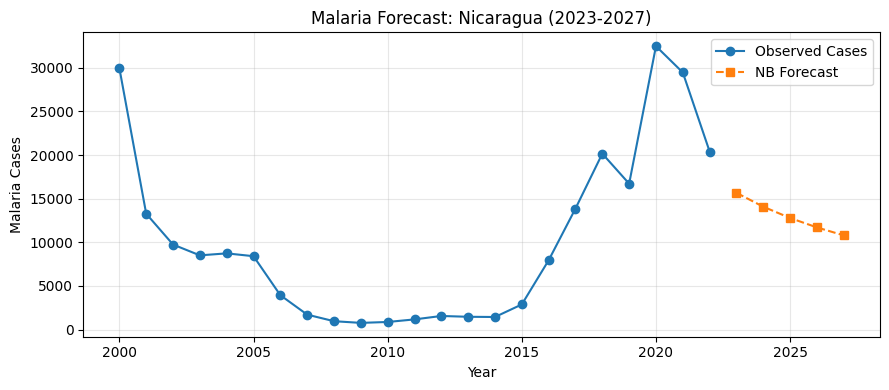

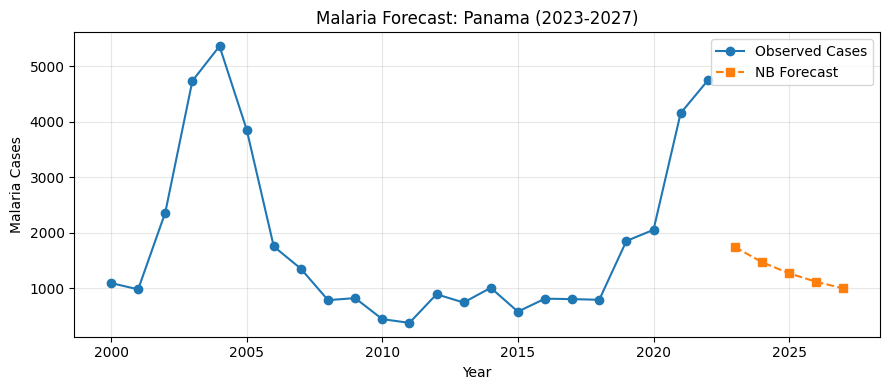


NEGATIVE BINOMIAL FORECAST COMPLETED
TRAIN: 2000-2017
TEST: 2018-2022
FORECAST: 2023-2027
COUNTRIES: 10
PANAMA INCLUDED


In [ ]:

# ============================================================
# NORTH AMERICA MALARIA FORECASTING
# NEGATIVE BINOMIAL (NB2)
#
# TRAINING: 2000-2017
# TESTING:  2018-2022
# FORECAST: 2023-2027
#
# ALL COUNTRIES INCLUDING PANAMA
# ============================================================

!pip -q install statsmodels scikit-learn openpyxl scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings

from google.colab import files
from scipy.stats import theilslopes, nbinom
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

warnings.filterwarnings('ignore')


# ============================================================
# 2. SELECT VARIABLES
# ============================================================

predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6',
    'y8', 'y9', 'y12', 'y16',
    'y17', 'y18', 'y19', 'y20'
]

required = [
    'Country',
    'Year',
    'Malaria cases',
    'y7'
] + predictors

data = df[required].copy()

for col in ['Year', 'Malaria cases', 'y7'] + predictors:
    data[col] = pd.to_numeric(
        data[col],
        errors='coerce'
    )

data = data.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing values before cleaning:")
print(data.isna().sum())

before = len(data)

data = data.dropna().copy()

data = data[
    (data['Year'].between(2000, 2022)) &
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data['Year'] = data['Year'].astype(int)

data = data.sort_values(
    ['Country', 'Year']
).reset_index(drop=True)

print("\nDATA INFORMATION")
print("Observations:", len(data))
print("Removed observations:", before - len(data))
print("Countries:", data['Country'].nunique())
print("Panama included:", 'Panama' in data['Country'].values)

# ============================================================
# 3. FIXED TRAIN-TEST SPLIT
# ============================================================

train = data[
    data['Year'].between(2000, 2017)
].copy().reset_index(drop=True)

test = data[
    data['Year'].between(2018, 2022)
].copy().reset_index(drop=True)

print("\nTRAINING PERIOD: 2000-2017")
print("Training observations:", len(train))

print("\nTESTING PERIOD: 2018-2022")
print("Testing observations:", len(test))

countries = sorted(train['Country'].unique())

if set(test['Country'].unique()) != set(countries):
    raise ValueError("Training and testing country sets differ.")

# ============================================================
# 4. DESIGN MATRIX FUNCTION
# ============================================================

def prepare_design(train_reference, frame):

    means = train_reference[predictors].mean()

    stds = train_reference[predictors].std(ddof=0)

    if (stds == 0).any():
        raise ValueError("Zero variance predictor found.")

    year_center = train_reference['Year'].mean()

    z = (
        frame[predictors] - means
    ) / stds

    z.columns = [
        p + '_z' for p in predictors
    ]

    country_cat = pd.Categorical(
        frame['Country'],
        categories=countries
    )

    dummies = pd.get_dummies(
        pd.Series(country_cat, index=frame.index),
        prefix='Country',
        drop_first=True,
        dtype=float
    )

    dummy_columns = [
        'Country_' + c for c in countries[1:]
    ]

    dummies = dummies.reindex(
        columns=dummy_columns,
        fill_value=0
    )

    X = pd.concat(
        [
            z,
            dummies,
            (frame[['Year']] - year_center).rename(
                columns={'Year': 'Year_c'}
            )
        ],
        axis=1
    )

    X = sm.add_constant(
        X,
        has_constant='add'
    ).astype(float)

    return X, means, stds, year_center


# ============================================================
# 5. TRAINING AND TESTING DESIGN MATRIX
# ============================================================

X_train, train_means, train_stds, year_center = (
    prepare_design(train, train)
)

X_test, _, _, _ = prepare_design(train, test)

y_train = train['Malaria cases'].to_numpy(float)
y_test = test['Malaria cases'].to_numpy(float)

offset_train = np.log(
    train['y7'].to_numpy(float)
)

offset_test = np.log(
    test['y7'].to_numpy(float)
)

# ============================================================
# 6. FIT NEGATIVE BINOMIAL MODEL
# ============================================================

print("\nFITTING NEGATIVE BINOMIAL MODEL...")

nb_model = sm.NegativeBinomial(
    y_train,
    X_train,
    loglike_method='nb2',
    offset=offset_train
)

nb_result = nb_model.fit(
    method='bfgs',
    maxiter=5000,
    disp=False
)

converged = nb_result.mle_retvals.get(
    'converged', False
)

print("\nMODEL CONVERGENCE:", converged)

print("ALPHA:", nb_result.params['alpha'])

if not converged:
    raise ValueError(
        "NB model did not converge. Do not trust its forecasts."
    )

# ============================================================
# 7. TRAIN AND TEST PREDICTION
# ============================================================

train_pred = np.asarray(
    nb_result.predict(
        X_train,
        offset=offset_train
    )
)

test_pred = np.asarray(
    nb_result.predict(
        X_test,
        offset=offset_test
    )
)

if not (
    np.isfinite(train_pred).all() and
    np.isfinite(test_pred).all()
):
    raise ValueError("Non-finite predictions detected.")

# ============================================================
# 8. ACCURACY MEASUREMENT
# ============================================================

performance = pd.DataFrame({

    'Dataset': ['Training', 'Testing'],

    'MSE': [
        mean_squared_error(y_train, train_pred),
        mean_squared_error(y_test, test_pred)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_train, train_pred)),
        np.sqrt(mean_squared_error(y_test, test_pred))
    ],

    'MAE': [
        mean_absolute_error(y_train, train_pred),
        mean_absolute_error(y_test, test_pred)
    ]

})

print("\nNEGATIVE BINOMIAL PERFORMANCE")

display(performance.round(4))

# ============================================================
# 9. TRAINING DIAGNOSTICS
# ============================================================

train_diagnostic = train[
    ['Country', 'Year', 'Malaria cases']
].copy()

train_diagnostic['NB_Predicted'] = train_pred

train_diagnostic['Absolute_Error'] = np.abs(
    y_train - train_pred
)

print("\nTOP 15 TRAINING PREDICTION ERRORS")

display(
    train_diagnostic.sort_values(
        'Absolute_Error',
        ascending=False
    ).head(15).round(2)
)

# ============================================================
# 10. TEST ACTUAL VS PREDICTED
# ============================================================

test_result = test[
    ['Country', 'Year', 'Malaria cases']
].copy()

test_result.rename(
    columns={'Malaria cases': 'Observed_Cases'},
    inplace=True
)

test_result['Predicted_Cases'] = test_pred

test_result['Absolute_Error'] = np.abs(
    test_result['Observed_Cases'] -
    test_result['Predicted_Cases']
)

print("\nTEST RESULTS 2018-2022")

display(test_result.round(2))

# ============================================================
# 11. FINAL MODEL REFIT USING ALL OBSERVED DATA
# ============================================================

# After independent test evaluation, use all known
# observations (2000-2022) for future forecasting.

X_full, full_means, full_stds, full_year_center = (
    prepare_design(data, data)
)

y_full = data['Malaria cases'].to_numpy(float)

offset_full = np.log(
    data['y7'].to_numpy(float)
)

final_nb_model = sm.NegativeBinomial(
    y_full,
    X_full,
    loglike_method='nb2',
    offset=offset_full
)

final_nb_result = final_nb_model.fit(
    method='bfgs',
    maxiter=5000,
    disp=False
)

print("\nFINAL MODEL CONVERGED:",
      final_nb_result.mle_retvals.get('converged', False))

if not final_nb_result.mle_retvals.get('converged', False):
    raise ValueError("Final NB model did not converge.")

# ============================================================
# 12. FUTURE COVARIATE FORECASTING
# ============================================================

# Damped Theil-Sen trend:
# Robust trend based on the latest 10 available years.
# Damping reduces the influence of long-term linear trends.

future_years = np.arange(2023, 2028)

DAMPING = 0.80
LOOKBACK = 10

def damped_trend_forecast(years, values, future_years):

    years = np.asarray(years, dtype=float)
    values = np.asarray(values, dtype=float)

    valid = (
        np.isfinite(years) &
        np.isfinite(values)
    )

    years = years[valid]
    values = values[valid]

    order = np.argsort(years)

    years = years[order]
    values = values[order]

    last_year = years[-1]
    last_value = values[-1]

    recent = years >= last_year - LOOKBACK + 1

    x = years[recent]
    y = values[recent]

    if len(x) < 3 or len(np.unique(y)) < 2:

        return np.repeat(
            last_value,
            len(future_years)
        )

    slope, intercept, low_slope, high_slope = (
        theilslopes(y, x)
    )

    forecasts = []

    for future_year in future_years:

        h = int(future_year - last_year)

        damped_sum = sum(
            DAMPING ** j for j in range(h)
        )

        predicted = (
            last_value + slope * damped_sum
        )

        # Prevent negative projections for
        # historically non-negative indicators.

        if np.min(values) >= 0:
            predicted = max(0, predicted)

        forecasts.append(predicted)

    return np.asarray(forecasts)


# ============================================================
# 13. PROJECT FUTURE POPULATION AND PREDICTORS
# ============================================================

future_rows = []

for country in countries:

    history = data[
        data['Country'] == country
    ].sort_values('Year')

    years_hist = history['Year'].to_numpy(float)

    # Population: project on log scale

    population_forecast = damped_trend_forecast(
        years_hist,
        np.log(history['y7'].to_numpy(float)),
        future_years
    )

    for i, year in enumerate(future_years):

        row = {
            'Country': country,
            'Year': int(year),

            'y7': np.exp(
                population_forecast[i]
            )
        }

        # Project all predictors

        for col in predictors:

            row[col] = damped_trend_forecast(
                years_hist,
                history[col].to_numpy(float),
                future_years
            )[i]

        future_rows.append(row)


future_data = pd.DataFrame(future_rows)

print("\nPROJECTED FUTURE COVARIATES")

display(future_data.head(15).round(3))

# ============================================================
# 14. FUTURE DESIGN MATRIX
# ============================================================

X_future, _, _, _ = prepare_design(
    data,
    future_data
)

offset_future = np.log(
    future_data['y7'].to_numpy(float)
)

# ============================================================
# 15. NB FORECAST 2023-2027
# ============================================================

future_mu = np.asarray(
    final_nb_result.predict(
        X_future,
        offset=offset_future
    )
)

if not np.isfinite(future_mu).all():
    raise ValueError("Invalid future forecast values.")

future_mu = np.maximum(future_mu, 0)

# ============================================================
# 16. NEGATIVE BINOMIAL 95% PREDICTION INTERVAL
# ============================================================

alpha = float(
    final_nb_result.params['alpha']
)

if alpha <= 0:
    raise ValueError("Invalid NB dispersion parameter.")

size = 1 / alpha

prob = size / (size + future_mu)

lower = nbinom.ppf(
    0.025,
    size,
    prob
)

upper = nbinom.ppf(
    0.975,
    size,
    prob
)

# ============================================================
# 17. COUNTRY-WISE FORECAST TABLE
# ============================================================

future_forecast = future_data[
    ['Country', 'Year']
].copy()

future_forecast['Forecasted_Cases'] = future_mu

future_forecast['Lower_95_PI'] = lower

future_forecast['Upper_95_PI'] = upper

print("\nCOUNTRY-WISE MALARIA FORECAST 2023-2027")

display(
    future_forecast.round(2)
)

# ============================================================
# 18. ANNUAL NORTH AMERICA FORECAST
# ============================================================

annual_forecast = future_forecast.groupby(
    'Year'
).agg({

    'Forecasted_Cases': 'sum'

}).reset_index()

print("\nANNUAL MALARIA FORECAST")

display(
    annual_forecast.round(2)
)

# ============================================================
# 19. OBSERVED VS PREDICTED VS FUTURE FORECAST
# ============================================================

annual_actual = data.groupby(
    'Year'
)['Malaria cases'].sum()

annual_train_pred = pd.DataFrame({

    'Year': train['Year'],

    'Predicted': train_pred

}).groupby('Year')['Predicted'].sum()

annual_test_pred = test_result.groupby(
    'Year'
)['Predicted_Cases'].sum()

plt.figure(figsize=(14, 7))

plt.plot(
    annual_actual.index,
    annual_actual.values,
    marker='o',
    label='Observed Malaria Cases'
)

plt.plot(
    annual_train_pred.index,
    annual_train_pred.values,
    linestyle='--',
    marker='s',
    label='Training Fitted'
)

plt.plot(
    annual_test_pred.index,
    annual_test_pred.values,
    linestyle='--',
    marker='^',
    label='Test Predicted'
)

plt.plot(
    annual_forecast['Year'],
    annual_forecast['Forecasted_Cases'],
    linestyle=':',
    marker='D',
    linewidth=2,
    label='NB Future Forecast'
)

plt.axvline(
    2017.5,
    linestyle='--',
    alpha=0.5
)

plt.axvline(
    2022.5,
    linestyle='--',
    alpha=0.5
)

plt.title(
    'North America Malaria Forecasting (2000-2027)'
)

plt.xlabel('Year')
plt.ylabel('Malaria Cases')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'NB_Malaria_Forecast_2000_2027.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 20. COUNTRY-WISE FORECAST GRAPHS
# ============================================================

for country in countries:

    actual_country = data[
        data['Country'] == country
    ]

    forecast_country = future_forecast[
        future_forecast['Country'] == country
    ]

    plt.figure(figsize=(9, 4))

    plt.plot(
        actual_country['Year'],
        actual_country['Malaria cases'],
        marker='o',
        label='Observed Cases'
    )

    plt.plot(
        forecast_country['Year'],
        forecast_country['Forecasted_Cases'],
        marker='s',
        linestyle='--',
        label='NB Forecast'
    )

    plt.title(
        f'Malaria Forecast: {country} (2023-2027)'
    )

    plt.xlabel('Year')
    plt.ylabel('Malaria Cases')

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()

# ============================================================
# 21. EXPORT FINAL RESULTS
# ============================================================

output_file = 'NB_Malaria_Final_Forecast_2027.xlsx'

with pd.ExcelWriter(output_file) as writer:

    performance.to_excel(
        writer,
        sheet_name='Train Test Accuracy',
        index=False
    )

    train_diagnostic.to_excel(
        writer,
        sheet_name='Training Diagnostics',
        index=False
    )

    test_result.to_excel(
        writer,
        sheet_name='Test Results',
        index=False
    )

    future_data.to_excel(
        writer,
        sheet_name='Future Covariates',
        index=False
    )

    future_forecast.to_excel(
        writer,
        sheet_name='Country Forecast',
        index=False
    )

    annual_forecast.to_excel(
        writer,
        sheet_name='Annual Forecast',
        index=False
    )



print("\n====================================")
print("NEGATIVE BINOMIAL FORECAST COMPLETED")
print("TRAIN: 2000-2017")
print("TEST: 2018-2022")
print("FORECAST: 2023-2027")
print("COUNTRIES:", len(countries))
print("PANAMA INCLUDED")
print("====================================")


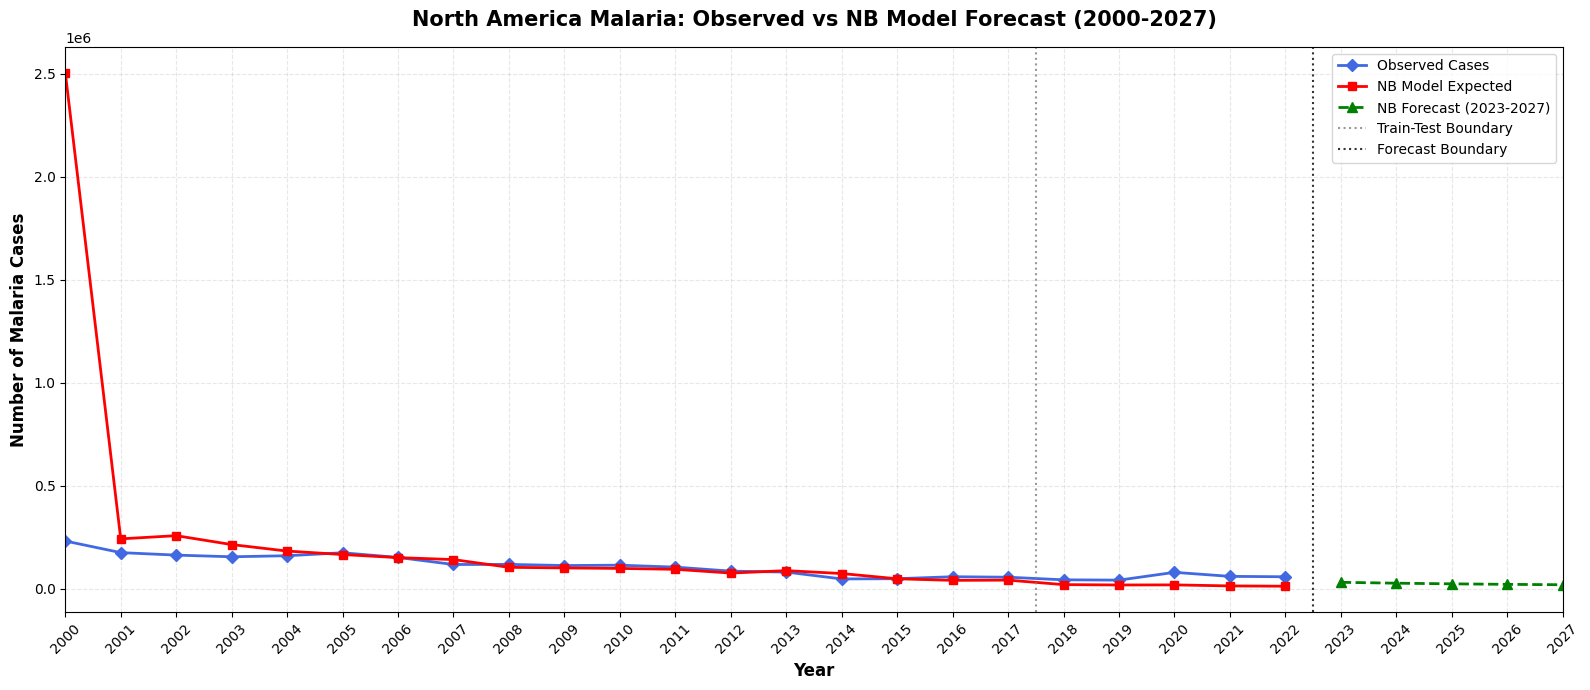


HISTORICAL OBSERVED VS NB EXPECTED


,Year,Observed_Cases,NB_Expected
0,2000,231308,2505910.83
1,2001,174919,241699.46
2,2002,162854,257258.59
3,2003,154713,214011.80
4,2004,159823,182476.07
5,2005,174201,165682.45
6,2006,151566,150644.48
7,2007,117259,141144.36
8,2008,117725,103514.49
9,2009,112224,100592.75



FUTURE NB FORECAST: 2023-2027


,Year,NB_Forecast
0,2023,30755.04
1,2024,26504.85
2,2025,23332.62
3,2026,20873.89
4,2027,18906.48



GRAPH SAVED SUCCESSFULLY!


In [ ]:

# ============================================================
# YEAR-WISE OBSERVED VS NEGATIVE BINOMIAL EXPECTED & FORECAST
# 2000-2027
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. OBSERVED MALARIA CASES (2000-2022)
# ============================================================

observed = data.groupby('Year')[
    'Malaria cases'
].sum().reset_index()

observed.columns = [
    'Year', 'Observed_Cases'
]

# ============================================================
# 2. NB MODEL PREDICTIONS (2000-2017)
# ============================================================

train_predictions = pd.DataFrame({

    'Year': train['Year'].values,

    'NB_Expected': train_pred

})

train_annual = train_predictions.groupby(
    'Year'
)['NB_Expected'].sum().reset_index()

# ============================================================
# 3. NB MODEL PREDICTIONS (2018-2022)
# ============================================================

test_predictions = pd.DataFrame({

    'Year': test['Year'].values,

    'NB_Expected': test_pred

})

test_annual = test_predictions.groupby(
    'Year'
)['NB_Expected'].sum().reset_index()

# ============================================================
# 4. COMBINE HISTORICAL EXPECTED VALUES
# ============================================================

historical_expected = pd.concat(
    [
        train_annual,
        test_annual
    ],
    ignore_index=True
).sort_values('Year')

# ============================================================
# 5. FUTURE NB FORECAST (2023-2027)
# ============================================================

future_annual = future_forecast.groupby(
    'Year'
)['Forecasted_Cases'].sum().reset_index()

# ============================================================
# 6. CREATE FINAL GRAPH
# ============================================================

plt.figure(figsize=(16, 7))

# Observed data

plt.plot(
    observed['Year'],
    observed['Observed_Cases'],
    color='royalblue',
    marker='D',
    markersize=6,
    linewidth=2,
    label='Observed Cases'
)

# NB expected / predicted data

plt.plot(
    historical_expected['Year'],
    historical_expected['NB_Expected'],
    color='red',
    marker='s',
    markersize=6,
    linewidth=2,
    label='NB Model Expected'
)

# NB future forecast

plt.plot(
    future_annual['Year'],
    future_annual['Forecasted_Cases'],
    color='green',
    marker='^',
    markersize=7,
    linewidth=2,
    linestyle='--',
    label='NB Forecast (2023-2027)'
)

# Training and testing boundary

plt.axvline(
    x=2017.5,
    color='gray',
    linestyle=':',
    alpha=0.8,
    label='Train-Test Boundary'
)

plt.axvline(
    x=2022.5,
    color='black',
    linestyle=':',
    alpha=0.8,
    label='Forecast Boundary'
)

# Graph formatting

plt.title(
    'North America Malaria: Observed vs NB Model Forecast (2000-2027)',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel(
    'Year',
    fontsize=12,
    fontweight='bold'
)

plt.ylabel(
    'Number of Malaria Cases',
    fontsize=12,
    fontweight='bold'
)

plt.xticks(
    range(2000, 2028, 1),
    rotation=45
)

plt.xlim(2000, 2027)

plt.grid(
    True,
    linestyle='--',
    alpha=0.3
)

plt.legend(
    loc='best',
    fontsize=10,
    frameon=True
)

plt.tight_layout()

# Save high-resolution graph

plt.savefig(
    'Observed_vs_NB_Forecast_2000_2027.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 7. FINAL YEAR-WISE COMPARISON TABLE
# ============================================================

historical_table = observed.merge(
    historical_expected,
    on='Year',
    how='left'
)

future_table = future_annual.rename(
    columns={
        'Forecasted_Cases': 'NB_Forecast'
    }
)

print("\nHISTORICAL OBSERVED VS NB EXPECTED")

display(historical_table.round(2))

print("\nFUTURE NB FORECAST: 2023-2027")

display(future_table.round(2))

print("\nGRAPH SAVED SUCCESSFULLY!")


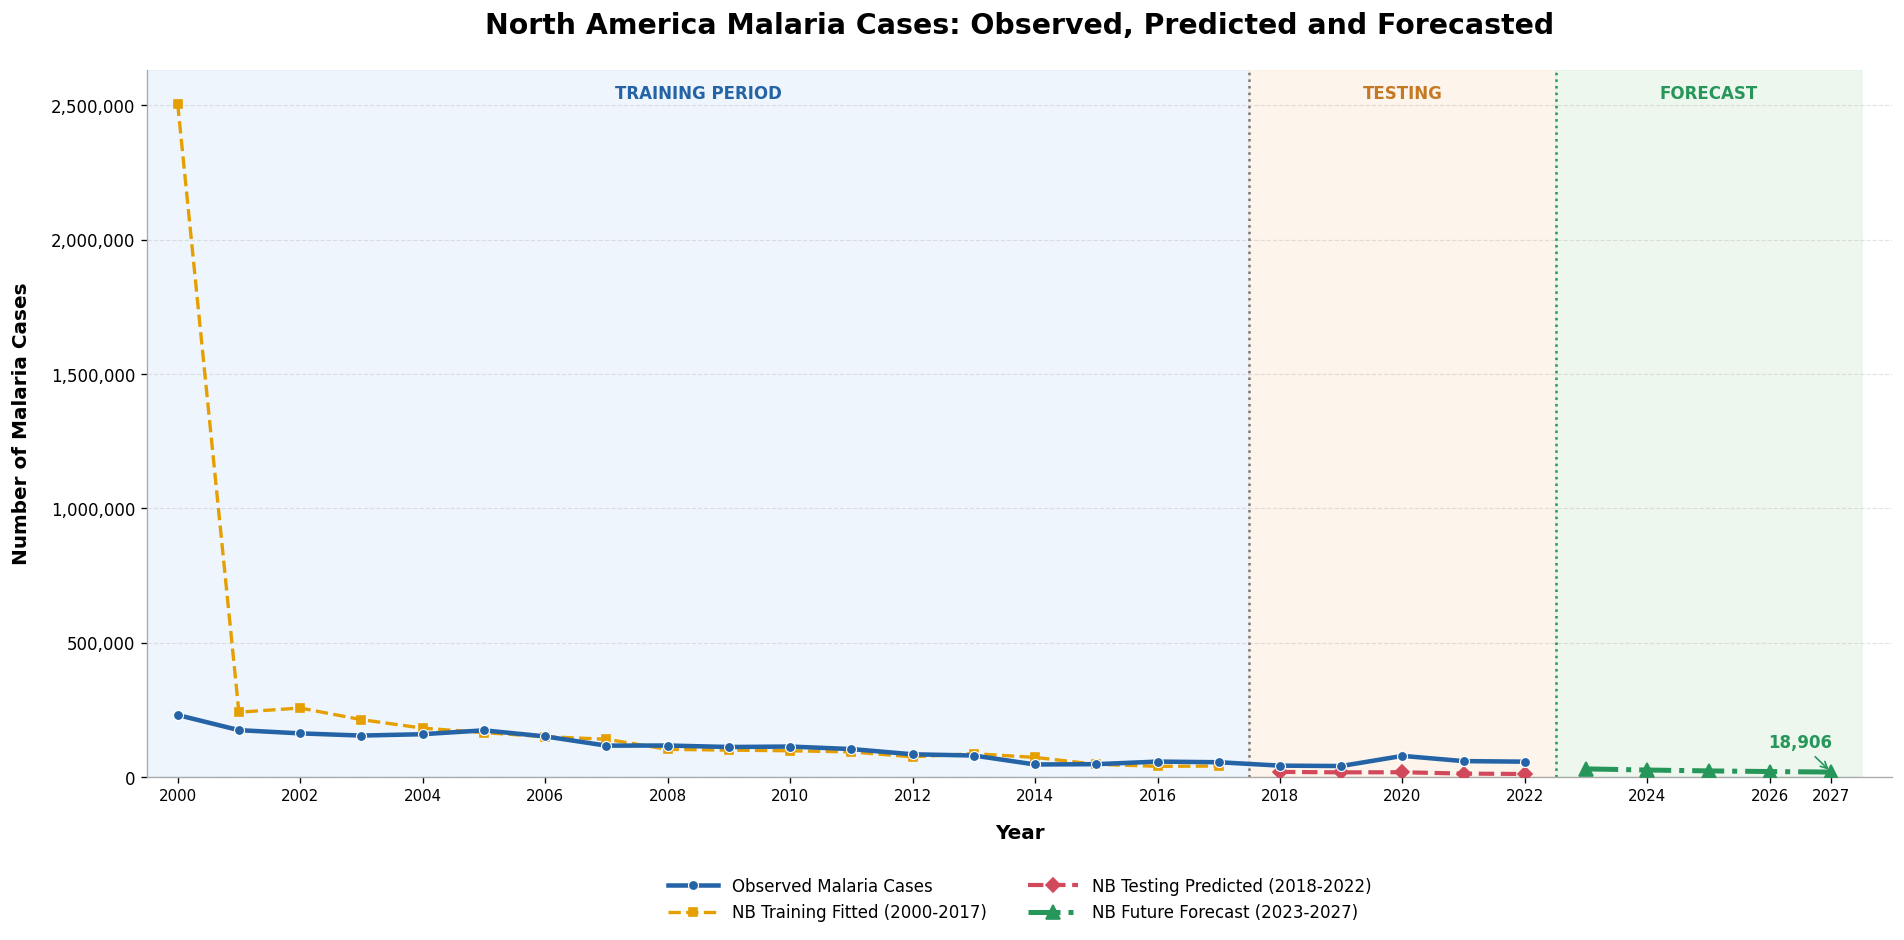

Professional Forecasting Graph Completed!


In [ ]:

# ============================================================
# PROFESSIONAL ACADEMIC FORECASTING GRAPH
# NORTH AMERICA MALARIA (2000-2027)
# NEGATIVE BINOMIAL MODEL
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ============================================================
# 1. PREPARE OBSERVED DATA
# ============================================================

observed = data.groupby('Year', as_index=False).agg(
    Observed_Cases=('Malaria cases', 'sum')
)

# ============================================================
# 2. TRAINING FITTED VALUES
# ============================================================

train_plot = pd.DataFrame({
    'Year': train['Year'].values,
    'NB_Fitted': train_pred
})

train_plot = train_plot.groupby(
    'Year', as_index=False
)['NB_Fitted'].sum()

# ============================================================
# 3. TESTING PREDICTED VALUES
# ============================================================

test_plot = pd.DataFrame({
    'Year': test['Year'].values,
    'NB_Predicted': test_pred
})

test_plot = test_plot.groupby(
    'Year', as_index=False
)['NB_Predicted'].sum()

# ============================================================
# 4. FUTURE FORECAST
# ============================================================

future_plot = future_forecast.groupby(
    'Year', as_index=False
)['Forecasted_Cases'].sum()

# ============================================================
# 5. PROFESSIONAL GRAPH SETTINGS
# ============================================================

plt.rcParams.update({

    'font.family': 'DejaVu Sans',

    'font.size': 11,

    'axes.titlesize': 17,

    'axes.labelsize': 12,

    'legend.fontsize': 10,

    'xtick.labelsize': 9,

    'ytick.labelsize': 10,

    'figure.facecolor': 'white',

    'axes.facecolor': 'white',

    'savefig.facecolor': 'white'

})

fig, ax = plt.subplots(
    figsize=(16, 8),
    dpi=120
)

# ============================================================
# 6. SHADED PERIODS
# ============================================================

# Training period

ax.axvspan(
    1999.5, 2017.5,
    color='#DCEBFA',
    alpha=0.45,
    zorder=0
)

# Testing period

ax.axvspan(
    2017.5, 2022.5,
    color='#FCE8D5',
    alpha=0.45,
    zorder=0
)

# Forecast period

ax.axvspan(
    2022.5, 2027.5,
    color='#DFF2E1',
    alpha=0.55,
    zorder=0
)

# ============================================================
# 7. OBSERVED CASES
# ============================================================

ax.plot(

    observed['Year'],

    observed['Observed_Cases'],

    color='#2463A6',

    marker='o',

    markersize=6,

    linewidth=2.7,

    markeredgecolor='white',

    markeredgewidth=0.7,

    label='Observed Malaria Cases',

    zorder=5

)

# ============================================================
# 8. TRAINING FITTED VALUES
# ============================================================

ax.plot(

    train_plot['Year'],

    train_plot['NB_Fitted'],

    color='#E69F00',

    marker='s',

    markersize=5,

    linewidth=2,

    linestyle='--',

    label='NB Training Fitted (2000-2017)',

    zorder=4

)

# ============================================================
# 9. TESTING PREDICTED VALUES
# ============================================================

ax.plot(

    test_plot['Year'],

    test_plot['NB_Predicted'],

    color='#D1495B',

    marker='D',

    markersize=6,

    linewidth=2.5,

    linestyle='--',

    label='NB Testing Predicted (2018-2022)',

    zorder=4

)

# ============================================================
# 10. FUTURE FORECAST
# ============================================================

ax.plot(

    future_plot['Year'],

    future_plot['Forecasted_Cases'],

    color='#26965A',

    marker='^',

    markersize=8,

    linewidth=3,

    linestyle='-.',

    label='NB Future Forecast (2023-2027)',

    zorder=6

)

# ============================================================
# 11. PERIOD BOUNDARIES
# ============================================================

ax.axvline(
    2017.5,
    color='#777777',
    linestyle=':',
    linewidth=1.5
)

ax.axvline(
    2022.5,
    color='#26965A',
    linestyle=':',
    linewidth=1.5
)

# ============================================================
# 12. PERIOD LABELS
# ============================================================

ax.text(
    2008.5, 0.96,
    'TRAINING PERIOD',
    transform=ax.get_xaxis_transform(),
    ha='center',
    color='#2463A6',
    fontweight='bold',
    fontsize=10
)

ax.text(
    2020, 0.96,
    'TESTING',
    transform=ax.get_xaxis_transform(),
    ha='center',
    color='#C47A24',
    fontweight='bold',
    fontsize=10
)

ax.text(
    2025, 0.96,
    'FORECAST',
    transform=ax.get_xaxis_transform(),
    ha='center',
    color='#26965A',
    fontweight='bold',
    fontsize=10
)

# ============================================================
# 13. LABEL FINAL FORECAST
# ============================================================

last_year = future_plot.iloc[-1]['Year']

last_value = future_plot.iloc[-1]['Forecasted_Cases']

ax.annotate(

    f'{last_value:,.0f}',

    xy=(last_year, last_value),

    xytext=(-38, 15),

    textcoords='offset points',

    fontsize=10,

    fontweight='bold',

    color='#26965A',

    arrowprops=dict(
        arrowstyle='->',
        color='#26965A'
    )

)

# ============================================================
# 14. AXIS FORMATTING
# ============================================================

ax.set_title(

    'North America Malaria Cases: Observed, Predicted and Forecasted',

    fontweight='bold',

    pad=22

)

ax.set_xlabel(
    'Year',
    labelpad=12,
    fontweight='bold'
)

ax.set_ylabel(
    'Number of Malaria Cases',
    labelpad=12,
    fontweight='bold'
)

ax.set_xlim(1999.5, 2028)

ax.set_ylim(bottom=0)

ticks = sorted(
    set(list(range(2000, 2028, 2)) + [2027])
)

ax.set_xticks(ticks)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

# ============================================================
# 15. GRID AND SPINES
# ============================================================

ax.grid(

    axis='y',

    linestyle='--',

    linewidth=0.7,

    alpha=0.35

)

ax.grid(
    axis='x',
    visible=False
)

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#AAAAAA')

ax.spines['bottom'].set_color('#AAAAAA')

# ============================================================
# 16. LEGEND
# ============================================================

ax.legend(

    loc='upper center',

    bbox_to_anchor=(0.5, -0.12),

    ncol=2,

    frameon=False,

    columnspacing=2.5,

    handlelength=3

)

# ============================================================
# 17. FINAL LAYOUT
# ============================================================

plt.tight_layout()

# ============================================================
# 18. SAVE HIGH-QUALITY FILES
# ============================================================

plt.savefig(
    'Malaria_Forecasting_Professional.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    'Malaria_Forecasting_Professional.pdf',
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 19. DOWNLOAD
# ============================================================

from google.colab import files



print("Professional Forecasting Graph Completed!")


Missing values before cleaning:
Country          0
Year             0
Malaria cases    0
y7               0
y1               0
y2               0
y3               0
y5               0
y6               0
y8               0
y9               0
y12              0
y16              0
y17              0
y18              0
y19              0
y20              0
dtype: int64

DATA INFORMATION
Observations: 230
Removed observations: 0
Countries: 10
Panama included: True
Zero counts: 13

TRAINING PERIOD: 2000-2017
Training observations: 180

TESTING PERIOD: 2018-2022
Testing observations: 50

FITTING ZERO-INFLATED NEGATIVE BINOMIAL...
bfgs Converged: True

TRAINING ZINB MODEL
Converged: True
Log Likelihood: -1526.5895292516975
AIC: 3105.179058503395
BIC: 3188.1959366265405
Alpha: 0.4320777932994075
Zero Inflation Probability: 0.01757078033256707

ZERO-INFLATED NEGATIVE BINOMIAL PERFORMANCE


,Dataset,MSE,RMSE,MAE
0,Training,1.181452e+10,108694.5967,12521.6701
1,Testing,8.645941e+07,9298.3553,4541.0263



TOP 15 TRAINING PREDICTION ERRORS


,Country,Year,Malaria cases,ZINB_Predicted,Absolute_Error
90,Haiti,2000,72058,1522030.80,1449972.80
92,Haiti,2002,74701,150364.58,75663.58
91,Haiti,2001,73384,139098.26,65714.26
93,Haiti,2003,76022,130759.11,54737.11
72,Guatemala,2000,63676,115204.83,51528.83
101,Haiti,2011,81483,49738.23,31744.77
98,Haiti,2008,89554,58110.76,31443.24
102,Haiti,2012,65545,36590.38,28954.62
94,Haiti,2004,77327,104159.18,26832.18
103,Haiti,2013,62551,36918.79,25632.21



ZINB TEST RESULTS 2018-2022


,Country,Year,Observed_Cases,ZINB_Predicted,Absolute_Error
0,Belize,2018,3,2.67,0.33
1,Belize,2019,0,1.03,1.03
2,Belize,2020,0,0.52,0.52
3,Belize,2021,0,0.38,0.38
4,Belize,2022,0,2.07,2.07
5,Costa Rica,2018,70,16.56,53.44
6,Costa Rica,2019,95,8.86,86.14
7,Costa Rica,2020,90,1.43,88.57
8,Costa Rica,2021,189,0.80,188.20
9,Costa Rica,2022,406,1.04,404.96


... (2 outputs left out)

Maximum prediction difference: 0.0
Inflation Probability: 0.04534470545425122
Alpha: 0.6712367848078411

COUNTRY-WISE MALARIA FORECAST 2023-2027


,Country,Year,ZINB_Forecasted_Cases,Lower_95_PI,Upper_95_PI,Forecasted_Cases_Rounded
0,Belize,2023,34.29,0.0,113.0,34
1,Belize,2024,26.87,0.0,89.0,27
2,Belize,2025,22.09,0.0,73.0,22
3,Belize,2026,18.73,0.0,62.0,19
4,Belize,2027,16.27,0.0,54.0,16
5,Costa Rica,2023,138.43,0.0,450.0,138
6,Costa Rica,2024,118.33,0.0,385.0,118
7,Costa Rica,2025,103.50,0.0,337.0,103
8,Costa Rica,2026,92.19,0.0,300.0,92
9,Costa Rica,2027,83.33,0.0,271.0,83



ANNUAL MALARIA FORECAST


,Year,Forecasted_Cases
0,2023,35757.91
1,2024,31213.69
2,2025,27791.22
3,2026,25128.46
4,2027,22997.05


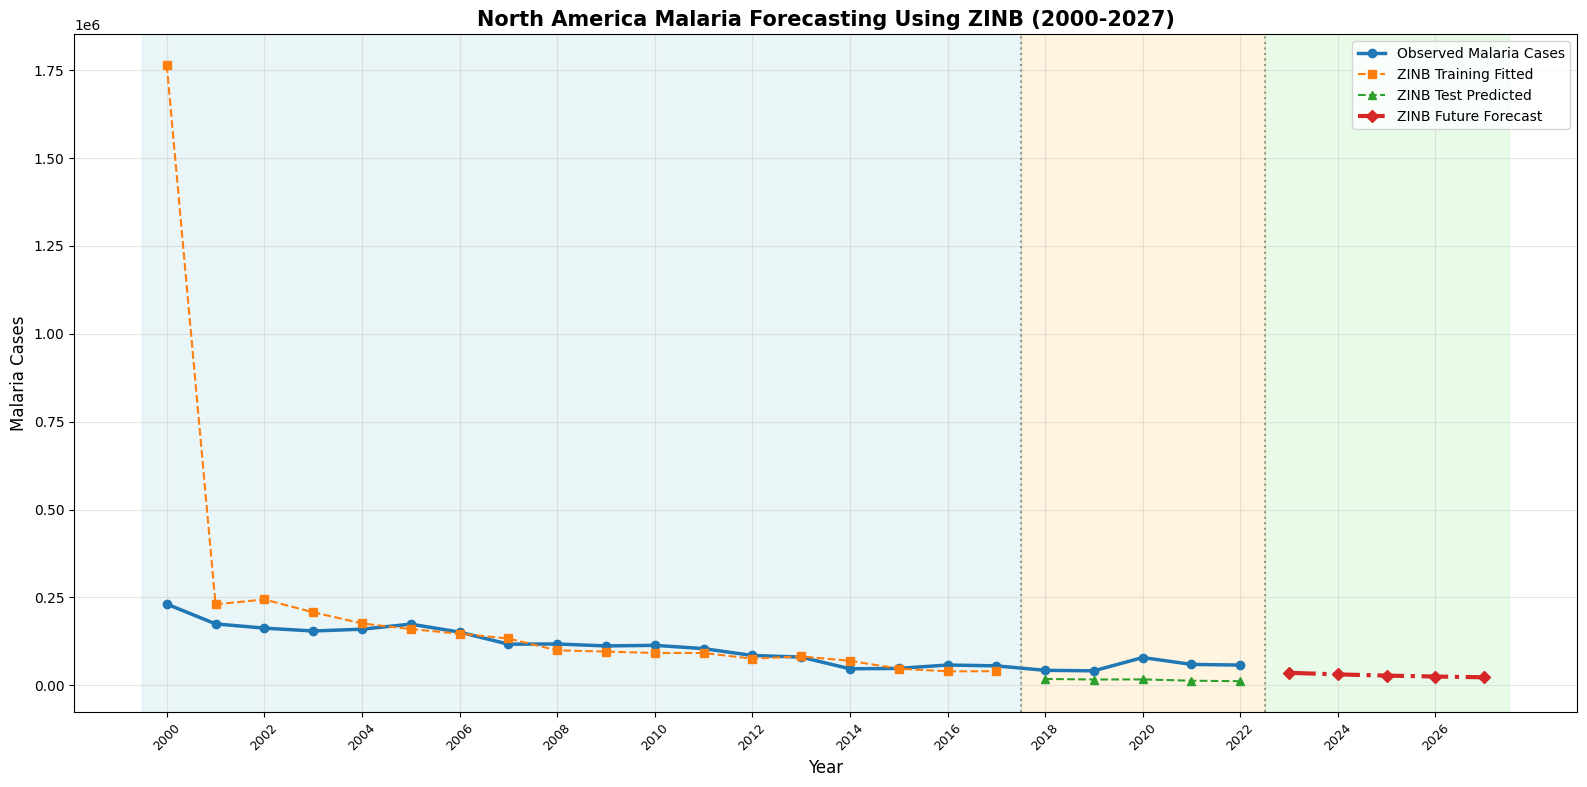

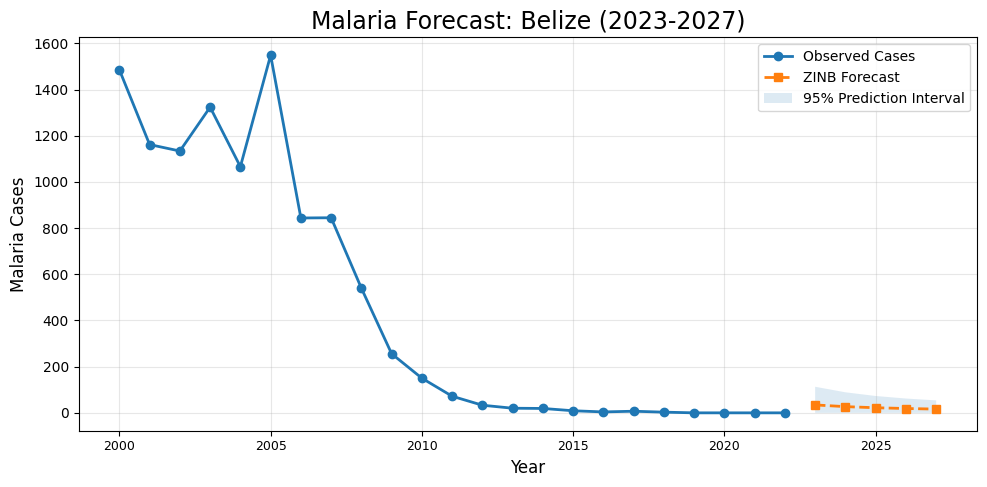

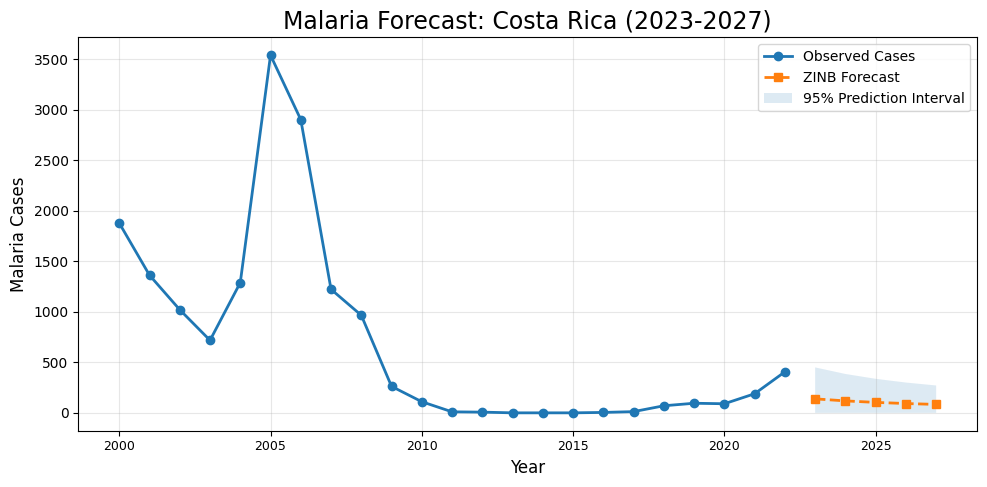

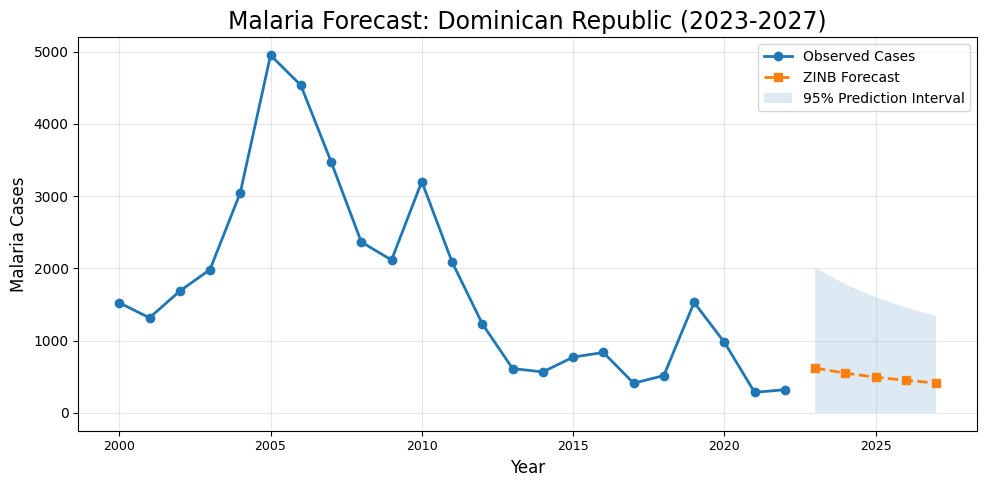

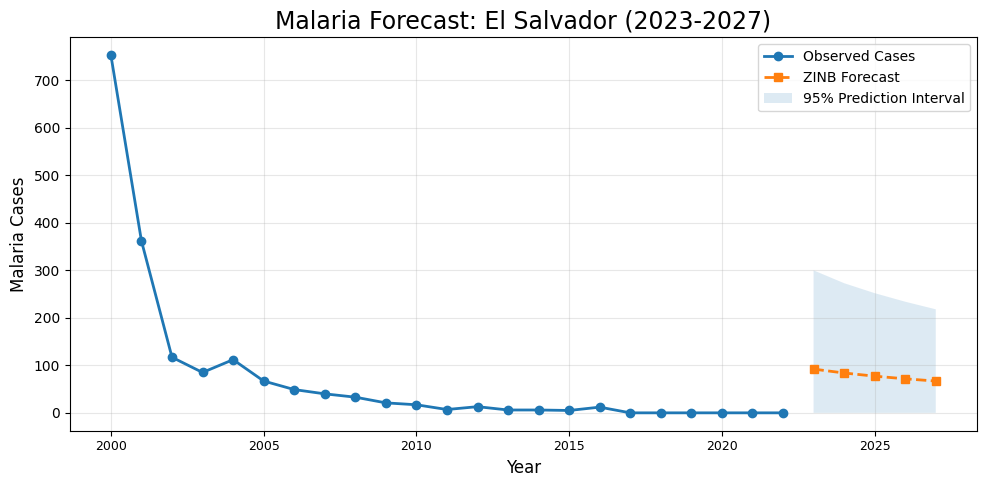

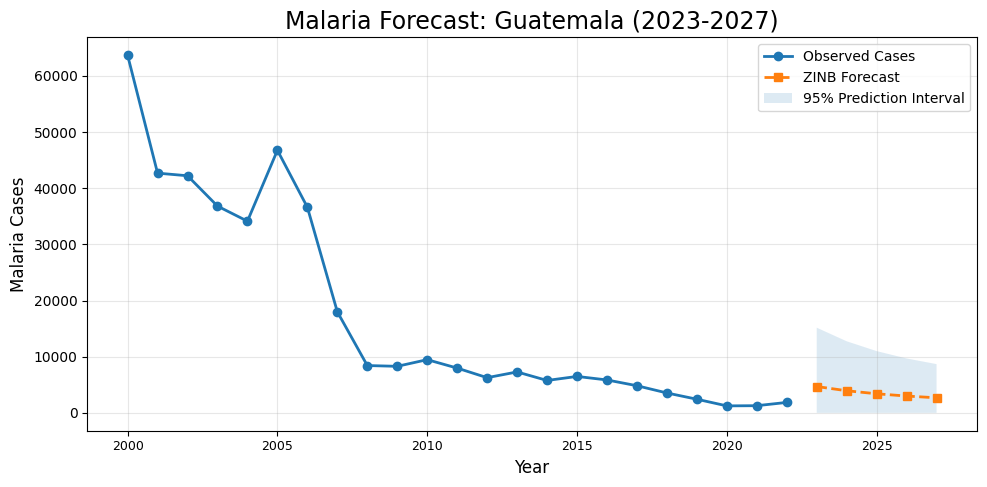

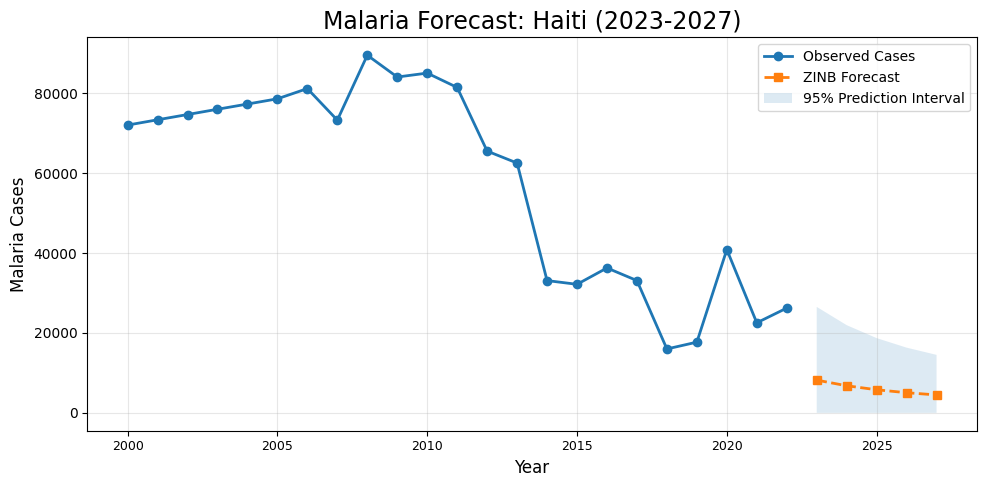

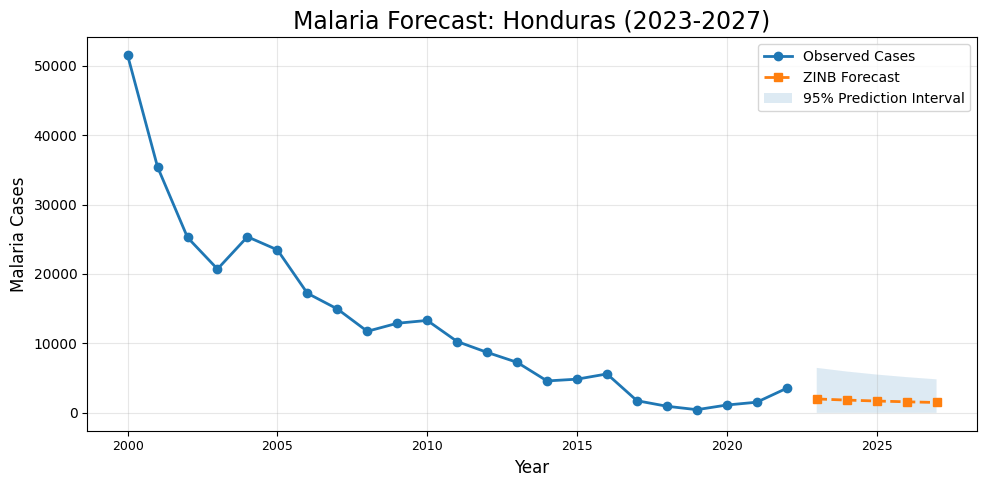

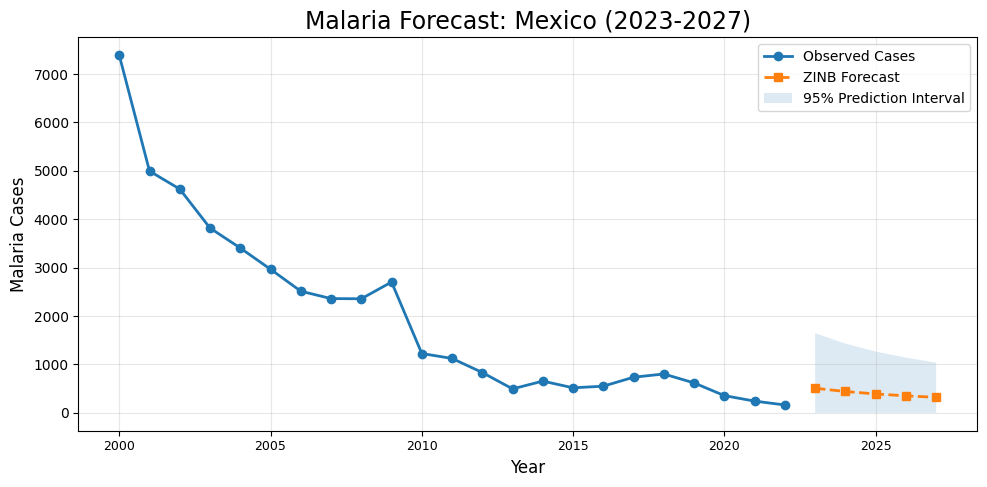

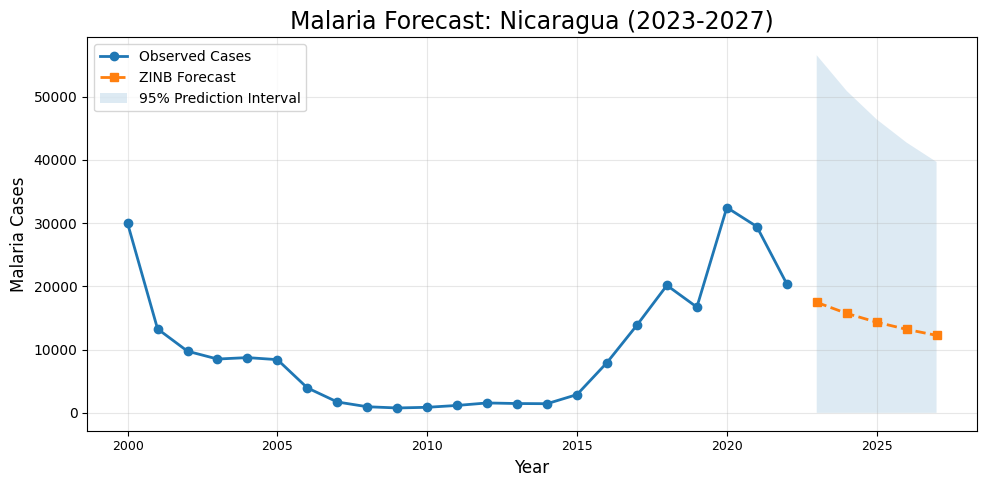

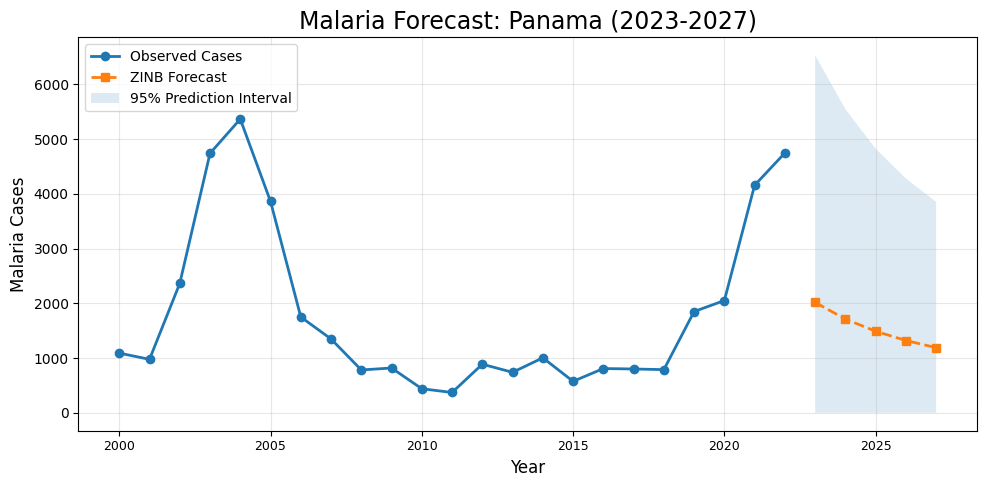


ZERO-INFLATED NEGATIVE BINOMIAL
FORECASTING COMPLETED
TRAIN: 2000-2017
TEST: 2018-2022
FORECAST: 2023-2027
COUNTRIES: 10
PANAMA INCLUDED
ALPHA: 0.6712367848078411
INFLATION PROBABILITY: 0.04534470545425122


In [ ]:

# ============================================================
# NORTH AMERICA MALARIA FORECASTING
# ZERO-INFLATED NEGATIVE BINOMIAL (ZINB)
#
# TRAINING: 2000-2017
# TESTING : 2018-2022
# FORECAST: 2023-2027
#
# ALL COUNTRIES INCLUDING PANAMA
# ============================================================

!pip -q install statsmodels scikit-learn openpyxl scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings

from google.colab import files

from scipy.special import expit
from scipy.stats import theilslopes, nbinom

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from statsmodels.discrete.count_model import (
    ZeroInflatedNegativeBinomialP
)

warnings.filterwarnings('ignore')

# ============================================================
# 1. UPLOAD DATA
# ============================================================


# ============================================================
# 2. SELECT VARIABLES
# ============================================================

predictors = [
    'y1', 'y2', 'y3', 'y5', 'y6',
    'y8', 'y9', 'y12', 'y16',
    'y17', 'y18', 'y19', 'y20'
]

required = [
    'Country',
    'Year',
    'Malaria cases',
    'y7'
] + predictors

data = df[required].copy()

for col in ['Year', 'Malaria cases', 'y7'] + predictors:

    data[col] = pd.to_numeric(
        data[col],
        errors='coerce'
    )

data = data.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing values before cleaning:")
print(data.isna().sum())

before = len(data)

data = data.dropna().copy()

data = data[
    (data['Year'].between(2000, 2022)) &
    (data['Malaria cases'] >= 0) &
    (data['y7'] > 0)
].copy()

data['Year'] = data['Year'].astype(int)

data = data.sort_values(
    ['Country', 'Year']
).reset_index(drop=True)

print("\nDATA INFORMATION")
print("Observations:", len(data))
print("Removed observations:", before - len(data))
print("Countries:", data['Country'].nunique())
print("Panama included:", 'Panama' in data['Country'].values)
print("Zero counts:", (data['Malaria cases'] == 0).sum())

# ============================================================
# 3. FIXED TRAIN-TEST SPLIT
# ============================================================

train = data[
    data['Year'].between(2000, 2017)
].copy().reset_index(drop=True)

test = data[
    data['Year'].between(2018, 2022)
].copy().reset_index(drop=True)

print("\nTRAINING PERIOD: 2000-2017")
print("Training observations:", len(train))

print("\nTESTING PERIOD: 2018-2022")
print("Testing observations:", len(test))

countries = sorted(
    train['Country'].unique()
)

if 'Panama' not in countries:
    raise ValueError("Panama missing from training data.")

if set(test['Country'].unique()) != set(countries):
    raise ValueError("Training and testing country sets differ.")

if data.duplicated(['Country', 'Year']).any():
    raise ValueError("Duplicate Country-Year observations found.")

# ============================================================
# 4. DESIGN MATRIX FUNCTION
# ============================================================

def prepare_design(train_reference, frame):

    means = train_reference[predictors].mean()

    stds = train_reference[predictors].std(ddof=0)

    if (stds == 0).any():
        raise ValueError("Zero variance predictor found.")

    year_center = train_reference['Year'].mean()

    z = (
        frame[predictors] - means
    ) / stds

    z.columns = [
        p + '_z' for p in predictors
    ]

    country_cat = pd.Categorical(
        frame['Country'],
        categories=countries
    )

    dummies = pd.get_dummies(
        pd.Series(country_cat, index=frame.index),
        prefix='Country',
        drop_first=True,
        dtype=float
    )

    dummy_columns = [
        'Country_' + c for c in countries[1:]
    ]

    dummies = dummies.reindex(
        columns=dummy_columns,
        fill_value=0
    )

    X = pd.concat(
        [
            z,
            dummies,
            (frame[['Year']] - year_center).rename(
                columns={'Year': 'Year_c'}
            )
        ],
        axis=1
    )

    X = sm.add_constant(
        X,
        has_constant='add'
    ).astype(float)

    return X

# ============================================================
# 5. TRAINING AND TESTING DESIGN MATRIX
# ============================================================

X_train = prepare_design(train, train)

X_test = prepare_design(train, test)

y_train = train['Malaria cases'].to_numpy(float)

y_test = test['Malaria cases'].to_numpy(float)

offset_train = np.log(
    train['y7'].to_numpy(float)
)

offset_test = np.log(
    test['y7'].to_numpy(float)
)

# Zero-inflation component: intercept only

infl_train = np.ones(
    (len(train), 1)
)

infl_test = np.ones(
    (len(test), 1)
)

# ============================================================
# 6. FIT ZERO-INFLATED NEGATIVE BINOMIAL MODEL
# ============================================================

print("\nFITTING ZERO-INFLATED NEGATIVE BINOMIAL...")

zinb_model = ZeroInflatedNegativeBinomialP(

    endog=y_train,

    exog=X_train,

    exog_infl=infl_train,

    offset=offset_train,

    inflation='logit',

    p=2

)

# ============================================================
# 7. MODEL OPTIMIZATION
# ============================================================

def fit_zinb(model):

    for method in ['bfgs', 'lbfgs']:

        try:

            result = model.fit(
                method=method,
                maxiter=10000,
                disp=False
            )

            converged = result.mle_retvals.get(
                'converged', False
            )

            print(
                method,
                "Converged:",
                converged
            )

            if (
                converged and
                np.isfinite(
                    np.asarray(result.params)
                ).all()
            ):

                return result

        except Exception as e:

            print(method, "failed:", str(e)[:200])

    raise RuntimeError(
        "ZINB model did not converge. "
        "Do not use the forecast until convergence is achieved."
    )


zinb_result = fit_zinb(zinb_model)

print("\nTRAINING ZINB MODEL")
print("===================")

print("Converged:", zinb_result.mle_retvals['converged'])

print("Log Likelihood:", zinb_result.llf)

print("AIC:", zinb_result.aic)

print("BIC:", zinb_result.bic)

print("Alpha:", zinb_result.params['alpha'])

print(
    "Zero Inflation Probability:",
    expit(float(zinb_result.params[0]))
)

# ============================================================
# 8. TRAIN AND TEST PREDICTION
# ============================================================

def zinb_predict(result, X, offset, inflation_X):

    prediction = result.predict(
        exog=X,
        exog_infl=inflation_X,
        offset=offset,
        which='mean'
    )

    return np.asarray(
        prediction
    ).reshape(-1)


train_pred = zinb_predict(
    zinb_result,
    X_train,
    offset_train,
    infl_train
)

test_pred = zinb_predict(
    zinb_result,
    X_test,
    offset_test,
    infl_test
)

if not (
    np.isfinite(train_pred).all() and
    np.isfinite(test_pred).all()
):

    raise ValueError("Non-finite predictions detected.")

# ============================================================
# 9. ACCURACY MEASUREMENT
# ============================================================

performance = pd.DataFrame({

    'Dataset': [
        'Training',
        'Testing'
    ],

    'MSE': [
        mean_squared_error(y_train, train_pred),
        mean_squared_error(y_test, test_pred)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_train, train_pred)),
        np.sqrt(mean_squared_error(y_test, test_pred))
    ],

    'MAE': [
        mean_absolute_error(y_train, train_pred),
        mean_absolute_error(y_test, test_pred)
    ]

})

print("\nZERO-INFLATED NEGATIVE BINOMIAL PERFORMANCE")

display(
    performance.round(4)
)

# ============================================================
# 10. TRAINING DIAGNOSTICS
# ============================================================

train_diagnostic = train[
    ['Country', 'Year', 'Malaria cases']
].copy()

train_diagnostic['ZINB_Predicted'] = train_pred

train_diagnostic['Absolute_Error'] = np.abs(
    y_train - train_pred
)

print("\nTOP 15 TRAINING PREDICTION ERRORS")

display(
    train_diagnostic.sort_values(
        'Absolute_Error',
        ascending=False
    ).head(15).round(2)
)

# ============================================================
# 11. TEST ACTUAL VS PREDICTED
# ============================================================

test_result = test[
    ['Country', 'Year', 'Malaria cases']
].copy()

test_result.rename(
    columns={
        'Malaria cases': 'Observed_Cases'
    },
    inplace=True
)

test_result['ZINB_Predicted'] = test_pred

test_result['Absolute_Error'] = np.abs(
    test_result['Observed_Cases'] -
    test_result['ZINB_Predicted']
)

print("\nZINB TEST RESULTS 2018-2022")

display(
    test_result.round(2)
)

# ============================================================
# 12. FINAL MODEL REFIT USING ALL OBSERVED DATA
# ============================================================

print("\nREFITTING FINAL ZINB MODEL USING 2000-2022")

X_full = prepare_design(data, data)

y_full = data['Malaria cases'].to_numpy(float)

offset_full = np.log(
    data['y7'].to_numpy(float)
)

infl_full = np.ones(
    (len(data), 1)
)

final_zinb_model = ZeroInflatedNegativeBinomialP(

    endog=y_full,

    exog=X_full,

    exog_infl=infl_full,

    offset=offset_full,

    inflation='logit',

    p=2

)

final_zinb_result = fit_zinb(
    final_zinb_model
)

print("\nFINAL ZINB MODEL")

print(
    "Converged:",
    final_zinb_result.mle_retvals['converged']
)

print(
    "Alpha:",
    final_zinb_result.params['alpha']
)

# ============================================================
# 13. FUTURE COVARIATE FORECASTING
# ============================================================

future_years = np.arange(2023, 2028)

DAMPING = 0.80

LOOKBACK = 10


def damped_trend_forecast(years, values, future_years):

    years = np.asarray(years, dtype=float)

    values = np.asarray(values, dtype=float)

    valid = (
        np.isfinite(years) &
        np.isfinite(values)
    )

    years = years[valid]

    values = values[valid]

    order = np.argsort(years)

    years = years[order]

    values = values[order]

    last_year = years[-1]

    last_value = values[-1]

    recent = years >= last_year - LOOKBACK + 1

    x = years[recent]

    y = values[recent]

    if len(x) < 3 or len(np.unique(y)) < 2:

        return np.repeat(
            last_value,
            len(future_years)
        )

    slope, intercept, low_slope, high_slope = (
        theilslopes(y, x)
    )

    forecasts = []

    for future_year in future_years:

        h = int(future_year - last_year)

        damped_sum = sum(
            DAMPING ** j for j in range(h)
        )

        predicted = (
            last_value + slope * damped_sum
        )

        if np.min(values) >= 0:

            predicted = max(0, predicted)

        forecasts.append(predicted)

    return np.asarray(forecasts)


# ============================================================
# 14. PROJECT FUTURE POPULATION AND PREDICTORS
# ============================================================

future_rows = []

percentage_variables = [
    'y5', 'y6', 'y12', 'y16', 'y20'
]

for country in countries:

    history = data[
        data['Country'] == country
    ].sort_values('Year')

    years_hist = history['Year'].to_numpy(float)

    population_forecast = damped_trend_forecast(
        years_hist,
        np.log(history['y7'].to_numpy(float)),
        future_years
    )

    for i, year in enumerate(future_years):

        row = {

            'Country': country,

            'Year': int(year),

            'y7': np.exp(
                population_forecast[i]
            )

        }

        for col in predictors:

            projected = damped_trend_forecast(
                years_hist,
                history[col].to_numpy(float),
                future_years
            )[i]

            # Percentage variables must remain between 0 and 100

            if col in percentage_variables:

                projected = np.clip(
                    projected,
                    0,
                    100
                )

            row[col] = projected

        future_rows.append(row)


future_data = pd.DataFrame(future_rows)

print("\nPROJECTED FUTURE COVARIATES")

display(
    future_data.head(15).round(3)
)

# ============================================================
# 15. FUTURE DESIGN MATRIX
# ============================================================

X_future = prepare_design(
    data,
    future_data
)

offset_future = np.log(
    future_data['y7'].to_numpy(float)
)

infl_future = np.ones(
    (len(future_data), 1)
)

# ============================================================
# 16. ZINB FUTURE FORECAST 2023-2027
# ============================================================

future_mu = zinb_predict(
    final_zinb_result,
    X_future,
    offset_future,
    infl_future
)

if not np.isfinite(future_mu).all():

    raise ValueError("Invalid future forecast values.")

future_mu = np.maximum(
    future_mu,
    0
)

# ============================================================
# 17. CALCULATE CONDITIONAL NB MEAN AND ALPHA
# ============================================================

# Parameter order:
# Inflation parameters + Count parameters + Alpha

params = np.asarray(
    final_zinb_result.params
)

inflation_beta = params[0]

count_beta = params[
    1:1 + X_future.shape[1]
]

alpha = float(params[-1])

if alpha <= 0:

    raise ValueError("Invalid ZINB alpha parameter.")

# Inflation probability

pi = expit(inflation_beta)

# Conditional Negative Binomial mean

eta = (
    X_future.to_numpy() @ count_beta +
    offset_future
)

if np.max(eta) > 50:

    print(
        "WARNING: Extreme conditional prediction detected."
    )

conditional_mu = np.exp(
    np.clip(eta, -700, 700)
)

# Check unconditional expected mean

manual_mean = (
    (1 - pi) * conditional_mu
)

print(
    "Maximum prediction difference:",
    np.max(np.abs(future_mu - manual_mean))
)

print("Inflation Probability:", pi)

print("Alpha:", alpha)

# ============================================================
# 18. ZINB 95% PREDICTION INTERVAL
# ============================================================

# ZINB distribution:
# P(Y=0) = pi + (1-pi)*NB_P(Y=0)
#
# P(Y=k) = (1-pi)*NB_P(Y=k), k > 0

def zinb_quantile(q, mu, alpha, pi):

    mu = np.asarray(mu, dtype=float)

    size = 1 / alpha

    prob = size / (
        size + mu
    )

    nb_zero = nbinom.cdf(
        0,
        size,
        prob
    )

    zinb_zero = (
        pi + (1 - pi) * nb_zero
    )

    result = np.zeros(
        len(mu),
        dtype=float
    )

    if pi >= 1:

        return result

    mask = q > zinb_zero

    conditional_q = (
        (q - pi) / (1 - pi)
    )

    conditional_q = np.clip(
        conditional_q,
        0,
        1 - 1e-12
    )

    result[mask] = nbinom.ppf(
        conditional_q,
        size,
        prob[mask]
    )

    return result


lower = zinb_quantile(
    0.025,
    conditional_mu,
    alpha,
    pi
)

upper = zinb_quantile(
    0.975,
    conditional_mu,
    alpha,
    pi
)

# ============================================================
# 19. COUNTRY-WISE FORECAST TABLE
# ============================================================

future_forecast = future_data[
    ['Country', 'Year']
].copy()

future_forecast['ZINB_Forecasted_Cases'] = future_mu

future_forecast['Lower_95_PI'] = lower

future_forecast['Upper_95_PI'] = upper

future_forecast['Forecasted_Cases_Rounded'] = (
    np.rint(future_mu).astype(int)
)

print("\nCOUNTRY-WISE MALARIA FORECAST 2023-2027")

display(
    future_forecast.round(2)
)

# ============================================================
# 20. ANNUAL NORTH AMERICA FORECAST
# ============================================================

annual_forecast = future_forecast.groupby(
    'Year'
).agg({

    'ZINB_Forecasted_Cases': 'sum'

}).reset_index()

annual_forecast.rename(
    columns={
        'ZINB_Forecasted_Cases': 'Forecasted_Cases'
    },
    inplace=True
)

print("\nANNUAL MALARIA FORECAST")

display(
    annual_forecast.round(2)
)

# ============================================================
# 21. OBSERVED VS PREDICTED VS FUTURE FORECAST
# ============================================================

annual_actual = data.groupby(
    'Year'
)['Malaria cases'].sum()

annual_train_pred = pd.DataFrame({

    'Year': train['Year'],

    'Predicted': train_pred

}).groupby(
    'Year'
)['Predicted'].sum()

annual_test_pred = test_result.groupby(
    'Year'
)['ZINB_Predicted'].sum()

plt.figure(figsize=(16, 8))

plt.axvspan(
    1999.5, 2017.5,
    color='lightblue',
    alpha=0.25
)

plt.axvspan(
    2017.5, 2022.5,
    color='orange',
    alpha=0.12
)

plt.axvspan(
    2022.5, 2027.5,
    color='lightgreen',
    alpha=0.20
)

plt.plot(
    annual_actual.index,
    annual_actual.values,
    marker='o',
    linewidth=2.5,
    label='Observed Malaria Cases'
)

plt.plot(
    annual_train_pred.index,
    annual_train_pred.values,
    linestyle='--',
    marker='s',
    label='ZINB Training Fitted'
)

plt.plot(
    annual_test_pred.index,
    annual_test_pred.values,
    linestyle='--',
    marker='^',
    label='ZINB Test Predicted'
)

plt.plot(
    annual_forecast['Year'],
    annual_forecast['Forecasted_Cases'],
    linestyle='-.',
    marker='D',
    linewidth=3,
    label='ZINB Future Forecast'
)

plt.axvline(
    2017.5,
    linestyle=':',
    color='gray',
    alpha=0.8
)

plt.axvline(
    2022.5,
    linestyle=':',
    color='gray',
    alpha=0.8
)

plt.title(
    'North America Malaria Forecasting Using ZINB (2000-2027)',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Year')

plt.ylabel('Malaria Cases')

plt.xticks(
    range(2000, 2028, 2),
    rotation=45
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'ZINB_Malaria_Forecast_2000_2027.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 22. COUNTRY-WISE FORECAST GRAPHS
# ============================================================

for country in countries:

    actual_country = data[
        data['Country'] == country
    ]

    forecast_country = future_forecast[
        future_forecast['Country'] == country
    ]

    plt.figure(figsize=(10, 5))

    plt.plot(
        actual_country['Year'],
        actual_country['Malaria cases'],
        marker='o',
        linewidth=2,
        label='Observed Cases'
    )

    plt.plot(
        forecast_country['Year'],
        forecast_country['ZINB_Forecasted_Cases'],
        marker='s',
        linestyle='--',
        linewidth=2,
        label='ZINB Forecast'
    )

    plt.fill_between(
        forecast_country['Year'],
        forecast_country['Lower_95_PI'],
        forecast_country['Upper_95_PI'],
        alpha=0.15,
        label='95% Prediction Interval'
    )

    plt.title(
        f'Malaria Forecast: {country} (2023-2027)'
    )

    plt.xlabel('Year')

    plt.ylabel('Malaria Cases')

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

# ============================================================
# 23. EXPORT FINAL RESULTS
# ============================================================

output_file = 'ZINB_Malaria_Final_Forecast_2027.xlsx'

with pd.ExcelWriter(output_file) as writer:

    performance.to_excel(
        writer,
        sheet_name='Train Test Accuracy',
        index=False
    )

    train_diagnostic.to_excel(
        writer,
        sheet_name='Training Diagnostics',
        index=False
    )

    test_result.to_excel(
        writer,
        sheet_name='Test Results',
        index=False
    )

    future_data.to_excel(
        writer,
        sheet_name='Future Covariates',
        index=False
    )

    future_forecast.to_excel(
        writer,
        sheet_name='Country Forecast',
        index=False
    )

    annual_forecast.to_excel(
        writer,
        sheet_name='Annual Forecast',
        index=False
    )

    pd.DataFrame({

        'Parameter': [
            'Alpha',
            'Inflation Probability',
            'Log Likelihood',
            'AIC',
            'BIC',
            'Converged'
        ],

        'Value': [
            alpha,
            pi,
            final_zinb_result.llf,
            final_zinb_result.aic,
            final_zinb_result.bic,
            final_zinb_result.mle_retvals['converged']
        ]

    }).to_excel(
        writer,
        sheet_name='ZINB Parameters',
        index=False
    )



print("\n====================================")
print("ZERO-INFLATED NEGATIVE BINOMIAL")
print("FORECASTING COMPLETED")
print("TRAIN: 2000-2017")
print("TEST: 2018-2022")
print("FORECAST: 2023-2027")
print("COUNTRIES:", len(countries))
print("PANAMA INCLUDED")
print("ALPHA:", alpha)
print("INFLATION PROBABILITY:", pi)
print("====================================")


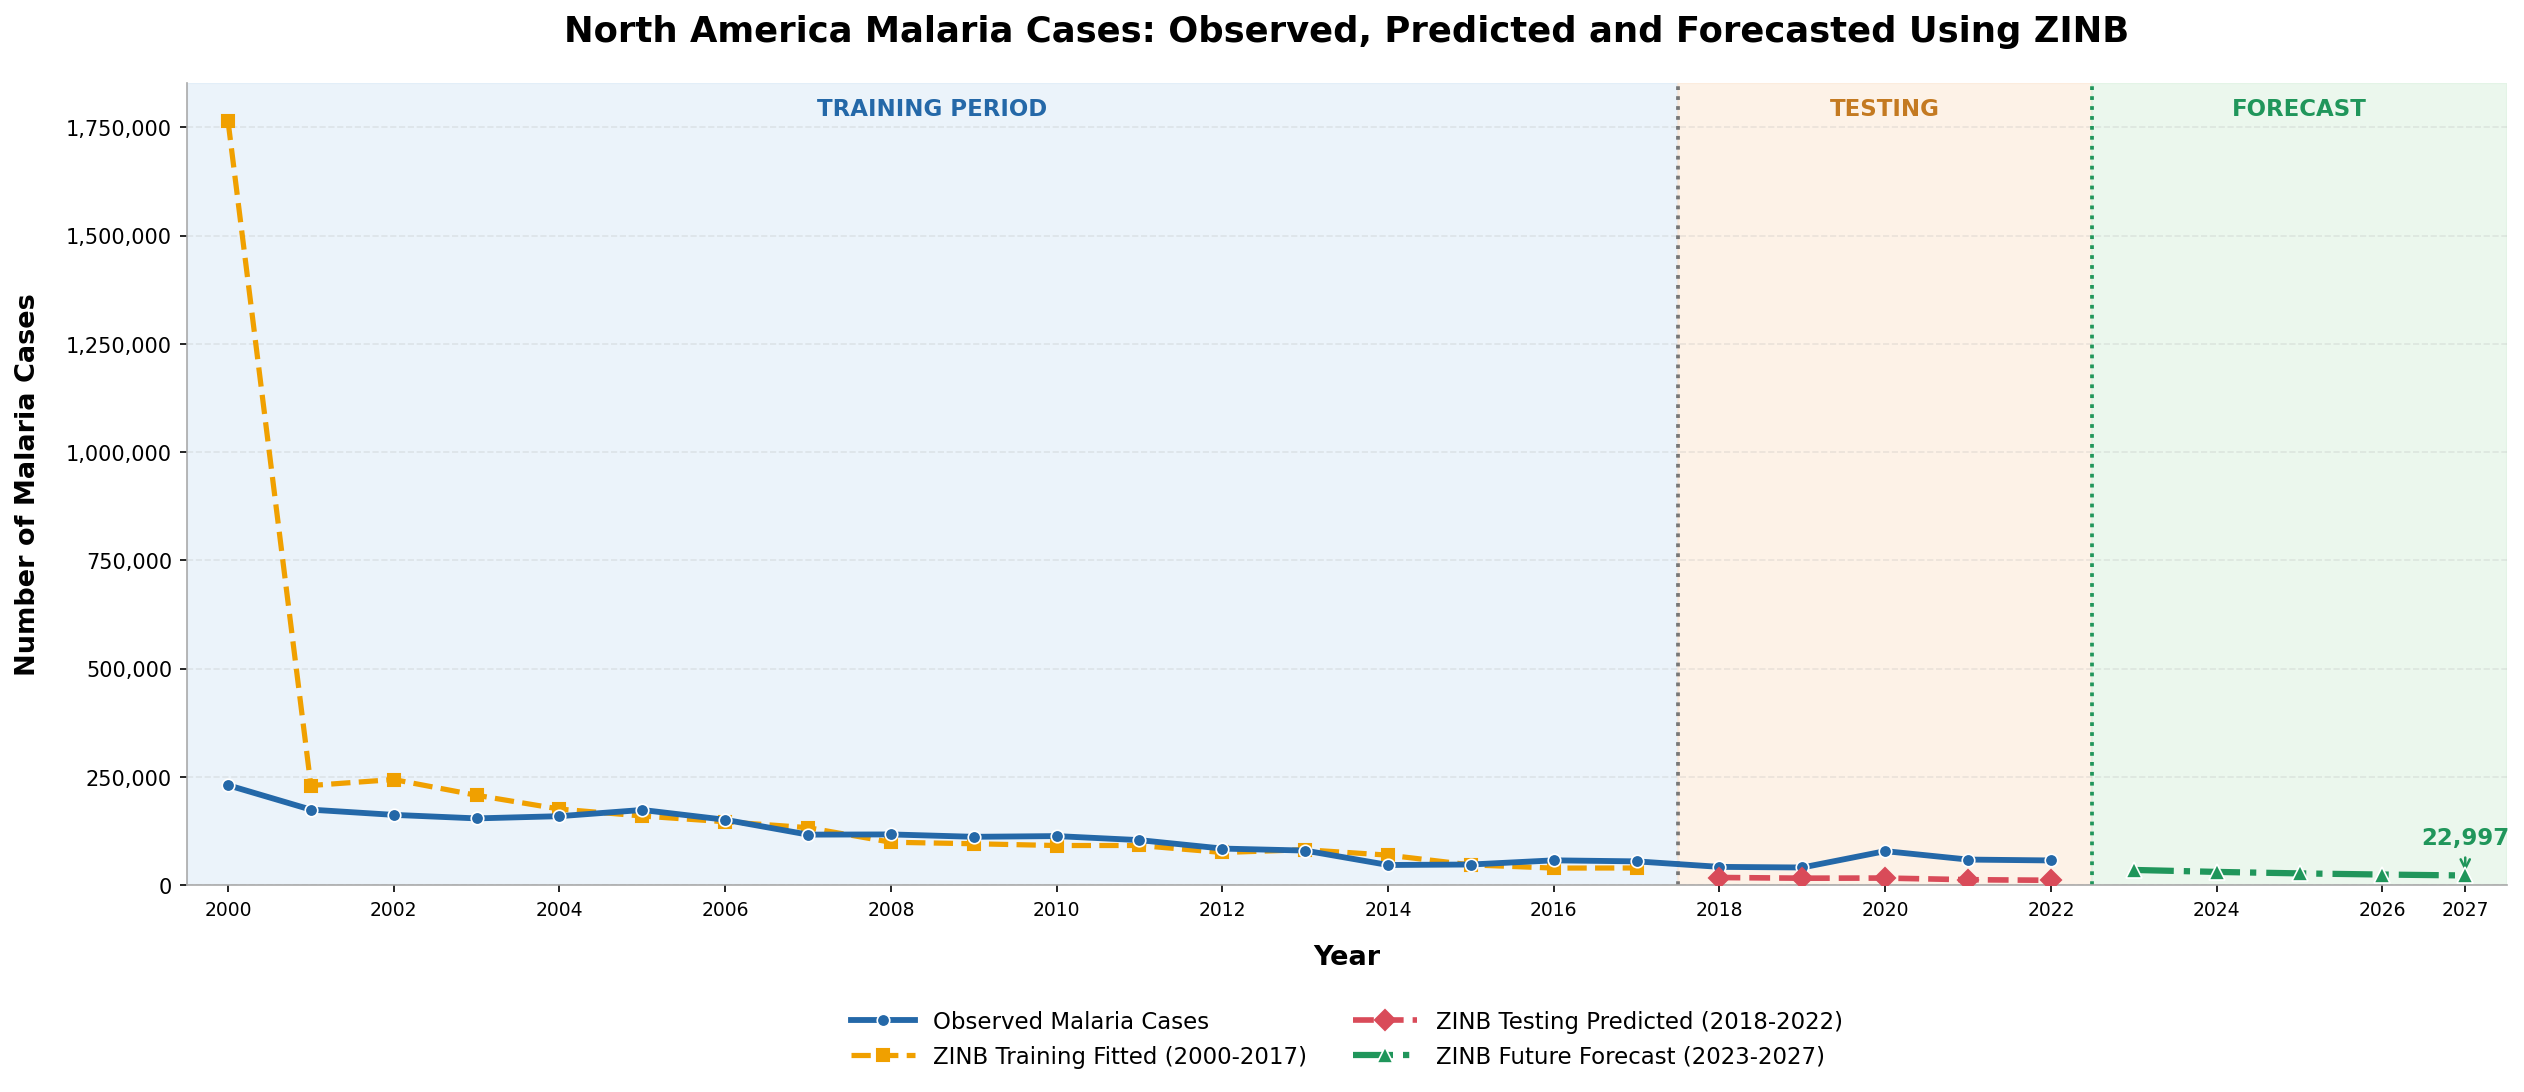


OBSERVED MALARIA CASES


,Year,Observed_Cases
0,2000,231308
1,2001,174919
2,2002,162854
3,2003,154713
4,2004,159823
5,2005,174201
6,2006,151566
7,2007,117259
8,2008,117725
9,2009,112224



ZINB TRAINING FITTED


,Predicted
Year,
2000,1764458.68
2001,230635.89
2002,244403.68
2003,208080.00
2004,176266.06
2005,160157.58
2006,146950.51
2007,133345.43
2008,99664.84



ZINB TEST PREDICTED


,Predicted
Year,
2018,18296.71
2019,16700.11
2020,17009.25
2021,13207.14
2022,11901.30



ZINB FUTURE FORECAST


,ZINB_Forecasted_Cases
Year,
2023,35757.91
2024,31213.69
2025,27791.22
2026,25128.46
2027,22997.05



ZINB OVERALL GRAPH COMPLETED!


In [ ]:

# ============================================================
# PROFESSIONAL ZINB OVERALL MALARIA FORECAST GRAPH
# 2000-2027 | NORTH AMERICA INCLUDING PANAMA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ============================================================
# 1. OBSERVED ANNUAL DATA
# ============================================================

observed_annual = data.groupby(
    'Year'
)['Malaria cases'].sum()

# ============================================================
# 2. ZINB TRAINING FITTED
# ============================================================

# IMPORTANT:
# train_pred must be generated from ZINB model

zinb_training = pd.DataFrame({

    'Year': train['Year'].values,

    'Predicted': np.asarray(train_pred).ravel()

})

zinb_training_annual = zinb_training.groupby(
    'Year'
)['Predicted'].sum()

# ============================================================
# 3. ZINB TEST PREDICTED
# ============================================================

# IMPORTANT:
# test_pred must be generated from ZINB model

zinb_testing = pd.DataFrame({

    'Year': test['Year'].values,

    'Predicted': np.asarray(test_pred).ravel()

})

zinb_testing_annual = zinb_testing.groupby(
    'Year'
)['Predicted'].sum()

# ============================================================
# 4. ZINB FUTURE FORECAST
# ============================================================

zinb_forecast_annual = future_forecast.groupby(
    'Year'
)['ZINB_Forecasted_Cases'].sum()

# ============================================================
# 5. CREATE PROFESSIONAL FIGURE
# ============================================================

plt.rcParams.update({

    'font.family': 'DejaVu Sans',

    'font.size': 11,

    'axes.titlesize': 18,

    'axes.labelsize': 13,

    'legend.fontsize': 11

})

fig, ax = plt.subplots(
    figsize=(17, 8),
    dpi=150
)

fig.patch.set_facecolor('white')

ax.set_facecolor('white')

# ============================================================
# 6. BACKGROUND PERIODS
# ============================================================

# Training

ax.axvspan(
    1999.5,
    2017.5,
    color='#DCEAF7',
    alpha=0.55,
    zorder=0
)

# Testing

ax.axvspan(
    2017.5,
    2022.5,
    color='#FCE8D5',
    alpha=0.55,
    zorder=0
)

# Forecast

ax.axvspan(
    2022.5,
    2027.5,
    color='#DFF2E2',
    alpha=0.60,
    zorder=0
)

# ============================================================
# 7. OBSERVED CASES
# ============================================================

ax.plot(

    observed_annual.index,

    observed_annual.values,

    color='#2468A8',

    linewidth=2.8,

    marker='o',

    markersize=6,

    markeredgecolor='white',

    markeredgewidth=0.8,

    label='Observed Malaria Cases',

    zorder=5

)

# ============================================================
# 8. ZINB TRAINING FITTED
# ============================================================

ax.plot(

    zinb_training_annual.index,

    zinb_training_annual.values,

    color='#F0A000',

    linewidth=2.5,

    linestyle='--',

    marker='s',

    markersize=6,

    label='ZINB Training Fitted (2000-2017)',

    zorder=4

)

# ============================================================
# 9. ZINB TEST PREDICTED
# ============================================================

ax.plot(

    zinb_testing_annual.index,

    zinb_testing_annual.values,

    color='#D94B59',

    linewidth=2.7,

    linestyle='--',

    marker='D',

    markersize=7,

    label='ZINB Testing Predicted (2018-2022)',

    zorder=5

)

# ============================================================
# 10. ZINB FUTURE FORECAST
# ============================================================

ax.plot(

    zinb_forecast_annual.index,

    zinb_forecast_annual.values,

    color='#20965B',

    linewidth=3,

    linestyle='-.',

    marker='^',

    markersize=8,

    markeredgecolor='white',

    markeredgewidth=0.8,

    label='ZINB Future Forecast (2023-2027)',

    zorder=6

)

# ============================================================
# 11. PERIOD SEPARATORS
# ============================================================

ax.axvline(

    2017.5,

    color='#777777',

    linestyle=':',

    linewidth=1.8

)

ax.axvline(

    2022.5,

    color='#20965B',

    linestyle=':',

    linewidth=1.8

)

# ============================================================
# 12. PERIOD TITLES
# ============================================================

y_axis_transform = ax.get_xaxis_transform()

ax.text(

    2008.5,

    0.96,

    'TRAINING PERIOD',

    transform=y_axis_transform,

    ha='center',

    color='#2468A8',

    fontweight='bold',

    fontsize=11

)

ax.text(

    2020,

    0.96,

    'TESTING',

    transform=y_axis_transform,

    ha='center',

    color='#C47A21',

    fontweight='bold',

    fontsize=11

)

ax.text(

    2025,

    0.96,

    'FORECAST',

    transform=y_axis_transform,

    ha='center',

    color='#20965B',

    fontweight='bold',

    fontsize=11

)

# ============================================================
# 13. ANNOTATE 2027 FORECAST
# ============================================================

last_year = zinb_forecast_annual.index[-1]

last_value = zinb_forecast_annual.iloc[-1]

ax.annotate(

    f'{last_value:,.0f}',

    xy=(last_year, last_value),

    xytext=(0, 15),

    textcoords='offset points',

    ha='center',

    color='#20965B',

    fontsize=11,

    fontweight='bold',

    arrowprops=dict(
        arrowstyle='->',
        color='#20965B',
        lw=1.2
    )

)

# ============================================================
# 14. TITLE AND AXIS LABELS
# ============================================================

ax.set_title(

    'North America Malaria Cases: Observed, Predicted and Forecasted Using ZINB',

    fontsize=17,

    fontweight='bold',

    pad=20

)

ax.set_xlabel(

    'Year',

    fontsize=13,

    fontweight='bold',

    labelpad=12

)

ax.set_ylabel(

    'Number of Malaria Cases',

    fontsize=13,

    fontweight='bold',

    labelpad=12

)

# ============================================================
# 15. AXIS FORMATTING
# ============================================================

ax.set_xlim(
    1999.5,
    2027.5
)

ax.set_xticks(
    list(range(2000, 2028, 2)) + [2027]
)

ax.yaxis.set_major_formatter(

    FuncFormatter(
        lambda x, pos: f'{x:,.0f}'
    )

)

ax.set_ylim(
    bottom=0
)

# ============================================================
# 16. GRID AND SPINES
# ============================================================

ax.grid(

    axis='y',

    linestyle='--',

    linewidth=0.8,

    alpha=0.25

)

ax.grid(
    axis='x',
    visible=False
)

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#AAAAAA')

ax.spines['bottom'].set_color('#AAAAAA')

# ============================================================
# 17. LEGEND
# ============================================================

ax.legend(

    loc='upper center',

    bbox_to_anchor=(0.5, -0.13),

    ncol=2,

    frameon=False,

    fontsize=11,

    handlelength=2.8

)

# ============================================================
# 18. SAVE HIGH RESOLUTION GRAPH
# ============================================================

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.savefig(

    'North_America_ZINB_Overall_Forecast.png',

    dpi=600,

    bbox_inches='tight',

    facecolor='white'

)

plt.savefig(

    'North_America_ZINB_Overall_Forecast.pdf',

    bbox_inches='tight',

    facecolor='white'

)

plt.show()

# ============================================================
# 19. DISPLAY ANNUAL RESULTS
# ============================================================

print("\nOBSERVED MALARIA CASES")

display(
    observed_annual.rename(
        'Observed_Cases'
    ).reset_index().round(2)
)

print("\nZINB TRAINING FITTED")

display(
    zinb_training_annual.round(2)
)

print("\nZINB TEST PREDICTED")

display(
    zinb_testing_annual.round(2)
)

print("\nZINB FUTURE FORECAST")

display(
    zinb_forecast_annual.round(2)
)

print("\nZINB OVERALL GRAPH COMPLETED!")


STUDY AREA INFORMATION
Total countries: 10
Countries mapped: 10
Panama included: True


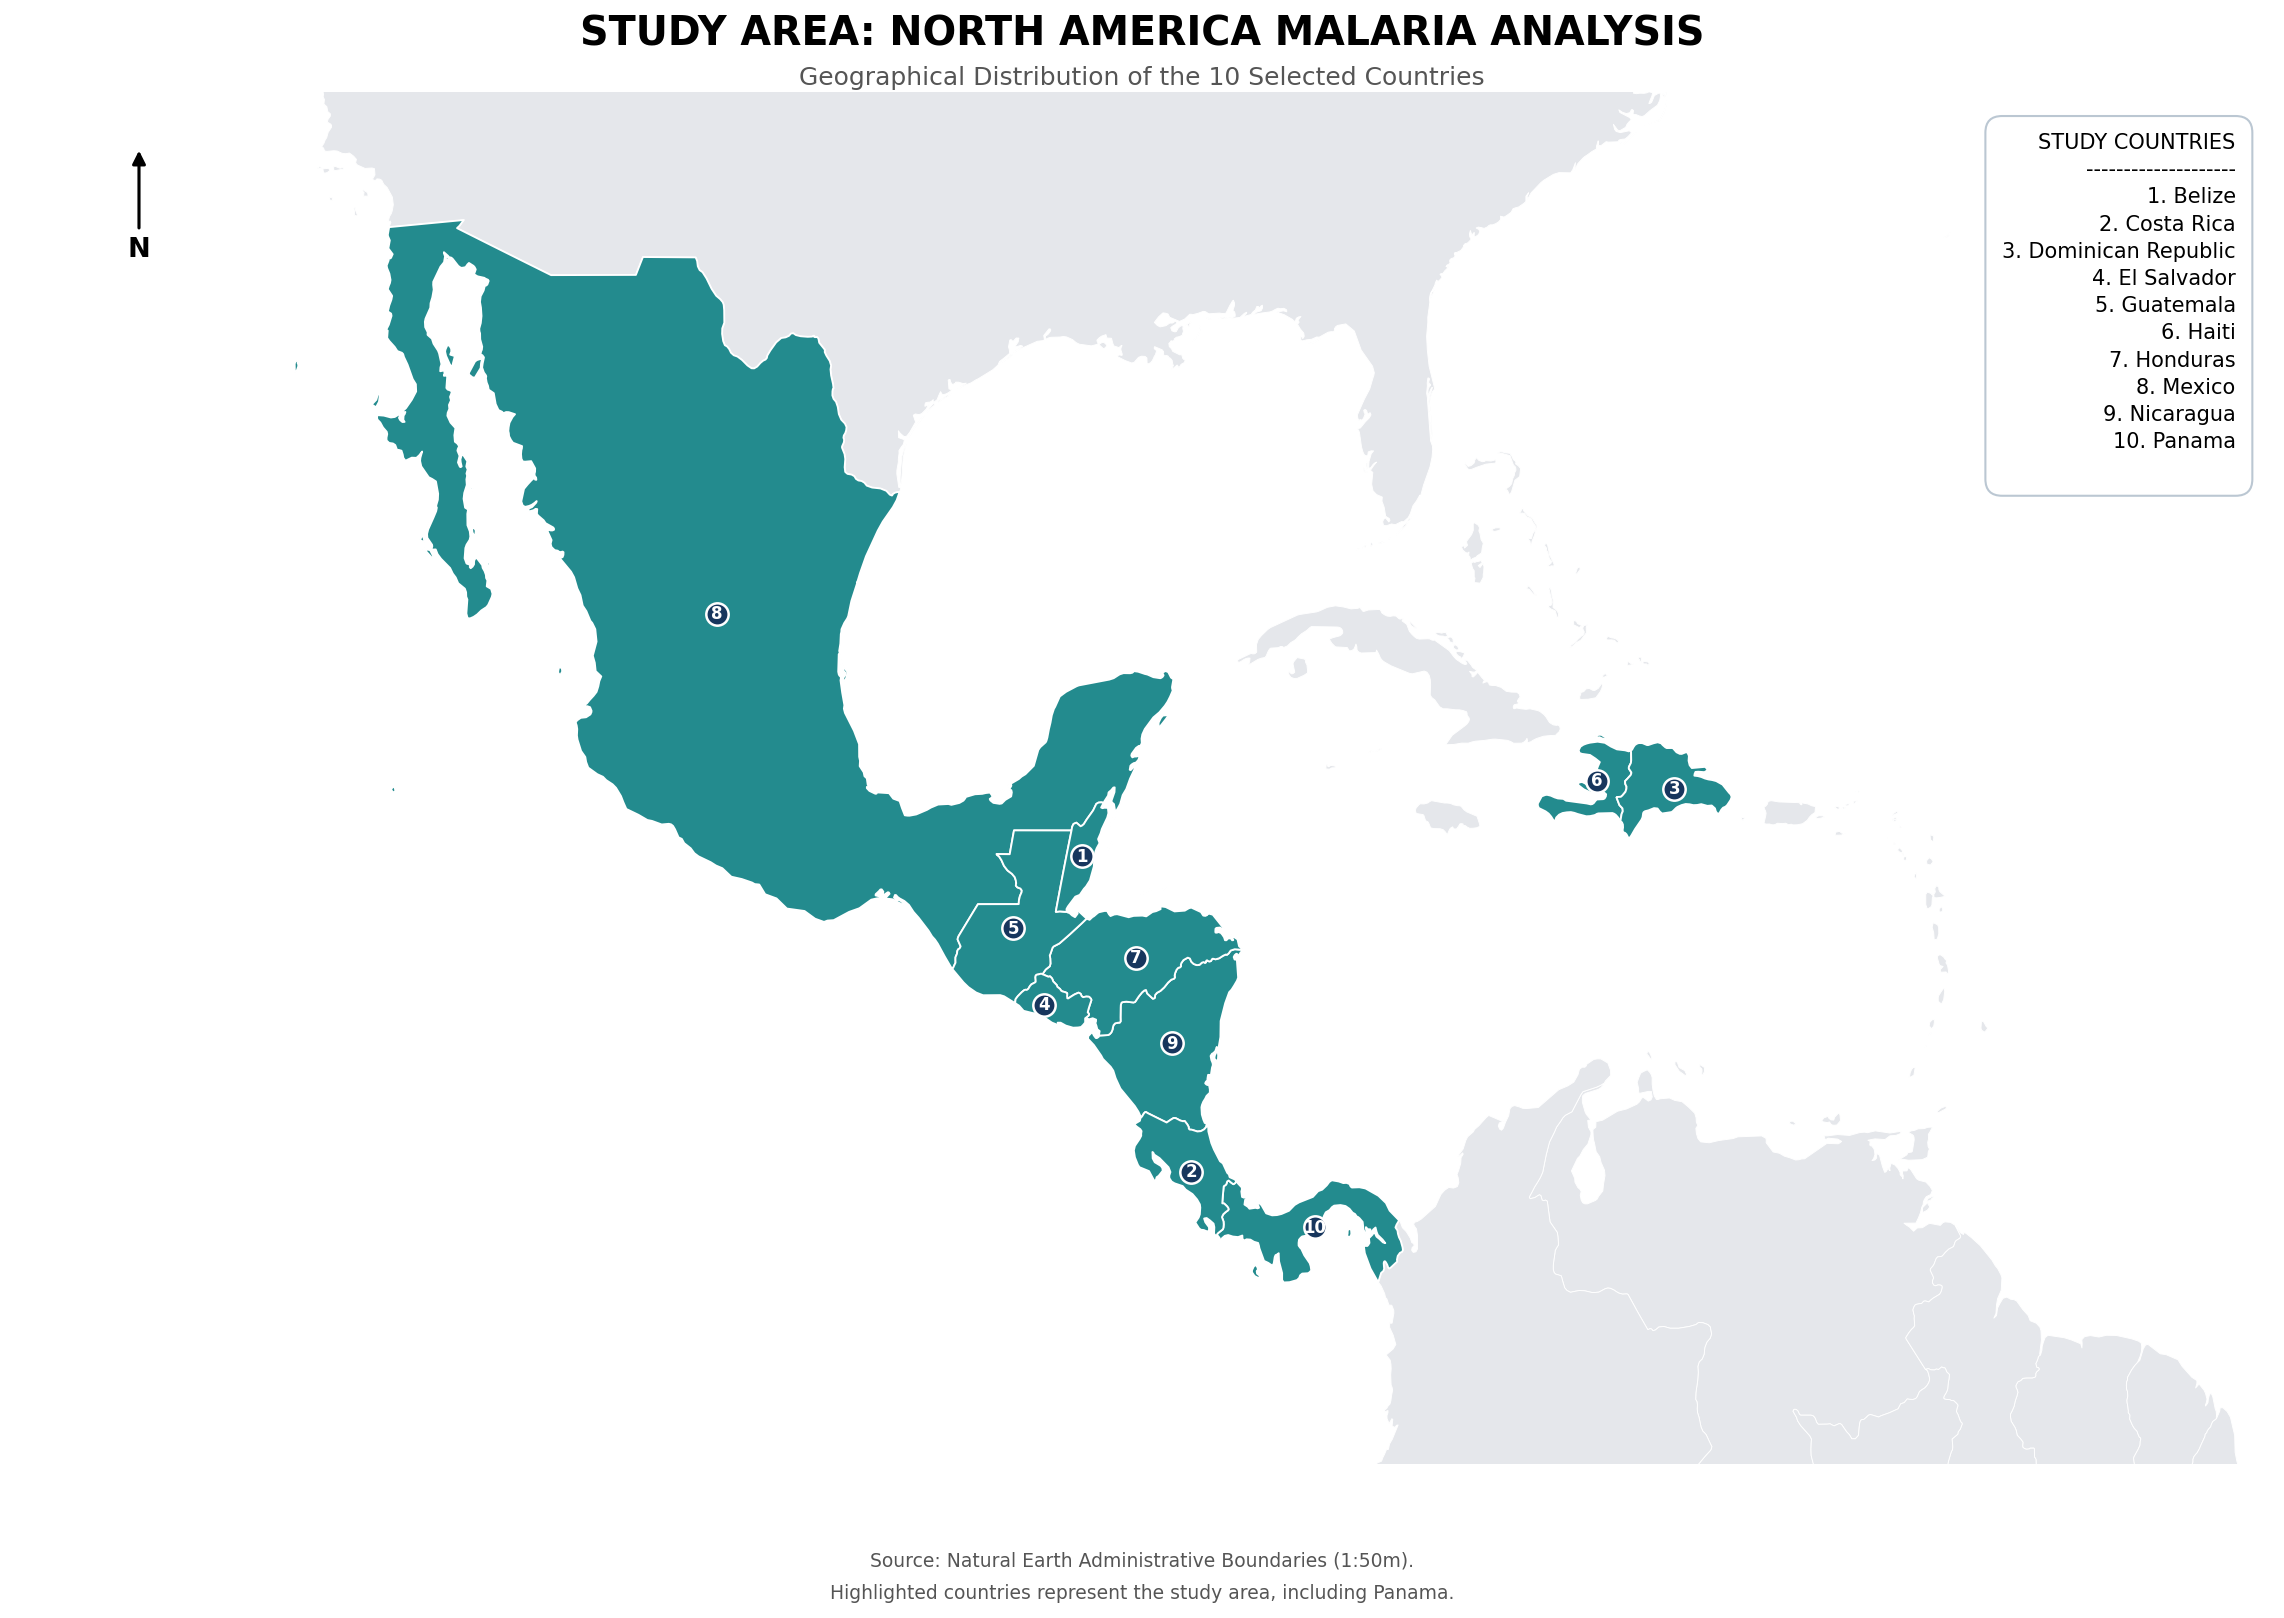

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STUDY AREA MAP CREATED SUCCESSFULLY!
Total Countries: 10


In [ ]:

# ============================================================
# NORTH AMERICA MALARIA RESEARCH
# STUDY AREA MAP - 10 COUNTRIES INCLUDING PANAMA
# PUBLICATION QUALITY MAP
# ============================================================

!pip -q install geopandas matplotlib requests

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from shapely.geometry import box

# ============================================================
# 1. SELECT STUDY COUNTRIES
# ============================================================

study_countries = [
    'Belize',
    'Costa Rica',
    'Dominican Republic',
    'El Salvador',
    'Guatemala',
    'Haiti',
    'Honduras',
    'Mexico',
    'Nicaragua',
    'Panama'
]

# ============================================================
# 2. DOWNLOAD WORLD MAP SHAPE DATA
# ============================================================

url = (
    'https://raw.githubusercontent.com/'
    'nvkelso/natural-earth-vector/master/'
    'geojson/ne_50m_admin_0_countries.geojson'
)

response = requests.get(url, timeout=60)

response.raise_for_status()

geojson = response.json()

world = gpd.GeoDataFrame.from_features(
    geojson['features'],
    crs='EPSG:4326'
)

# Find country name column

name_col = next(
    (c for c in ['ADMIN', 'NAME', 'NAME_EN']
     if c in world.columns),
    None
)

if name_col is None:
    raise ValueError("Country name field not found.")

# ============================================================
# 3. CHECK ALL COUNTRIES
# ============================================================

available = set(world[name_col].astype(str))

missing = [
    country for country in study_countries
    if country not in available
]

if missing:
    raise ValueError(
        f"Countries not found in map data: {missing}"
    )

study = world[
    world[name_col].isin(study_countries)
].copy()

print("STUDY AREA INFORMATION")
print("=======================")

print("Total countries:", len(study_countries))

print("Countries mapped:", len(study))

print("Panama included:", 'Panama' in study[name_col].values)

# ============================================================
# 4. PROJECT MAP
# ============================================================

# Equal Earth projection for research mapping

world_map = world.to_crs('EPSG:8857')

study_map = study.to_crs('EPSG:8857')

# ============================================================
# 5. CREATE NUMBERED COUNTRY LOCATIONS
# ============================================================

country_coordinates = {

    'Mexico': (-102.0, 23.0),

    'Belize': (-88.7, 17.2),

    'Guatemala': (-90.5, 15.5),

    'El Salvador': (-89.2, 13.7),

    'Honduras': (-86.5, 14.8),

    'Nicaragua': (-85.0, 12.8),

    'Costa Rica': (-84.0, 9.8),

    'Panama': (-80.0, 8.5),

    'Haiti': (-72.7, 19.0),

    'Dominican Republic': (-70.2, 18.8)

}

points = gpd.GeoDataFrame(

    {
        'Number': range(1, 11),

        'Country': study_countries

    },

    geometry=gpd.points_from_xy(

        [country_coordinates[c][0] for c in study_countries],

        [country_coordinates[c][1] for c in study_countries]

    ),

    crs='EPSG:4326'

).to_crs('EPSG:8857')

# ============================================================
# 6. MAP EXTENT
# ============================================================

region_box = gpd.GeoSeries(

    [box(-120, 3, -55, 36)],

    crs='EPSG:4326'

).to_crs('EPSG:8857').iloc[0]

minx, miny, maxx, maxy = region_box.bounds

# ============================================================
# 7. CREATE RESEARCH MAP
# ============================================================

fig, ax = plt.subplots(

    figsize=(16, 11),

    dpi=150

)

fig.patch.set_facecolor('white')

ax.set_facecolor('#EAF3F8')

# Background countries

world_map.plot(

    ax=ax,

    color='#E5E7EB',

    edgecolor='white',

    linewidth=0.45,

    zorder=1

)

# Highlight study countries

study_map.plot(

    ax=ax,

    color='#238B8E',

    edgecolor='white',

    linewidth=0.9,

    zorder=3

)

# ============================================================
# 8. ADD NUMBERED COUNTRY MARKERS
# ============================================================

ax.scatter(

    points.geometry.x,

    points.geometry.y,

    s=115,

    color='#17365D',

    edgecolor='white',

    linewidth=1.2,

    zorder=5

)

for _, row in points.iterrows():

    ax.text(

        row.geometry.x,

        row.geometry.y,

        str(row['Number']),

        color='white',

        fontsize=8,

        fontweight='bold',

        ha='center',

        va='center',

        zorder=6

    )

# ============================================================
# 9. COUNTRY LEGEND
# ============================================================

legend_text = (
    "STUDY COUNTRIES\n"
    "--------------------\n"
)

for i, country in enumerate(study_countries, 1):

    legend_text += f"{i}. {country}\n"

ax.text(

    0.985,

    0.97,

    legend_text,

    transform=ax.transAxes,

    fontsize=10,

    verticalalignment='top',

    horizontalalignment='right',

    fontweight='medium',

    linespacing=1.45,

    bbox=dict(

        boxstyle='round,pad=0.8',

        facecolor='white',

        edgecolor='#B8C5D1',

        alpha=0.96

    ),

    zorder=10

)

# ============================================================
# 10. NORTH ARROW
# ============================================================

ax.annotate(

    'N',

    xy=(0.055, 0.96),

    xytext=(0.055, 0.88),

    xycoords='axes fraction',

    textcoords='axes fraction',

    ha='center',

    fontsize=13,

    fontweight='bold',

    arrowprops=dict(

        arrowstyle='-|>',

        color='black',

        lw=1.5

    )

)

# ============================================================
# 11. MAP TITLE
# ============================================================

ax.set_title(

    'STUDY AREA: NORTH AMERICA MALARIA ANALYSIS',

    fontsize=19,

    fontweight='bold',

    pad=22

)

ax.text(

    0.5,

    1.005,

    'Geographical Distribution of the 10 Selected Countries',

    transform=ax.transAxes,

    ha='center',

    fontsize=12,

    color='#555555'

)

# ============================================================
# 12. MAP BOUNDARIES
# ============================================================

ax.set_xlim(minx, maxx)

ax.set_ylim(miny, maxy)

ax.set_aspect('equal')

ax.axis('off')

# ============================================================
# 13. SOURCE AND FOOTNOTE
# ============================================================

fig.text(

    0.5,

    0.035,

    'Source: Natural Earth Administrative Boundaries (1:50m).',

    ha='center',

    fontsize=9,

    color='#555555'

)

fig.text(

    0.5,

    0.015,

    'Highlighted countries represent the study area, including Panama.',

    ha='center',

    fontsize=9,

    color='#555555'

)

# ============================================================
# 14. SAVE MAP
# ============================================================

plt.tight_layout(
    rect=[0.02, 0.07, 0.98, 0.96]
)

plt.savefig(

    'North_America_Malaria_Study_Area.png',

    dpi=600,

    bbox_inches='tight',

    facecolor='white'

)

plt.savefig(

    'North_America_Malaria_Study_Area.pdf',

    bbox_inches='tight',

    facecolor='white'

)

plt.show()

# ============================================================
# 15. DOWNLOAD
# ============================================================

from google.colab import files

files.download(
    'North_America_Malaria_Study_Area.png'
)

files.download(
    'North_America_Malaria_Study_Area.pdf'
)

print("\nSTUDY AREA MAP CREATED SUCCESSFULLY!")
print("Total Countries:", len(study_countries))



FORECAST VALUES USED IN MAP


,Country,ZINB_Forecasted_Cases,Map_Value
0,Belize,16.275,16.275
1,Costa Rica,83.332,83.332
2,Dominican Republic,413.733,413.733
3,El Salvador,66.916,66.916
4,Guatemala,2679.662,2679.662
5,Haiti,4483.920,4483.920
6,Honduras,1489.837,1489.837
7,Mexico,320.282,320.282
8,Nicaragua,12253.112,12253.112
9,Panama,1189.983,1189.983


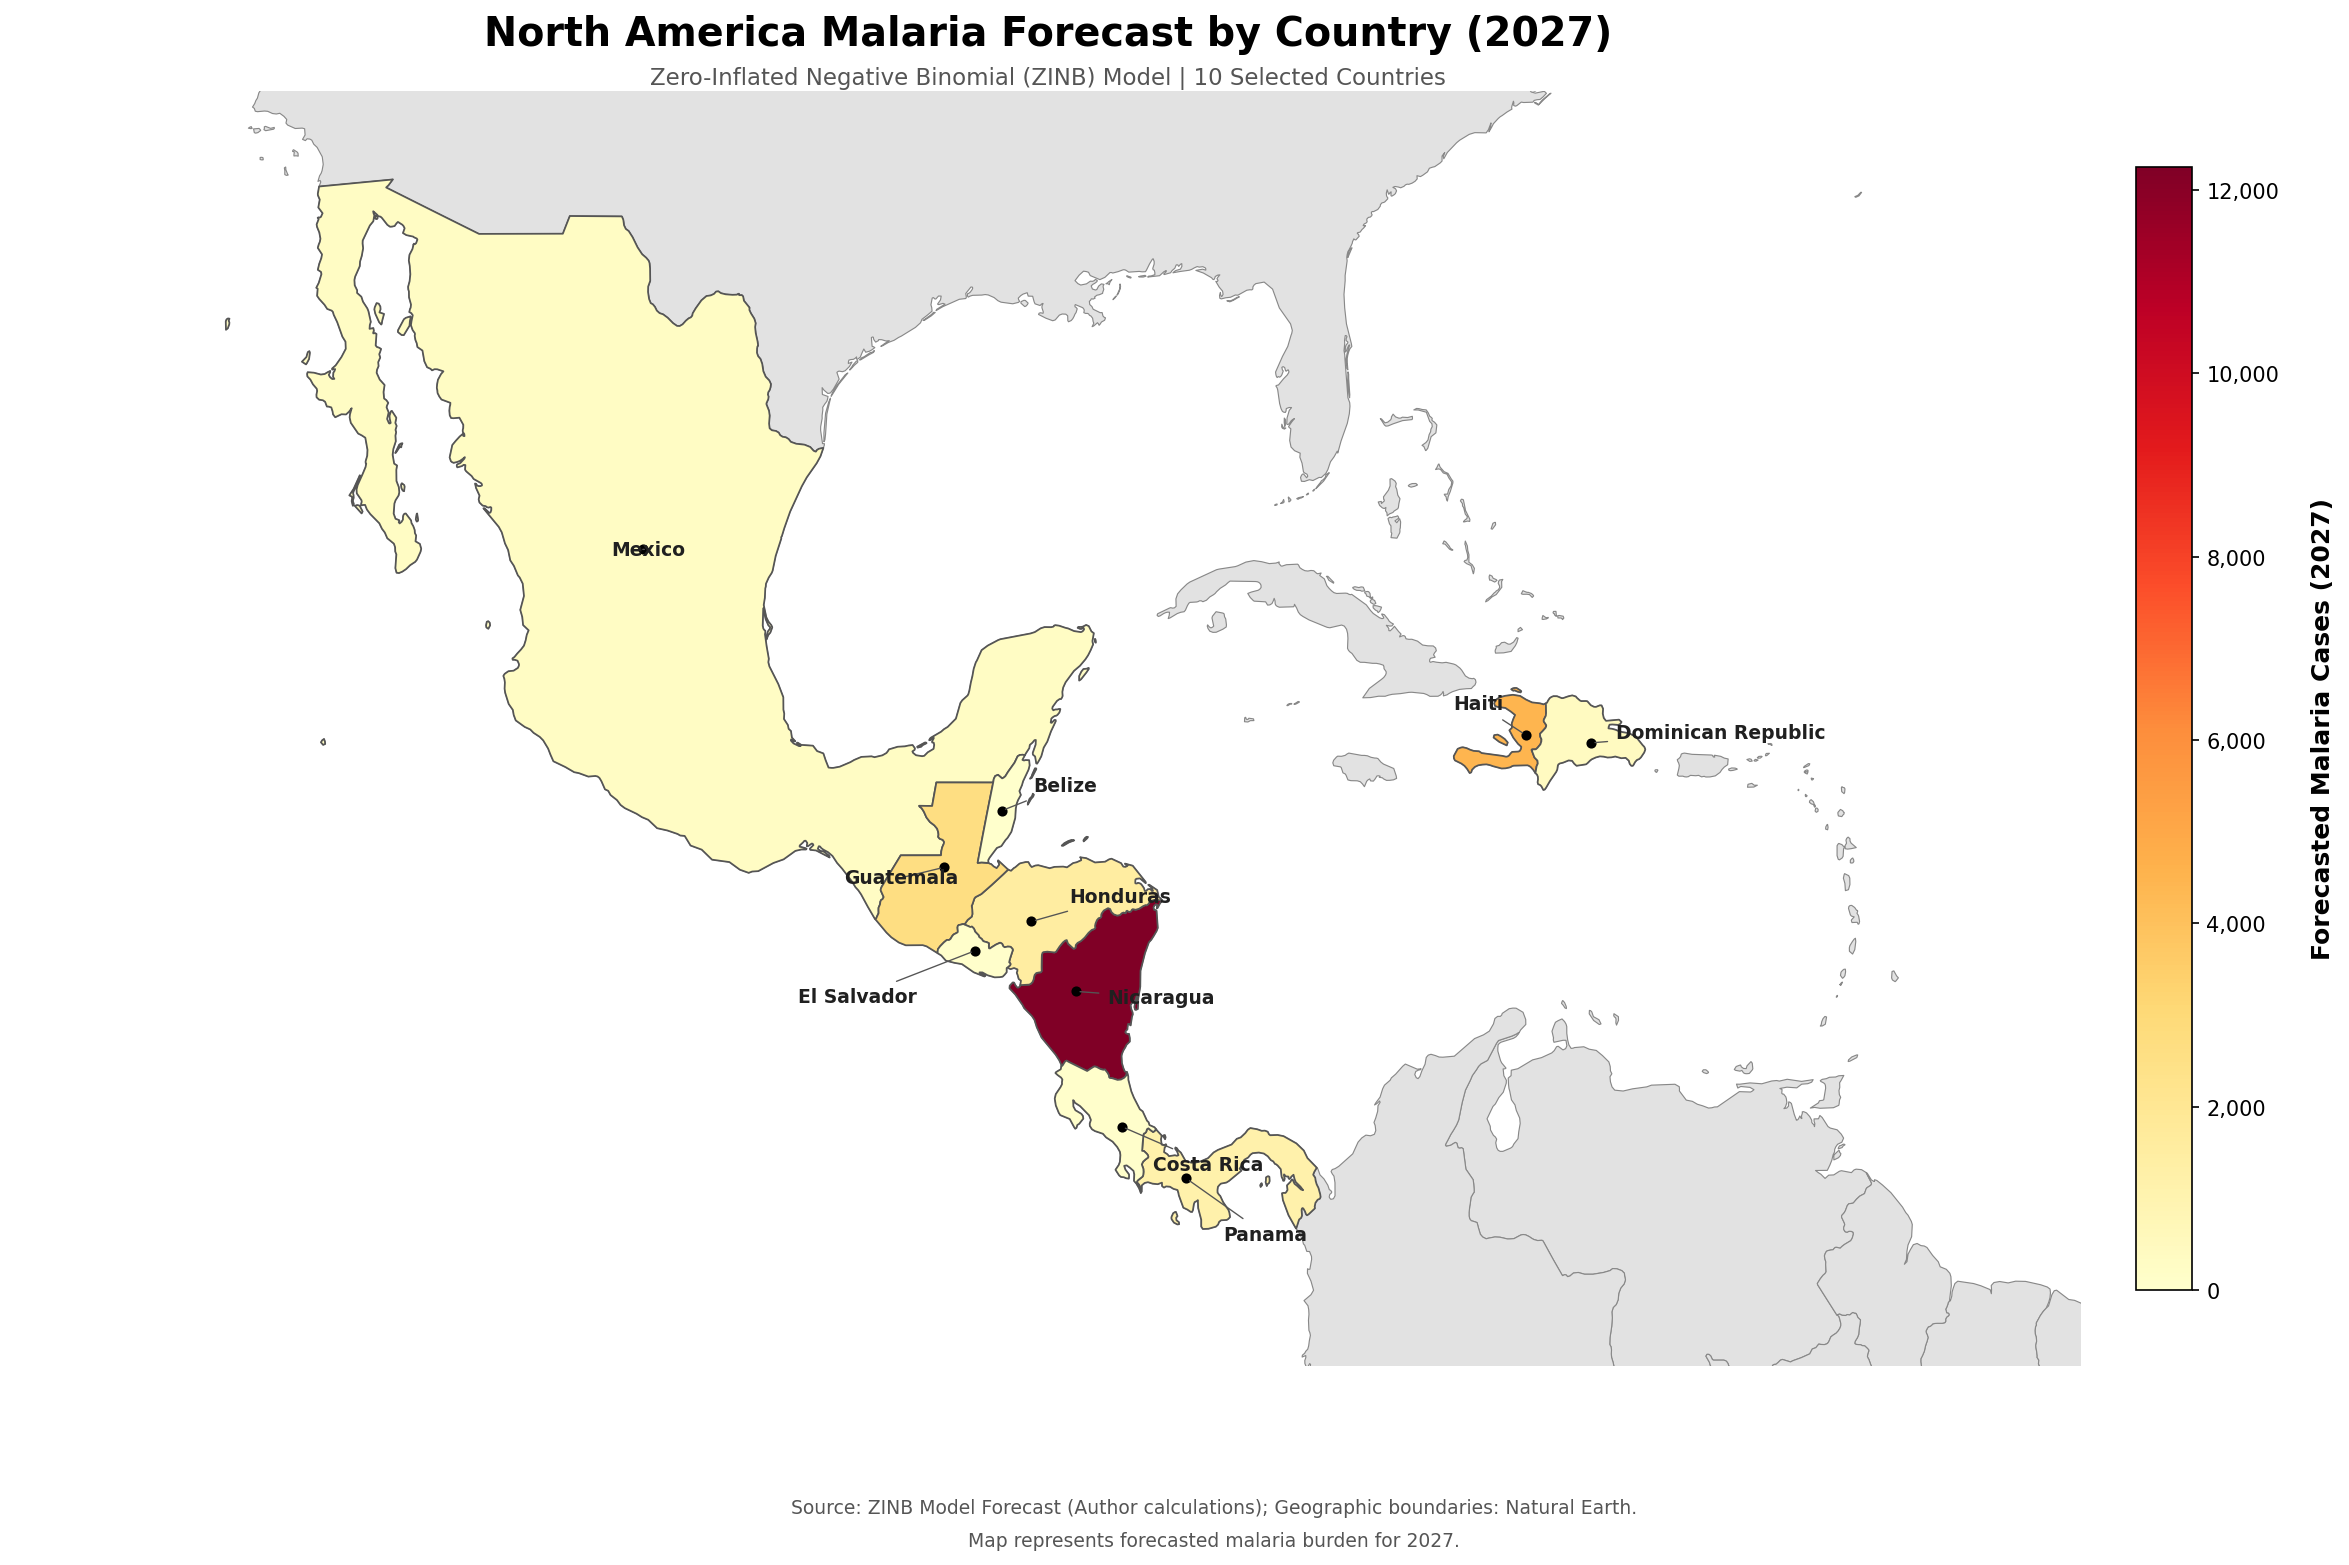

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


MAP CREATED SUCCESSFULLY!
Forecast year: 2027
Countries mapped: 10
Panama included: True
Map metric: cases


In [ ]:

# ============================================================
# NORTH AMERICA MALARIA FORECAST CHOROPLETH MAP
# ZINB FORECAST: 2023-2027
# 10 COUNTRIES INCLUDING PANAMA
# ============================================================

!pip -q install geopandas matplotlib requests

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from shapely.geometry import box
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FuncFormatter
from google.colab import files

# ============================================================
# 1. MAP SETTINGS
# ============================================================

MAP_YEAR = 2027

# Choose:
# "cases" = Total forecasted malaria cases
# "per_1000_population" = Forecasted cases per 1,000 total population

MAP_METRIC = "cases"

study_countries = [
    'Belize',
    'Costa Rica',
    'Dominican Republic',
    'El Salvador',
    'Guatemala',
    'Haiti',
    'Honduras',
    'Mexico',
    'Nicaragua',
    'Panama'
]

# ============================================================
# 2. GET ZINB FORECAST DATA
# ============================================================

forecast_col = 'ZINB_Forecasted_Cases'

if forecast_col not in future_forecast.columns:
    raise ValueError(
        "ZINB_Forecasted_Cases column not found."
    )

forecast_data = future_forecast[
    future_forecast['Year'] == MAP_YEAR
].copy()

forecast_data = forecast_data.groupby(
    'Country',
    as_index=False
)[forecast_col].sum()

# Check all countries

missing_countries = (
    set(study_countries) -
    set(forecast_data['Country'])
)

if missing_countries:
    raise ValueError(
        f"Missing forecast data: {missing_countries}"
    )

# ============================================================
# 3. CALCULATE MAP VALUES
# ============================================================

if MAP_METRIC == "cases":

    forecast_data['Map_Value'] = (
        forecast_data[forecast_col]
    )

    colorbar_label = (
        f'Forecasted Malaria Cases ({MAP_YEAR})'
    )

elif MAP_METRIC == "per_1000_population":

    if 'future_data' not in globals():
        raise ValueError(
            "Future population data is required."
        )

    population_data = future_data[
        future_data['Year'] == MAP_YEAR
    ][['Country', 'y7']].copy()

    forecast_data = forecast_data.merge(
        population_data,
        on='Country',
        how='left',
        validate='one_to_one'
    )

    if forecast_data['y7'].isna().any():
        raise ValueError("Missing future population values.")

    forecast_data['Map_Value'] = (
        forecast_data[forecast_col] /
        forecast_data['y7'] * 1000
    )

    colorbar_label = (
        f'Forecasted Cases per 1,000 Total Population ({MAP_YEAR})'
    )

else:

    raise ValueError(
        "MAP_METRIC must be cases or per_1000_population."
    )

print("\nFORECAST VALUES USED IN MAP")

display(
    forecast_data[
        ['Country', forecast_col, 'Map_Value']
    ].round(3)
)

# ============================================================
# 4. DOWNLOAD NATURAL EARTH MAP
# ============================================================

url = (
    'https://raw.githubusercontent.com/'
    'nvkelso/natural-earth-vector/master/'
    'geojson/ne_50m_admin_0_countries.geojson'
)

response = requests.get(
    url,
    timeout=60
)

response.raise_for_status()

geojson = response.json()

world = gpd.GeoDataFrame.from_features(
    geojson['features'],
    crs='EPSG:4326'
)

# Identify country name field

name_col = next(
    (
        c for c in ['ADMIN', 'NAME', 'NAME_EN']
        if c in world.columns
    ),
    None
)

if name_col is None:
    raise ValueError("Country name column not found.")

world = world.rename(
    columns={name_col: 'Country'}
)

# ============================================================
# 5. MERGE FORECAST DATA WITH MAP
# ============================================================

map_data = world.merge(
    forecast_data[['Country', 'Map_Value']],
    on='Country',
    how='left'
)

study_map = map_data[
    map_data['Country'].isin(study_countries)
].copy()

if len(study_map) != 10:
    raise ValueError(
        "Not all 10 countries were found in the map."
    )

if study_map['Map_Value'].isna().any():
    raise ValueError(
        "Missing forecast values in selected countries."
    )

# ============================================================
# 6. PROJECT MAP
# ============================================================

world_proj = map_data.to_crs('EPSG:8857')

study_proj = study_map.to_crs('EPSG:8857')

# Map extent: Mexico, Central America and Caribbean

region = gpd.GeoSeries(
    [box(-118, 4, -58, 35)],
    crs='EPSG:4326'
).to_crs('EPSG:8857').iloc[0]

minx, miny, maxx, maxy = region.bounds

# ============================================================
# 7. COLOR SCALE
# ============================================================

max_value = study_proj['Map_Value'].max()

if not np.isfinite(max_value) or max_value <= 0:
    raise ValueError("Invalid forecast values for color scale.")

norm = Normalize(
    vmin=0,
    vmax=max_value
)

cmap = plt.get_cmap('YlOrRd')

# ============================================================
# 8. CREATE MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(17, 11),
    dpi=150
)

fig.patch.set_facecolor('white')

ax.set_facecolor('#EAF4FA')

# Background countries

world_proj.plot(
    ax=ax,
    color='#E2E2E2',
    edgecolor='#888888',
    linewidth=0.55,
    zorder=1
)

# Highlight 10 study countries based on ZINB forecasts

study_proj.plot(
    ax=ax,
    column='Map_Value',
    cmap=cmap,
    norm=norm,
    edgecolor='#555555',
    linewidth=0.85,
    zorder=3
)

# ============================================================
# 9. ADD COUNTRY MARKERS AND LABELS
# ============================================================

label_offsets = {

    'Mexico': (-15, 0),

    'Belize': (15, 12),

    'Guatemala': (-48, -5),

    'El Salvador': (-85, -22),

    'Honduras': (18, 12),

    'Nicaragua': (15, -3),

    'Costa Rica': (15, -18),

    'Panama': (18, -27),

    'Haiti': (-35, 15),

    'Dominican Republic': (12, 5)

}

label_points = study_proj.copy()

label_points.geometry = (
    label_points.geometry.representative_point()
)

for _, row in label_points.iterrows():

    country = row['Country']

    x = row.geometry.x

    y = row.geometry.y

    dx, dy = label_offsets[country]

    # Country location marker

    ax.scatter(
        x,
        y,
        color='black',
        s=15,
        zorder=6
    )

    # Country name

    ax.annotate(

        country,

        xy=(x, y),

        xytext=(dx, dy),

        textcoords='offset points',

        fontsize=9,

        fontweight='bold',

        color='#202020',

        ha='left',

        va='center',

        arrowprops=dict(
            arrowstyle='-',
            color='#555555',
            lw=0.65
        ),

        annotation_clip=False,

        zorder=7

    )

# ============================================================
# 10. ADD CONTINUOUS COLORBAR
# ============================================================

sm = ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025,
    shrink=0.80
)

cbar.set_label(
    colorbar_label,
    fontsize=12,
    fontweight='bold',
    labelpad=15
)

cbar.ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f'{x:,.0f}'
    )
)

cbar.ax.tick_params(
    labelsize=10
)

# ============================================================
# 11. TITLE AND SUBTITLE
# ============================================================

ax.set_title(

    f'North America Malaria Forecast by Country ({MAP_YEAR})',

    fontsize=19,

    fontweight='bold',

    pad=22

)

ax.text(

    0.5,

    1.005,

    'Zero-Inflated Negative Binomial (ZINB) Model | 10 Selected Countries',

    transform=ax.transAxes,

    ha='center',

    fontsize=11,

    color='#555555'

)

# ============================================================
# 12. MAP EXTENT AND APPEARANCE
# ============================================================

ax.set_xlim(minx, maxx)

ax.set_ylim(miny, maxy)

ax.set_aspect('equal')

ax.axis('off')

# ============================================================
# 13. SOURCE
# ============================================================

fig.text(

    0.5,

    0.035,

    'Source: ZINB Model Forecast (Author calculations); Geographic boundaries: Natural Earth.',

    ha='center',

    fontsize=9,

    color='#555555'

)

fig.text(

    0.5,

    0.015,

    f'Map represents forecasted malaria burden for {MAP_YEAR}.',

    ha='center',

    fontsize=9,

    color='#555555'

)

# ============================================================
# 14. SAVE HIGH-RESOLUTION MAP
# ============================================================

plt.tight_layout(
    rect=[0.02, 0.07, 0.95, 0.96]
)

filename = f'ZINB_Malaria_Forecast_Map_{MAP_YEAR}'

plt.savefig(
    filename + '.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

plt.savefig(
    filename + '.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

# ============================================================
# 15. DOWNLOAD
# ============================================================

files.download(filename + '.png')

files.download(filename + '.pdf')

print("\nMAP CREATED SUCCESSFULLY!")
print("Forecast year:", MAP_YEAR)
print("Countries mapped:", len(study_proj))
print("Panama included:", 'Panama' in study_proj['Country'].values)
print("Map metric:", MAP_METRIC)


Total variables: 18
Total observations: 230


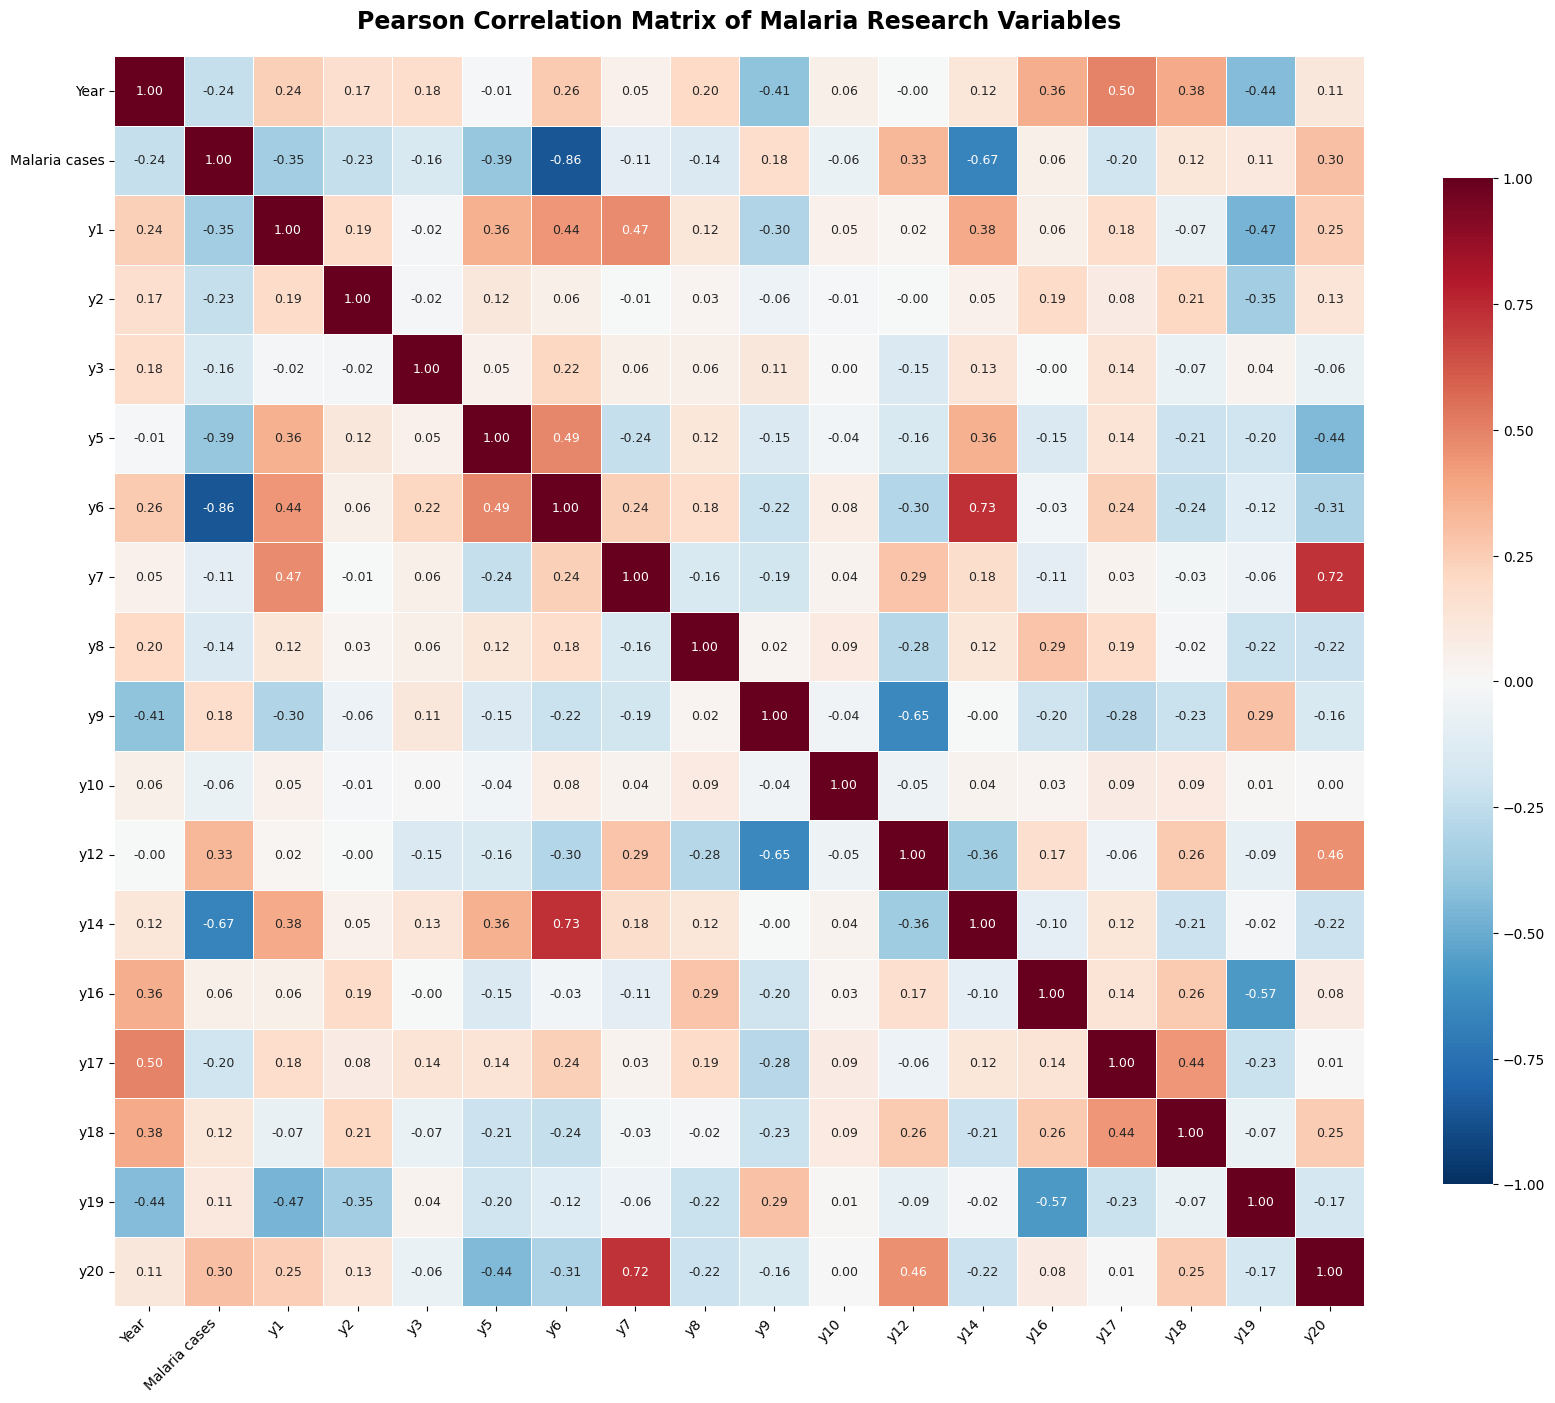

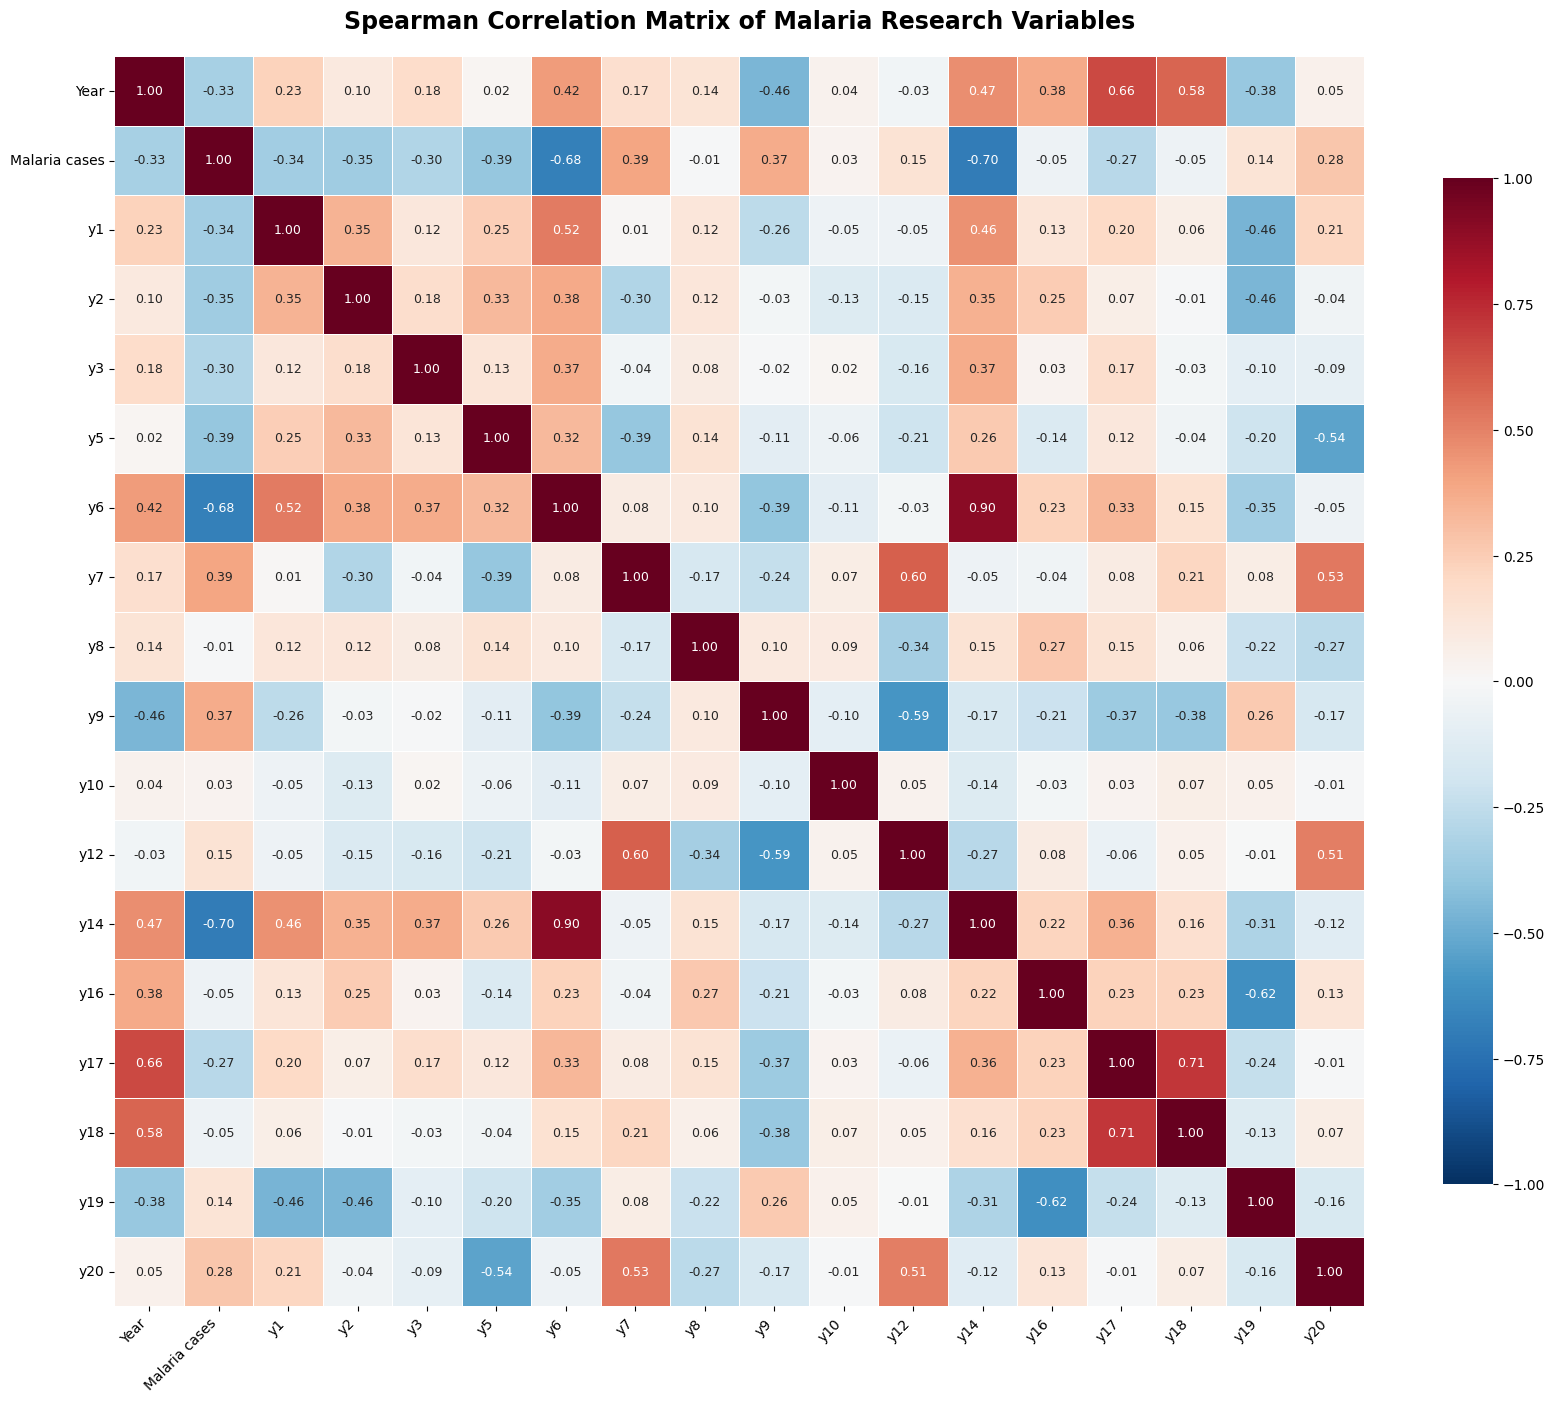

CORRELATION ANALYSIS COMPLETED!


In [ ]:

# ============================================================
# CORRELATION ANALYSIS & HEATMAP
# MALARIA FORECASTING - NORTH AMERICA INCLUDING PANAMA
# ALL RESEARCH VARIABLES
# ============================================================

!pip -q install pandas openpyxl seaborn matplotlib

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files


# ============================================================
# 2. SELECT ALL RESEARCH VARIABLES
# ============================================================

variables = [
    'Year',
    'Malaria cases',
    'y1', 'y2', 'y3',
    'y5', 'y6', 'y7',
    'y8', 'y9', 'y10',
    'y12', 'y14', 'y16',
    'y17', 'y18', 'y19', 'y20'
]

# Check missing columns
missing = [col for col in variables if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns in dataset: {missing}")

# Select variables
corr_data = df[variables].copy()

# Convert to numeric
for col in variables:
    corr_data[col] = pd.to_numeric(
        corr_data[col],
        errors='coerce'
    )

corr_data = corr_data.replace(
    [np.inf, -np.inf], np.nan
)

# Remove columns having no variation
constant_cols = [
    col for col in corr_data.columns
    if corr_data[col].nunique(dropna=True) <= 1
]

if constant_cols:
    print("Constant variables removed:", constant_cols)
    corr_data = corr_data.drop(columns=constant_cols)

print("Total variables:", len(corr_data.columns))
print("Total observations:", len(corr_data))

# ============================================================
# 3. PEARSON CORRELATION
# ============================================================

pearson_corr = corr_data.corr(
    method='pearson',
    min_periods=3
)

plt.figure(figsize=(17, 14))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    annot_kws={'size': 9},
    cbar_kws={'shrink': 0.8}
)

plt.title(
    'Pearson Correlation Matrix of Malaria Research Variables',
    fontsize=17,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

plt.savefig(
    'Pearson_Correlation_Heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 4. SPEARMAN CORRELATION
# ============================================================

spearman_corr = corr_data.corr(
    method='spearman',
    min_periods=3
)

plt.figure(figsize=(17, 14))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    annot_kws={'size': 9},
    cbar_kws={'shrink': 0.8}
)

plt.title(
    'Spearman Correlation Matrix of Malaria Research Variables',
    fontsize=17,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

plt.savefig(
    'Spearman_Correlation_Heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 5. SAVE CORRELATION RESULTS
# ============================================================

with pd.ExcelWriter(
    'Malaria_Correlation_Results.xlsx'
) as writer:

    pearson_corr.to_excel(
        writer,
        sheet_name='Pearson'
    )

    spearman_corr.to_excel(
        writer,
        sheet_name='Spearman'
    )



print("CORRELATION ANALYSIS COMPLETED!")
